In [ ]:
import numpy as np
import healpy as hp

import matplotlib
from matplotlib import pyplot as plt

from scipy import stats
import matplotlib.gridspec as gridspec
import astropy.cosmology.units as cu
import astropy.units as u
import site
site.addsitedir('/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts') 
import quaia
import sampler
import seaborn as sns
from matplotlib.colors import LogNorm
import matplotlib.patches as mpatches
import pyccl as ccl
from matplotlib.lines import Line2D
from matplotlib import cm
from scipy.optimize import minimize
from astropy.cosmology import Planck18
from dynesty import NestedSampler
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc
from astropy.coordinates import SkyCoord
from scipy import linalg
from scipy.special import gamma
from dynesty.results import Results
import io
from PIL import Image
from scipy.special import j0
import mcfit
from astropy import constants
import time
import copy
from scipy import special
from healpy.newvisufunc import projview
from scipy.special import sici, exp1
import matplotlib.colors as mcolors
import pickle

In [2]:
matplotlib.rcParams['ytick.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 18
matplotlib.rcParams['axes.labelsize'] = 22
matplotlib.rcParams['legend.fontsize'] = 18
matplotlib.rcParams['axes.titlesize'] = 20

# Convergence criterion
## Define parameters

In [ ]:
G_hi = 20.5 #20.5

In [4]:
z_bins = np.array([0.0, 1.0, 2.0, 3.0, 4.6])
z_array = range(len(z_bins)-1)

In [5]:
n_bins = 201

In [6]:
L_bins = np.array([-32.0, -27.0, -26.0, -25.0, -20.0])[:0:-1]
L_bins

array([-20., -25., -26., -27.])

In [7]:
b = 30

In [8]:
fac_rand = 25

In [9]:
cmap_theta = sns.color_palette("flare_r", n_colors = len(L_bins))
cmap_theta

[(0.47936222, 0.18006056, 0.43733022),
 (0.66635279, 0.22717328, 0.43008427),
 (0.83765537, 0.30784814, 0.3723105),
 (0.90732341, 0.4939774, 0.38990532)]

In [10]:
mass_def = '200c'
hmf = ccl.halos.MassFuncTinker10(mass_def = mass_def) 

In [11]:
cosmo_planck18 = ccl.Cosmology(
    Omega_c=Planck18.Odm0,
    Omega_b=Planck18.Ob0,
    h=Planck18.h,
    Neff=Planck18.Neff,
    T_CMB=Planck18.Tcmb0.value,
    m_nu=Planck18.m_nu,
    sigma8=0.8102,   # or pull from wherever your actual source specifies Planck18's sigma8
    n_s=0.9665        # same
)

## Define functions

In [12]:
def M(bins, n_m, a = 1, cosmo = cosmo_planck18, mod = False, recenter = True, hmf = hmf, units = '(h/Mpc)^3'):

    n_g, nm = sampler.n_g_theory(bins, n_m, a = a, cosmo = cosmo, recenter = recenter, hmf = hmf, units = units)
    if recenter == True:
        n_g = np.trapz(n_g, quaia.recenter(bins))
        dm = np.diff(bins) 
        dn_dm = nm/(quaia.recenter(bins)*np.log(10))
    else:
        n_g = np.trapz(n_g, bins)
        dn_dm = nm/(bins*np.log(10))

    n_m[~np.isfinite(n_m)]=0 
    integrand = dn_dm*n_m
    integrand[np.isnan(integrand)]=0
    
    if recenter == True:
        return sampler.bias_function(n_g, integrand, quaia.recenter(bins), bins, recenter = recenter), n_g
    else:
        return sampler.bias_function(n_g, integrand, bins, bins, recenter = recenter), n_g

## Calculate number density as $n_q \approx \int_0^{\infty} d M \frac{d n}{d M}\langle N(M)\rangle$

In [13]:
LMC = SkyCoord(['05 23 34.6 -69 45 22'], unit=(u.hourangle, u.deg)) #https://simbad.u-strasbg.fr/simbad/sim-id?Ident=Large+Magellanic+Cloud

In [14]:
LMC_radius = 9*u.deg

In [15]:
SMC = SkyCoord(['00 52 38.0 -72 48 01'], unit=(u.hourangle, u.deg)) # https://simbad.u-strasbg.fr/simbad/sim-id?Ident=small+Magellanic+Cloud

In [16]:
SMC_radius = 5*u.deg

In [17]:
NSIDE = 64

In [18]:
NPIX = hp.nside2npix(NSIDE)

In [19]:
theta, phi = hp.pix2ang(NSIDE, range(NPIX), lonlat=True)
c = SkyCoord(ra=theta*u.degree, dec=phi*u.degree)
LMC_idx, _, _, _ = SkyCoord.search_around_sky(LMC, c, LMC_radius)
SMC_idx, _, _, _ = SkyCoord.search_around_sky(SMC, c, SMC_radius)
MC_idx = np.append(LMC_idx,SMC_idx)
MC_mask = np.full_like(range(NPIX), True, dtype = bool)
MC_mask[MC_idx] = False

In [20]:
selfunc_mask = np.abs(c.galactic.b.value)>=b

In [21]:
dz = np.linspace(0, 4.6)

In [22]:
da = 1/(1+dz)

In [23]:
N_q, n_q = {L: [] for L in L_bins}, {L: [] for L in L_bins}
H0_c_dN_dz_norm = {L: [] for L in L_bins}
z_sigma = {L: [] for L in L_bins}

for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          n_bins = [None, None], b = b, mask_type = 'b')
        N = len(tab_datahi_mask_zbin0)
        f_sky = 1/(4*np.pi)*np.sum(selfunc_hi_bin0[selfunc_mask & MC_mask]*hp.nside2pixarea(NSIDE))
        V = f_sky*(Planck18.comoving_volume(z_bins[j+1])-Planck18.comoving_volume(z_bins[j]))*Planck18.h**3/u.h**3
        N_q[L_bins[i]].append(N)
        n_q[L_bins[i]].append(N/V.value)

        dN_dz = np.sum(stats.norm.pdf(dz[None, :], loc=tab_datahi_mask_zbin0['redshift_quaia'][:, None], scale=tab_datahi_mask_zbin0['redshift_quaia_err'][:, None]), axis = 0)
        dN_dz /= np.sum(stats.norm.cdf(dz[-1], loc=tab_datahi_mask_zbin0['redshift_quaia'], scale=tab_datahi_mask_zbin0['redshift_quaia_err']))
        H0_c_dN_dz_norm[L_bins[i]].append(ccl.background.h_over_h0(
            cosmo_planck18, da)*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*dN_dz**2)

        z_sigma[L_bins[i]].append(np.percentile(tab_datahi_mask_zbin0['redshift_quaia'], [16, 84]))

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 490
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.46              29985 vs 55261
Pixels masked by MC but not already by selfunc: 3840
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.33              336125 vs 502242
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-25.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-25.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 1

## Limit angular scales to $0.001^\circ\geq \theta \geq 10^\circ$

In [24]:
# Create the bins array
rmin = 0.001
rmax = 10.0
nbins = 30 #20 #30 #20
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1)
np.log10(thetabins), quaia.recenter(np.log10(thetabins)), np.diff(np.log10(thetabins))

(array([-3.        , -2.86666667, -2.73333333, -2.6       , -2.46666667,
        -2.33333333, -2.2       , -2.06666667, -1.93333333, -1.8       ,
        -1.66666667, -1.53333333, -1.4       , -1.26666667, -1.13333333,
        -1.        , -0.86666667, -0.73333333, -0.6       , -0.46666667,
        -0.33333333, -0.2       , -0.06666667,  0.06666667,  0.2       ,
         0.33333333,  0.46666667,  0.6       ,  0.73333333,  0.86666667,
         1.        ]),
 array([-2.93333333e+00, -2.80000000e+00, -2.66666667e+00, -2.53333333e+00,
        -2.40000000e+00, -2.26666667e+00, -2.13333333e+00, -2.00000000e+00,
        -1.86666667e+00, -1.73333333e+00, -1.60000000e+00, -1.46666667e+00,
        -1.33333333e+00, -1.20000000e+00, -1.06666667e+00, -9.33333333e-01,
        -8.00000000e-01, -6.66666667e-01, -5.33333333e-01, -4.00000000e-01,
        -2.66666667e-01, -1.33333333e-01, -2.35922393e-16,  1.33333333e-01,
         2.66666667e-01,  4.00000000e-01,  5.33333333e-01,  6.66666667e-01,
       

## Pick cosmology

In [25]:
cosmo = 'Planck'

In [26]:
N = 50 #20 #65 #50 #30 #15 #80

## Number of live points

In [27]:
log_thetamin = -2.0 #-1
log_thetamax = 0.0
theta_mask=(quaia.recenter(np.log10(thetabins))>=log_thetamin) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
nbins_mask = np.sum(theta_mask)
dlogz_array = [0.01, 0.001]
sample = 'auto'
nlive_array = [500, 1000, 1500, 2000]
ndim_array = [2,3]
cmaps = [sns.color_palette("Reds", n_colors = len(ndim_array)), sns.color_palette("Greens", n_colors = len(ndim_array))]
marker = ['o', 'd']

<>:89: SyntaxWarning: invalid escape sequence '\l'
<>:89: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/1985515198.py:89: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))


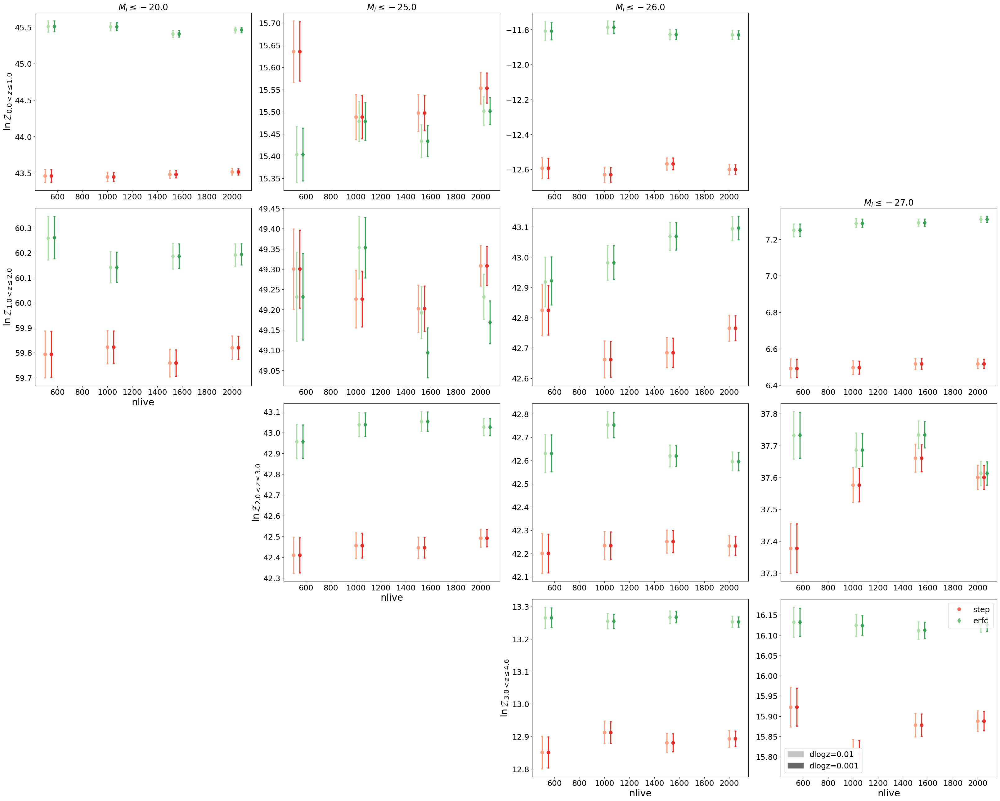

In [28]:
# for ndim in ndim_array:
    
#     fig = plt.figure(figsize = (40, 32))
#     gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
#     for i in range(len(L_bins)):
        
#         for j in range(len(z_array)):
    
#             if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
#                 ax1 = fig.add_subplot(gs[j*4+i])
                
#                 for nlive in [500, 1000, 1500, 2000]:
    
#                     for k, dlogz in enumerate(dlogz_array):
                        
#                         try:
                    
#                             file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
#                                 G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                            
#                             # read the results
#                             with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
#                                 results = pickle.load(fp)
                        
#                             logz = results.logz[-1]
#                             logzerr = results.logzerr[-1]
                        
#                             ax1.errorbar(nlive+k*50, logz, yerr = logzerr, linewidth = 2.5, marker = 'o', markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
#                                          label = 'dlogz={}'.format(dlogz), color = colors[k]) #orange')
                            
#                         except Exception as e:
#                             print(e)
    
#                 h, l = ax1.get_legend_handles_labels()
#                 labels, ind = np.unique(l, return_index = True)
                
#                 if (j ==0) or ((j == 1) and (i == 3)):
#                     ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
    
#                 if i==0 or ((j>1) and (i <3) and (i!=j)):
#                     ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
#                 if j > 2 or ((j>0) and (i <2) and (i!=j)):
#                     ax1.set_xlabel('nlive')
        
#                 ax1.legend([h[i] for i in ind], labels)#np.unique(l))
                
#     plt.show()

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
    
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            for l, ndim in enumerate(ndim_array):
                
                for nlive in [500, 1000, 1500, 2000]:
    
                    for k, dlogz in enumerate(dlogz_array):
                        
                        try:
                    
                            file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                                G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                            
                            # read the results
                            with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                                results = pickle.load(fp)

                            logz = results.logz[-1]
                            logzerr = results.logzerr[-1]
                        
                            ax1.errorbar(nlive+k*50+(ndim-2)*25, logz, yerr = logzerr, linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                         label = 'dlogz={}'.format(dlogz), color = cmaps[l][k]) #orange')
                            
                        except Exception as e:
                            print(e)
                
                if (j ==0) or ((j == 1) and (i == 3)):
                    ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))
    
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('nlive')
        
custom_lines = [Line2D([0], [0], color = np.mean(cmaps[l], axis = 0), linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
fig.add_artist(second_legend)

custom_lines = [mpatches.Patch(color=sns.color_palette("Greys", n_colors = len(ndim_array))[i]) for i in range(len(dlogz_array))]
second_legend = ax1.legend(custom_lines, ['dlogz={}'.format(dlogz) for dlogz in dlogz_array], loc = 'lower left')
fig.add_artist(second_legend)
                
plt.show()

In [28]:
quantile = [0.16, 0.5, 0.84]
ylabels = ['\log_{10}(M_{min}/M_\odot)', r'\alpha', '\Sigma']
units = ['', '', ' [dex]']

<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:2: SyntaxWarning: invalid escape sequence '\S'
<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:2: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_108786/458993769.py:2: SyntaxWarning: invalid escape sequence '\l'
  ylabels = ['\log_{10}(M_{min}/M_\odot)', r'\alpha', '\Sigma']
/tmp/ipykernel_108786/458993769.py:2: SyntaxWarning: invalid escape sequence '\S'
  ylabels = ['\log_{10}(M_{min}/M_\odot)', r'\alpha', '\Sigma']


<>:56: SyntaxWarning: invalid escape sequence '\l'
<>:56: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/724286668.py:56: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))


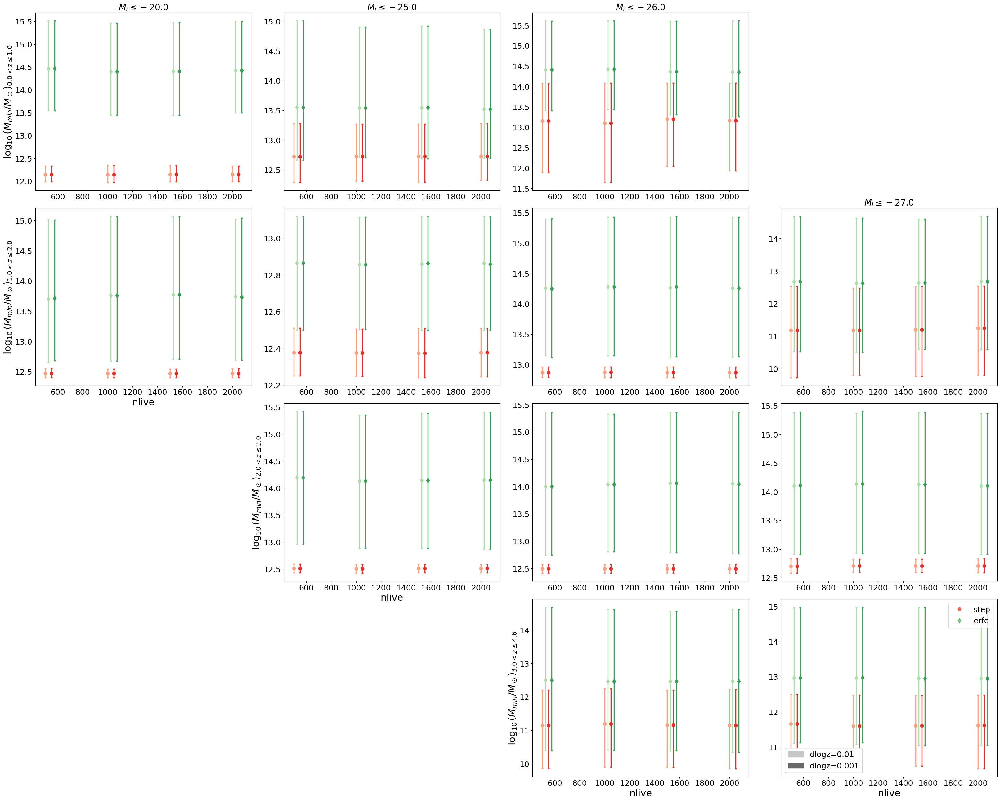

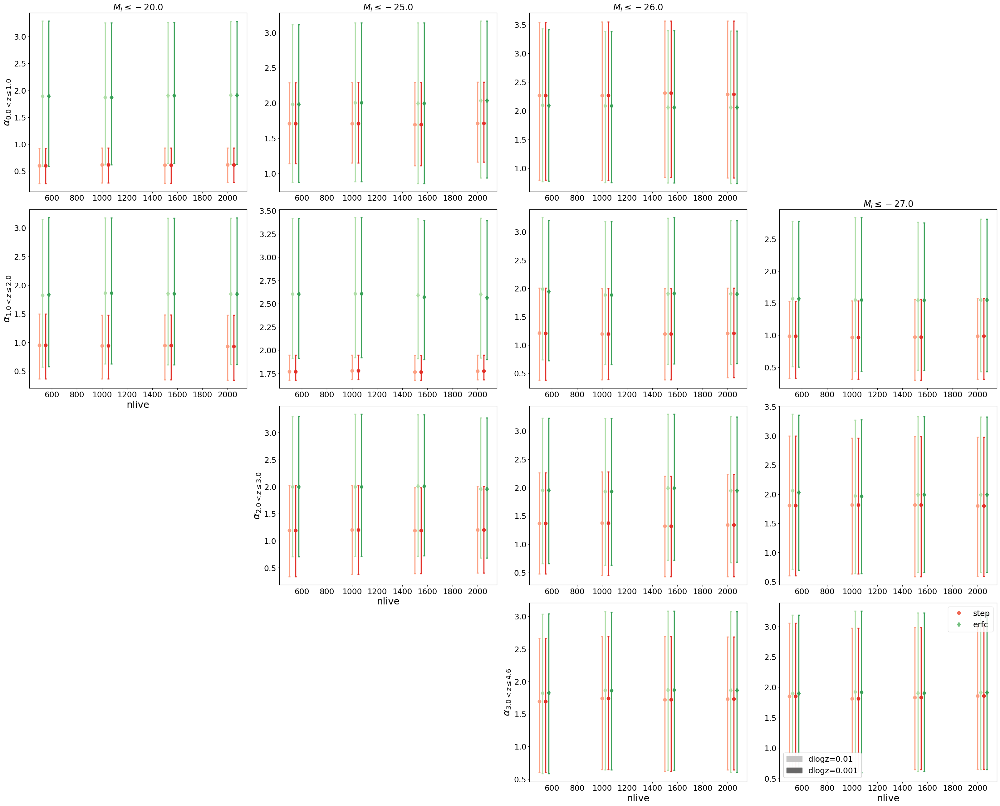

list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out o

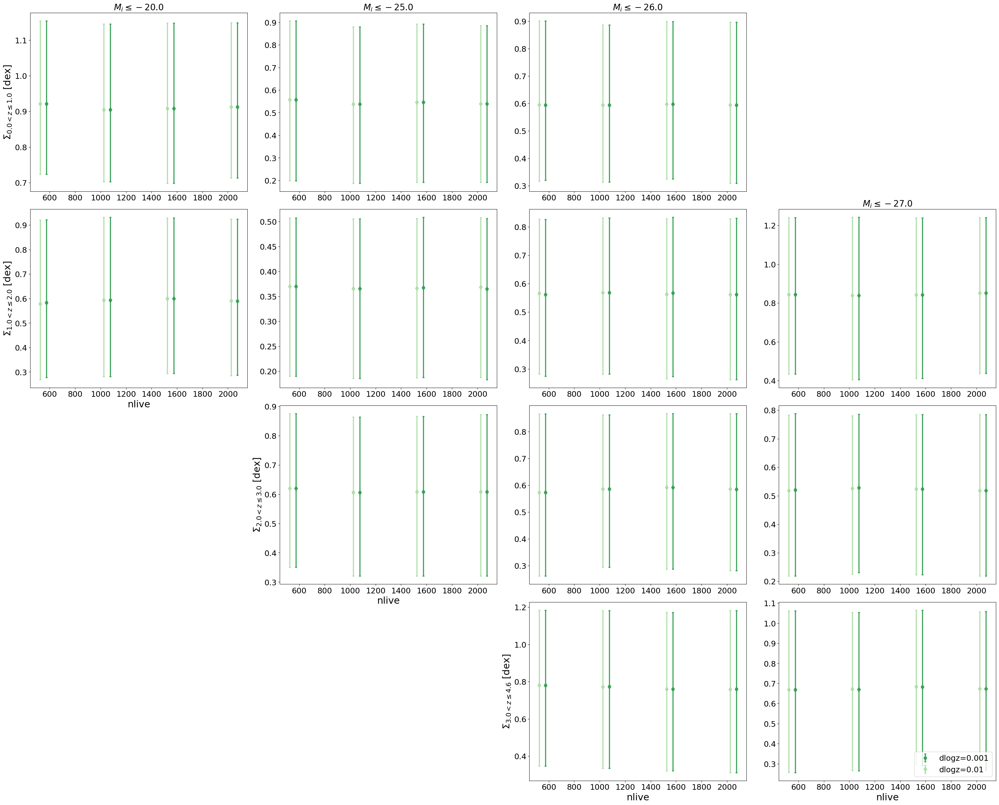

In [30]:
for m in range(ndim_array[-1]):
    
    fig = plt.figure(figsize = (40, 32))
    gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
        
    for i in range(len(L_bins)):
        
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i])
    
                for l, ndim in enumerate(ndim_array):
                    
                    for nlive in [500, 1000, 1500, 2000]:
        
                        for k, dlogz in enumerate(dlogz_array):
                            
                            try:
                        
                                file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                                
                                # read the results
                                with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                                    results = pickle.load(fp)
    
                                samples, weights = results.samples, results.importance_weights()
            
                                # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                                quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                                             for i in range(samples.shape[1])]
                            
                                lo, mid, hi = quantiles[m]

                                # Compute weighted mean and covariance.
                                mean, cov = dyfunc.mean_and_cov(samples, weights)
                                mid = mean[m]

                                # # Get the maximum likelihood sample from dynesty results
                                # idx_max = np.argmax(results.logl)
                                # mid = samples[idx_max][m]
                                # print(hi - mid)
                            
                                ax1.errorbar(nlive+k*50+(ndim-2)*25, mid, yerr = [[mid - lo], [hi - mid]], linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                             label = 'dlogz={}'.format(dlogz), color = cmaps[l][k]) #, elinestyle = elinestyle[k]) #orange')
                                
                            except Exception as e:
                                print(e)
        
                    if (j ==0) or ((j == 1) and (i == 3)):
                        ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))
        
                    if i==0 or ((j>1) and (i <3) and (i!=j)):
                        ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))
                    if j > 2 or ((j>0) and (i <2) and (i!=j)):
                        ax1.set_xlabel('nlive')
            
    if m == ndim_array[-1]-1:
        h, l = ax1.get_legend_handles_labels()
        labels, ind = np.unique(l, return_index = True)
        ax1.legend([h[i] for i in ind], labels, loc = 'lower right')

    else:
        
        custom_lines = [Line2D([0], [0], color = np.mean(cmaps[l], axis = 0), linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
        second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
        fig.add_artist(second_legend)
        
        custom_lines = [mpatches.Patch(color=sns.color_palette("Greys", n_colors = len(ndim_array))[i]) for i in range(len(dlogz_array))]
        second_legend = ax1.legend(custom_lines, ['dlogz={}'.format(dlogz) for dlogz in dlogz_array], loc = 'lower left')
        fig.add_artist(second_legend)
                    
    plt.show()

In [29]:
M_max = 16.8 #15
n_bins = 201
bins_m = np.logspace(9, M_max, n_bins) #M_min_samples

In [30]:
labels_fduty = [r'$\log_{10} f_\mathrm{duty}$']

In [31]:
rng = np.random.default_rng(0)

In [34]:
f_duty = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
# f_duty_samples = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}

for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))
    
    for j in z_array:

        print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))            

        for l, ndim in enumerate(ndim_array):
        
            if (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                print('ndim: {}'.format(ndim))
    
                file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                
                # read the results
                with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                    results = pickle.load(fp)
        
                samples, weights = results.samples, results.importance_weights()
                equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                
                # print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))            
                # bins_m = np.logspace(equal_weight_samples[L_bins[i]][j][:,0], M_max, n_bins) #M_min_samples
    
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                              cosmo, b)))
          
                n_dm = []
                for k in range(len(equal_weight_samples[:,0])):
                    if ndim == 2:
                        n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim)
                    else:
                        n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim, sigma = equal_weight_samples[:,2][k])
                    n_s = sampler.N_s(bins_m, 1, 10**equal_weight_samples[:,0][k], 12*10**equal_weight_samples[:,0][k], 
                                     equal_weight_samples[:,1][k])
                    n_m = n_c+n_s
                
                    n_dm.append(M(bins_m, n_m, a = a, cosmo = cosmo_planck18, recenter = False)[1].value) #[:,0]
                
                equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_dm)
                print('n_q: {:.1e} (h/Mpc)^3'.format(n_q[L_bins[i]][j]))
                print('n_dm: {:.1e} (h/Mpc)^3'.format(np.median(n_dm)))
                
                # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile) 

                # Compute weighted mean and covariance.
                # mean, cov = dyfunc.mean_and_cov(equal_weight_samples_fduty, np.ones(np.shape(equal_weight_samples_fduty)))
                mid = np.mean(equal_weight_samples_fduty)
                
                print(f"{labels_fduty[0]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}\n")
                # err[err_labels[0]][L_bins[i]].append((lo, hi)) #0
    
                f_duty_median = mid
    
                # f_duty_sample = equal_weight_samples_fduty #[ind]
    
                # # # Get the maximum likelihood sample from dynesty results
                # bins_m = np.logspace(best_fit_params[L_bins[i]][j][0], M_max, n_bins)
                # n_dm = M(bins_m, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1]
                # best_fit_param = np.log10(n_q[L_bins[i]][j]/n_dm)
                
            else:
    
                # f_duty_sample = np.nan #[np.nan]*1000
                
                f_duty_median = np.nan
                print()
    
                # err[err_labels[0]][L_bins[i]].append((np.nan, np.nan)) #0
    
                # best_fit_param = [np.nan]*ndim
                
            # f_duty_samples[L_bins[i]].append(f_duty_sample)
            
            f_duty[ndim][L_bins[i]].append(f_duty_median)
    
            # # Get the maximum likelihood sample from dynesty results
            # best_fit_params[L_bins[i]][j]=np.append(best_fit_param, best_fit_params[L_bins[i]][j])

M_i<=-20.0
0.0<z<=1.0
ndim: 2


/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


n_q: 1.1e-05 (h/Mpc)^3
n_dm: 5.6e-03 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -2.76 + 0.19/-0.16

ndim: 3
n_q: 1.1e-05 (h/Mpc)^3
n_dm: 1.9e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.29 + 0.62/-0.57

1.0<z<=2.0
ndim: 2
n_q: 8.1e-06 (h/Mpc)^3
n_dm: 1.7e-03 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -2.32 + 0.08/-0.08

ndim: 3
n_q: 8.1e-06 (h/Mpc)^3
n_dm: 3.0e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.37 + 0.95/-0.78

2.0<z<=3.0
ndim: 2
n_q: 3.1e-06 (h/Mpc)^3
n_dm: 5.4e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -2.25 + 0.15/-0.15

ndim: 3
n_q: 3.1e-06 (h/Mpc)^3
n_dm: 1.7e-05 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -0.73 + 1.13/-1.14

3.0<z<=4.6
ndim: 2
n_q: 2.7e-07 (h/Mpc)^3
n_dm: 1.2e-02 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -4.85 + 1.58/-1.80

ndim: 3
n_q: 2.7e-07 (h/Mpc)^3
n_dm: 3.4e-03 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -4.09 + 2.21/-2.32

M_i<=-25.0
0.0<z<=1.0
ndim: 2
n_q: 2.1e-06 (h/Mpc)^3
n_dm: 5.2e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -2.68 + 0.70/-0.54

ndim: 3
n_q: 2.1e

### Solve for $\chi_c^2=\Delta^T x$ where $Cx=\Delta$

In [32]:
hartlap = (N-nbins_mask-2)/(N-1)

In [33]:
def f0_GLS_solve(x, a, C, wp, H0_c_dN_dz_norm, ndim, cosmo = cosmo_planck18, rpmask = theta_mask, hartlap = hartlap, #, fduty = 0, 
                 rpbins = thetabins, bins = bins_m): #, theta_mask = theta_mask):
    
    fduty, M_min, Alpha, sigma = [*x,0][:4]
    
    # bins_m = np.logspace(M_min, M_max, n_bins)
    
    # wp_2h_zbin = wtheta_2h_optimized(bins_m, H0_c_dN_dz_norm, theta_mask = rpmask, recenter_thetabins = recenter_thetabins, 
    #                                  params_HOD = [fduty, M_min, 0, np.log10(12*10**M_min), Alpha], one_halo = False)
    wp_2h_zbin = sampler.wtheta_2h_dynesty(bins, H0_c_dN_dz_norm.value, [fduty, M_min, sigma, np.log10(12*10**M_min), Alpha], ndim)#, 
                                           # thetabins = rpbins)
    
    if isinstance(rpmask, bool):
        rpmask = [rpmask]*len(quaia.recenter(rpbins))
    delta = (wp-wp_2h_zbin)[rpmask]
    ix_grid = np.ix_(rpmask, rpmask)
    
    return delta.T @ (hartlap*np.linalg.solve(C[ix_grid], delta))

### Add a number density constraint

In [34]:
def constraint(x, a, n_q, cosmo = cosmo_planck18, error = 0.05, #recenter_thetabins = False, #True, 
               hmf = hmf, n_bins = n_bins, bins_m = bins_m):
    
    fduty, M_min, Alpha, sigma = [*x, 0][:4] # fduty,
    
    # bins_m = np.logspace(M_min, M_max, n_bins)
    _, n_c, n_s = sampler.HOD_2h(bins_m, M_min, fduty, sigma, a, np.log10(12*10**M_min), Alpha, ndim, cosmo = cosmo)
    
    n_q_theory = M(bins_m, n_c + n_s, a = a, cosmo = cosmo, recenter = False, hmf= hmf)[1].value

    return error-np.abs(n_q_theory-n_q)/n_q

In [35]:
err_labels = ['log10(f_duty)', 'log10(M_min)', 'alpha', 'Sigma']

In [36]:
diag = False

In [37]:
ix_grid = np.ix_(theta_mask, theta_mask)

In [41]:
dlogz = 0.001
nlive = 1500
chi2_L_z_test = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))

    chi2_z=[]
    
    for j in z_array:

        print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))

        for l, ndim in enumerate(ndim_array):
            
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

                print('ndim: {}'.format(ndim))
                    
                file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                
                # read the results
                with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                    results = pickle.load(fp)
        
                samples, weights = results.samples, results.importance_weights()
                
                # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                             for i in range(samples.shape[1])]
            
                # lo, mid, hi = quantiles[m]

                # x = f_duty[ndim][L_bins[i]][j], *[quantiles[i][1] for i in range(ndim)]#[M_min[L_bins[i]][j]]
                x = f_duty[ndim][L_bins[i]][j], *np.array(quantiles)[:,1]
                
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
                if diag == True:
                    C*=np.identity(len(C))

                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                              cosmo, b)))
                
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    
                chi2 = f0_GLS_solve(x, a, C, wp_zbin_i, H0_c_dN_dz_norm[L_bins[i]][j], ndim)
                df = nbins_mask-len(x)-1
            
                print('           chi^2: {:.2f}'.format(chi2))
                print('   reduced chi^2: {:.2f}'.format(chi2/df))
                print('         delta n: {:.2e}'.format(constraint(x, a, n_q[L_bins[i]][j]))) #, fduty = f_duty[L_bins[i]][j])))
                try:
                    print('condition number: {:.2f}'.format(np.linalg.cond(C[ix_grid])))
                except Exception as e:
                    print(e)
                print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi2, df)))
        
            else:
                chi2=np.nan
                print()
    
            # chi2_z.append(chi2)

    # print(chi2_L_z[ndim])
        
            # chi2_L_z[ndim][L_bins[i]].append(chi2_z)
            chi2_L_z_test[ndim][L_bins[i]].append(chi2)

M_i<=-20.0
0.0<z<=1.0
ndim: 2
           chi^2: 16.81
   reduced chi^2: 1.40
         delta n: -1.24e-01
condition number: 20292.18
             PTE: 0.16

ndim: 3
           chi^2: 15.45
   reduced chi^2: 1.40
         delta n: -9.72e-02
condition number: 20292.18
             PTE: 0.16

1.0<z<=2.0
ndim: 2
           chi^2: 11.48
   reduced chi^2: 0.96
         delta n: -7.77e-02
condition number: 12857.18
             PTE: 0.49

ndim: 3
           chi^2: 12.30
   reduced chi^2: 1.12
         delta n: -4.45e-01
condition number: 12857.18
             PTE: 0.34

2.0<z<=3.0


3.0<z<=4.6


M_i<=-25.0
0.0<z<=1.0
ndim: 2
           chi^2: 12.87
   reduced chi^2: 1.07
         delta n: -4.56e-01
condition number: 16787.29
             PTE: 0.38

ndim: 3
           chi^2: 15.27
   reduced chi^2: 1.39
         delta n: 3.38e-03
condition number: 16787.29
             PTE: 0.17

1.0<z<=2.0
ndim: 2
           chi^2: 18.21
   reduced chi^2: 1.52
         delta n: 4.78e-02
condition number: 15643

In [38]:
def f_duty(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, sample = sample, 
         rmin = rmin, rmax = rmax, N = N, b = b, bins_m = bins_m, Sigma = None, quantile = quantile, a = None, i_null = None, rstate = rng):

    if Sigma is not None:
        sigma = '_Sigma{:.1f}'.format(Sigma)
    else:
        sigma=''

    if i_null is None:
        i_null = i
    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i_null], cosmo, ndim, sigma, dlogz,
        nlive, sample) 
                
    # read the results
    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
        results = pickle.load(fp)

    samples, weights = results.samples, results.importance_weights()
    
    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
    quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                 for i in range(samples.shape[1])]

    # Compute weighted mean and covariance.
    mean, cov = dyfunc.mean_and_cov(samples, weights)

    quantiles = np.array(quantiles)
    quantiles[:,1] = mean

    equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rstate)

    if a is None:
        a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                      cosmo, b)))
        
    n_dm = []
    for k in range(len(equal_weight_samples[:,0])):
        if ndim == 2:
            n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim)
        else:
            n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim, sigma = equal_weight_samples[:,2][k])
        n_s = sampler.N_s(bins_m, 1, 10**equal_weight_samples[:,0][k], 12*10**equal_weight_samples[:,0][k], 
                         equal_weight_samples[:,1][k])
        n_m = n_c+n_s
    
        n_dm.append(M(bins_m, n_m, a = a, cosmo = cosmo_planck18, recenter = False)[1].value) #[:,0]
    
    equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_dm)
    
    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
    lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile)

    # Compute weighted mean and covariance.
    mid = np.mean(equal_weight_samples_fduty)
    
    return np.append(np.array([lo, mid, hi])[:,None].T, quantiles, axis = 0), np.append(equal_weight_samples_fduty[:,None], equal_weight_samples, axis = 1)

In [39]:
def chi2(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, sample = sample, 
         rmin = rmin, rmax = rmax, N = N, b = b, diag = diag, H0_c_dN_dz_norm = H0_c_dN_dz_norm, bins_m = bins_m, Sigma = None, 
         a = None, i_null = None, L_bins = L_bins, theta_mask = theta_mask):

    # file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
    #                 G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                
    # # read the results
    # with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
    #     results = pickle.load(fp)

    # samples, weights = results.samples, results.importance_weights()
    
    # # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
    # quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
    #              for i in range(samples.shape[1])]

    # # lo, mid, hi = quantiles[m]

    # equal_weight_samples = dyfunc.resample_equal(samples, weights)
    
    # # print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))            
    # # bins_m = np.logspace(equal_weight_samples[L_bins[i]][j][:,0], M_max, n_bins) #M_min_samples

    if a is None:
        a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))

    if i_null is None:
        i_null = i
    # n_dm = []
    # for k in range(len(equal_weight_samples[:,0])):
    #     if ndim == 2:
    #         n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim)
    #     else:
    #         n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim, sigma = equal_weight_samples[:,2][k])
    #     n_s = sampler.N_s(bins_m, 1, 10**equal_weight_samples[:,0][k], 12*10**equal_weight_samples[:,0][k], 
    #                      equal_weight_samples[:,1][k])
    #     n_m = n_c+n_s
    
    #     n_dm.append(M(bins_m, n_m, a = a, cosmo = cosmo_planck18, recenter = False)[1].value) #[:,0]
    
    # equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_dm)
    # # print('n_q: {:.1e} (h/Mpc)^3'.format(n_q[L_bins[i]][j]))
    # # print('n_dm: {:.1e} (h/Mpc)^3'.format(np.median(n_dm)))
    
    # # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
    # lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile) 
    # lo, mid, hi = f_duty(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, 
    #                      sample = sample, rmin = rmin, rmax = rmax, N = N, b = b, bins_m = bins_m, Sigma = Sigma)[0]
    quantiles = f_duty(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, 
                       sample = sample, rmin = rmin, rmax = rmax, N = N, b = b, bins_m = bins_m, Sigma = Sigma, a = a, i_null = i_null)[0]
    print(quantiles)
    # print(f"{labels_fduty[0]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}\n")
    # err[err_labels[0]][L_bins[i]].append((lo, hi)) #0

    # f_duty_median = mid

    # x = mid, *[quantiles[i][1] for i in range(ndim)]#[M_min[L_bins[i]][j]]
    x = quantiles[:,1]
    
    C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
    if diag == True:
        C*=np.identity(len(C))
    
    wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))

    # print(x)
    # print(a)
    # print(C[0])
    # print(wp_zbin_i)
    # print(H0_c_dN_dz_norm[L_bins[i]][j])
    # print(ndim)
    
    hartlap = (N-nbins_mask-2)/(N-1)
    chi2 = f0_GLS_solve(x, a, C, wp_zbin_i, H0_c_dN_dz_norm[L_bins[i]][j], ndim, rpmask = theta_mask, hartlap = (N-nbins_mask-2)/(N-1))

    return chi2, x

<>:42: SyntaxWarning: invalid escape sequence '\c'
<>:42: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_6061/1802132633.py:42: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_ylabel('$\chi^2_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))


[[-2.91771982 -2.76400559 -2.57383113]
 [11.99145976 12.14800347 12.33807218]
 [ 0.26893295  0.60027915  0.91623308]]
[[-2.91790629 -2.76467015 -2.57383113]
 [11.99145983 12.14800233 12.33807056]
 [ 0.26893575  0.60029675  0.91623253]]
[[-2.93651521 -2.7687901  -2.57531616]
 [11.97683936 12.14163175 12.33848762]
 [ 0.27888966  0.61351048  0.92958064]]
[[-2.93360894 -2.76963075 -2.57531366]
 [11.97683938 12.1416362  12.33848755]
 [ 0.27889022  0.61351897  0.92958012]]
[[-2.91638202 -2.76193704 -2.57426668]
 [11.988367   12.14968772 12.33902767]
 [ 0.27558303  0.61201887  0.92983101]]
[[-2.91638202 -2.76159904 -2.57465974]
 [11.98836739 12.14968957 12.33902723]
 [ 0.27558332  0.61202454  0.92982995]]
[[-2.91657546 -2.76087825 -2.5723272 ]
 [11.98566806 12.149562   12.33684331]
 [ 0.29215901  0.61710215  0.92726591]]
[[-2.9182136  -2.76144197 -2.57288529]
 [11.98566812 12.14956322 12.33684319]
 [ 0.29215941  0.61709725  0.92726588]]
[[-1.84509085 -1.27329241 -0.66827057]
 [13.54168228 14.

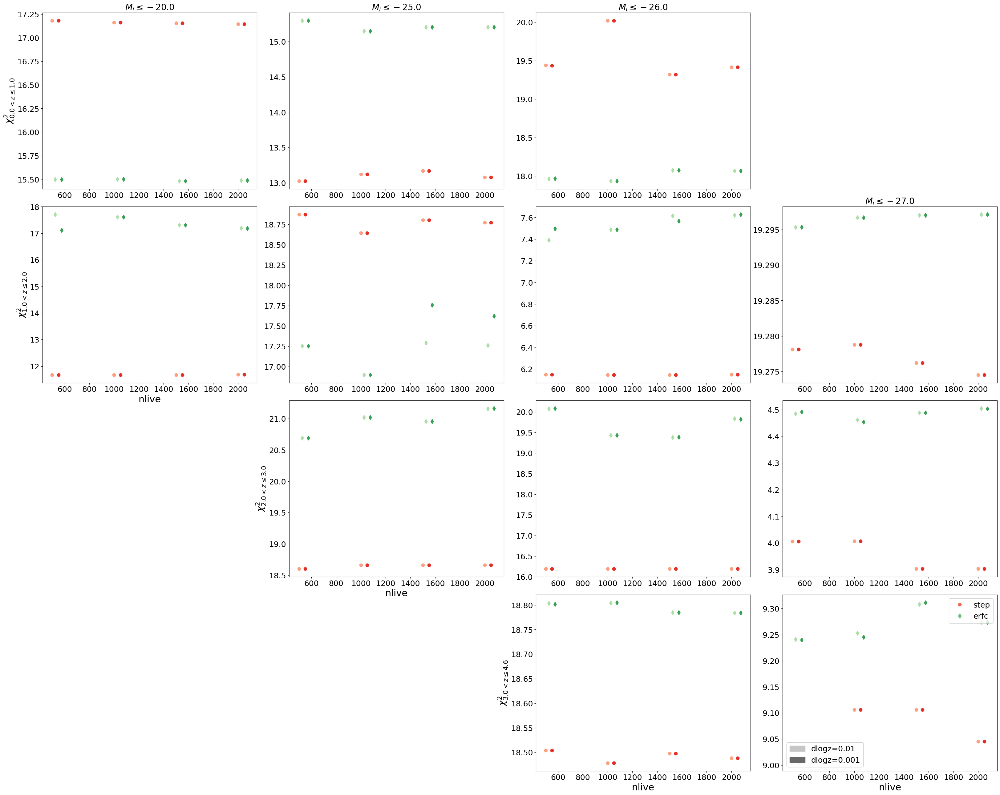

In [45]:
# np.mean(wp_2h_samples)
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
    
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            for l, ndim in enumerate(ndim_array):
                
                for nlive in [500, 1000, 1500, 2000]:
    
                    for k, dlogz in enumerate(dlogz_array):
                        
                        # try:
                    
                        #     file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                        #         G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                            
                        #     # read the results
                        #     with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        #         results = pickle.load(fp)

                            # logz = results.logz[-1]
                            # logzerr = results.logzerr[-1]
                        
                        # ax1.scatter(nlive+k*50+(ndim-2)*25, chi2_L_z[ndim][L_bins[i]][j], linewidth = 2.5, 
                        ax1.scatter(nlive+k*50+(ndim-2)*25, chi2(j, i, ndim, dlogz, nlive)[0], linewidth = 2.5, 
                                     marker = marker[l], linestyle = 'None', 
                                     label = 'dlogz={}'.format(dlogz), color = cmaps[l][k]) #orange')
                            
                        # except Exception as e:
                        #     print(e)
                
                if (j ==0) or ((j == 1) and (i == 3)):
                    ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))
    
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('$\chi^2_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('nlive')
        
custom_lines = [Line2D([0], [0], color = np.mean(cmaps[l], axis = 0), linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
fig.add_artist(second_legend)

custom_lines = [mpatches.Patch(color=sns.color_palette("Greys", n_colors = len(ndim_array))[i]) for i in range(len(dlogz_array))]
second_legend = ax1.legend(custom_lines, ['dlogz={}'.format(dlogz) for dlogz in dlogz_array], loc = 'lower left')
fig.add_artist(second_legend)
                 
plt.show()

## Walker

In [40]:
dlogz = 0.01
sample_array = ['auto', 'unif', 'rwalk', 'slice', 'rslice']
nlive = 500

In [41]:
# cmaps = [sns.color_palette("Reds", n_colors = 1), sns.color_palette("Greens", n_colors = 1)]
colors = 'red', 'orange'

<>:87: SyntaxWarning: invalid escape sequence '\l'
<>:87: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/3989086270.py:87: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))


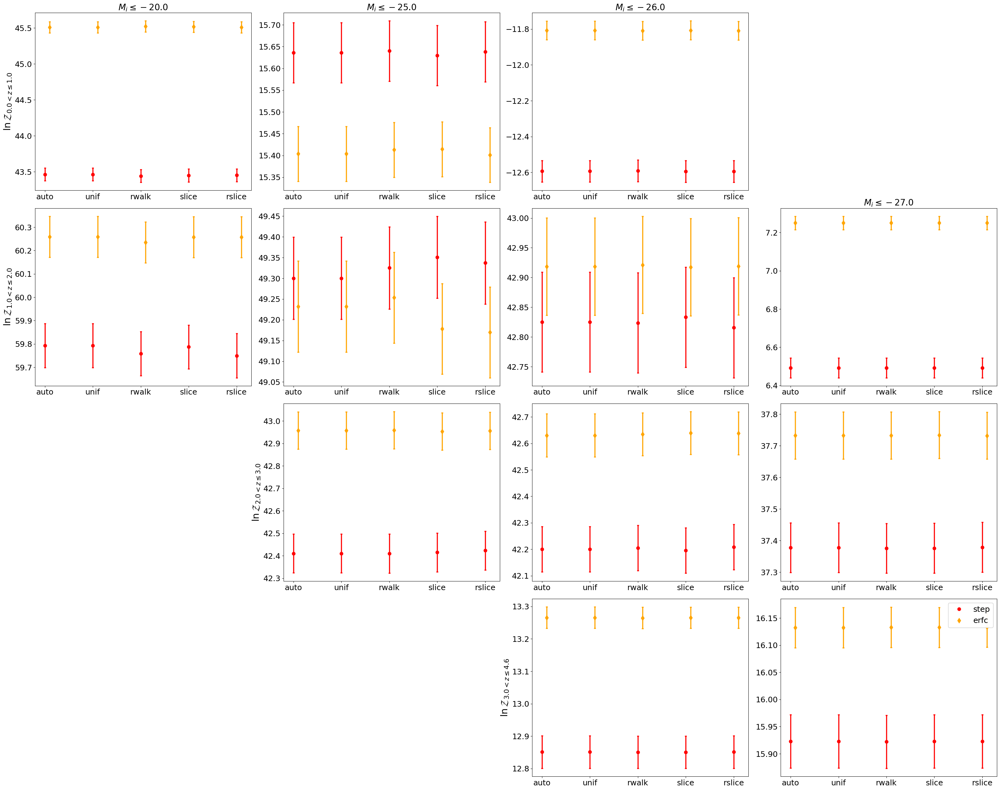

In [48]:
# for ndim in ndim_array:
    
#     colors = 'red', 'orange'
#     fig = plt.figure(figsize = (40, 32))
#     gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
#     for i in range(len(L_bins)):
        
#         for j in range(len(z_array)):
    
#             if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
#                 ax1 = fig.add_subplot(gs[j*4+i])
                    
#                 for k, sample in enumerate(sample_array):
                    
#                     # try:
                
#                     file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
#                         G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                    
#                     # read the results
#                     with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
#                         results = pickle.load(fp)
                
#                     logz = results.logz[-1]
#                     logzerr = results.logzerr[-1]
                
#                     ax1.errorbar(k, logz, yerr = logzerr, linewidth = 2.5, marker = 'o', markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
#                                  label = '{}'.format(sample)) #orange')
                    
#                     # except Exception as e:
#                     #     print(e)
    
#                 h, l = ax1.get_legend_handles_labels()
    
#                 if (j ==0) or ((j == 1) and (i == 3)):
#                     ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
    
#                 if i==0 or ((j>1) and (i <3) and (i!=j)):
#                     ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
#                 ax1.set_xticks([])
#                 # if j > 2 or ((j>0) and (i <2) and (i!=j)):
#                 #     ax1.set_xlabel('nlive')
        
#     ax1.legend() #np.unique(l))
                
#     plt.show()

    
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
    
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i]) 
            
            for l, ndim in enumerate(ndim_array):
                
                for k, sample in enumerate(sample_array):

                    try:
                        
                        file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                            G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                        
                        # read the results
                        with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                            results = pickle.load(fp)
                    
                        logz = results.logz[-1]
                        logzerr = results.logzerr[-1]
                    
                        ax1.errorbar(k+0.1*l, logz, yerr = logzerr, linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                     label = '{}'.format(sample), color = colors[l]) #cmaps[l][0]) #orange')

                    except Exception as e:
                        print(e)

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))

            if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xticks(range(len(sample_array)), sample_array)
    
custom_lines = [Line2D([0], [0], color = colors[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
fig.add_artist(second_legend)
                
plt.show()

<>:50: SyntaxWarning: invalid escape sequence '\l'
<>:50: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/3601429703.py:50: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))


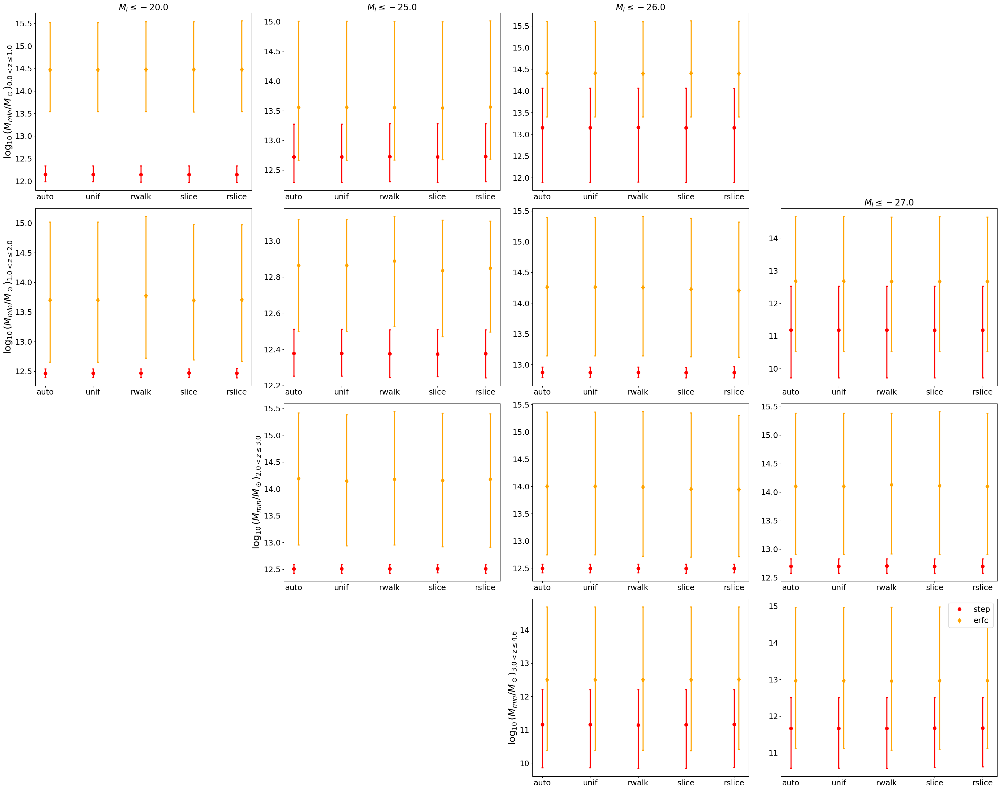

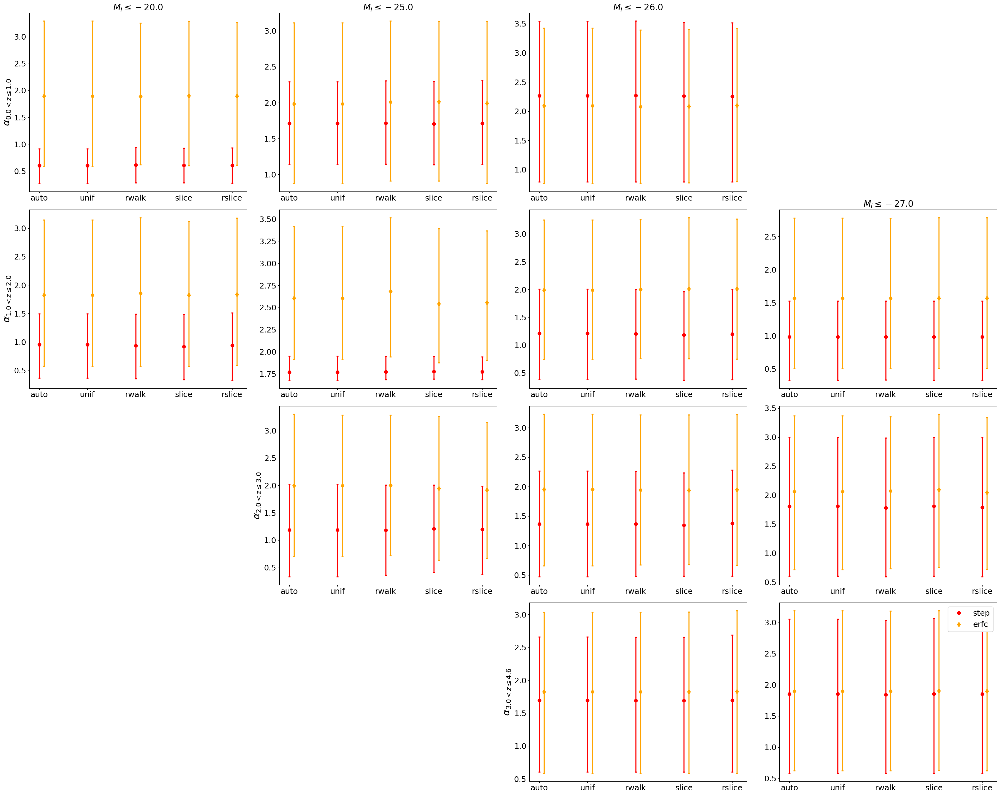

list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out o

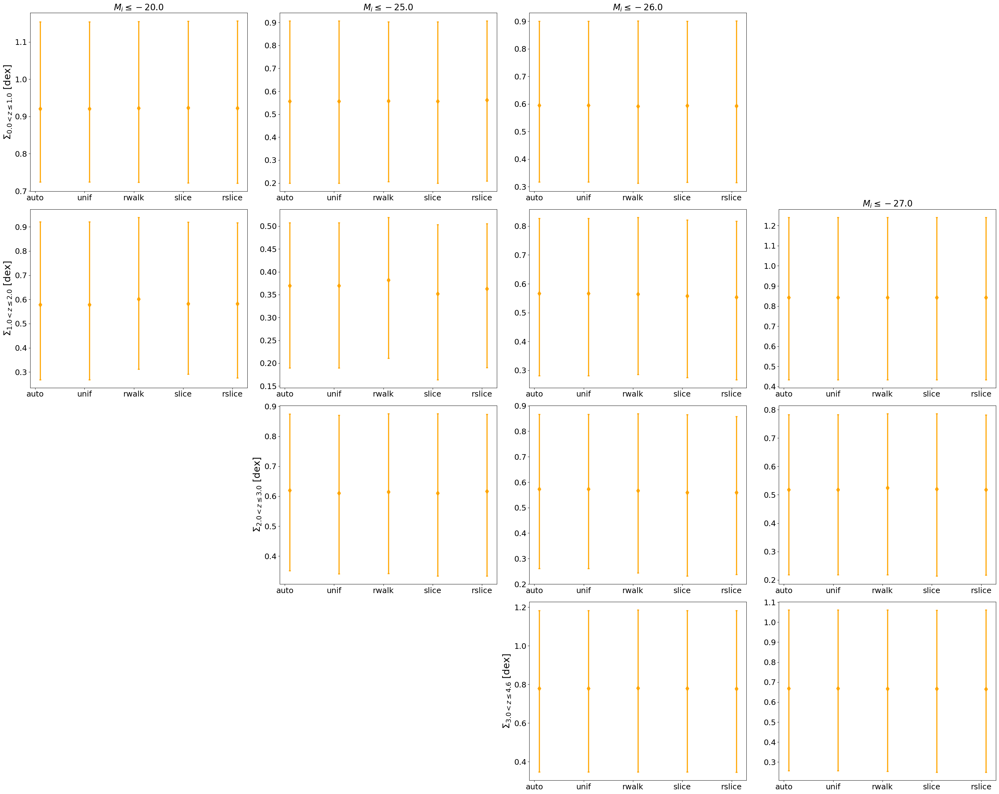

In [49]:
for m in range(ndim_array[-1]):
    
    fig = plt.figure(figsize = (40, 32))
    gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
        
    for i in range(len(L_bins)):
        
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i]) 
                
                for l, ndim in enumerate(ndim_array):
                    
                    for k, sample in enumerate(sample_array):

                        try:
                                        
                            file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                                G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                            
                            # read the results
                            with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                                results = pickle.load(fp)
                        
                            samples, weights = results.samples, results.importance_weights()
                            
                            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                            quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                                         for i in range(samples.shape[1])]
                        
                            lo, mid, hi = quantiles[m]

                            # Compute weighted mean and covariance.
                            mean, cov = dyfunc.mean_and_cov(samples, weights)
                            mid = mean[m]
                        
                            ax1.errorbar(k+0.1*l, mid, yerr = [[mid - lo], [hi - mid]], linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                         label = '{}'.format(sample), color = colors[l]) #cmaps[l][0]) #orange')

                        except Exception as e:
                            print(e)


                if (j ==0) or ((j == 1) and (i == 3)):
                    ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))
    
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))
                ax1.set_xticks(range(len(sample_array)), sample_array)
            
    if m == ndim_array[-1]-1:
        # h, l = ax1.get_legend_handles_labels()
        # labels, ind = np.unique(l, return_index = True)
        # ax1.legend([h[i] for i in ind], labels, loc = 'lower right')

        pass

    else:
        
        custom_lines = [Line2D([0], [0], color = colors[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
        second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
        fig.add_artist(second_legend)
        
        # custom_lines = [mpatches.Patch(color=sns.color_palette("Greys", n_colors = len(ndim_array))[i]) for i in range(len(dlogz_array))]
        # second_legend = ax1.legend(custom_lines, ['dlogz={}'.format(dlogz) for dlogz in dlogz_array], loc = 'lower left')
        # fig.add_artist(second_legend)
                    
    plt.show()

<>:42: SyntaxWarning: invalid escape sequence '\c'
<>:42: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_6061/329087334.py:42: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_ylabel('$\chi^2_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-2.91771982 -2.76471832 -2.57410502]
 [11.99145976 12.14800347 12.33807218]
 [ 0.26893295  0.60027915  0.91623308]]
[[-2.9184616  -2.76461229 -2.57367332]
 [11.99145976 12.14800347 12.33807218]
 [ 0.26893295  0.60027915  0.91623308]]
[[-2.93585675 -2.76275642 -2.57567355]
 [11.98084635 12.14829868 12.33734649]
 [ 0.28274024  0.61146131  0.93519387]]
[[-2.93900918 -2.76818089 -2.57714603]
 [11.9733172  12.14444256 12.33835005]
 [ 0.28118689  0.60537656  0.92710446]]
[[-2.93760705 -2.76199252 -2.57787125]
 [11.97837881 12.14813788 12.33773614]
 [ 0.27859271  0.60665561  0.93253463]]
[[-1.84885961 -1.27473255 -0.66919217]
 [13.54168228 14.46872672 15.51632902]
 [ 0.58736357  1.89324965  3.29183553]
 [ 0.72389365  0.92095703  1.15401512]]
[[-1.84858132 -1.27532867 -0.66919217]
 [13.54168228 14.46872672 15.51632902]
 [ 0.58736357  1.89324965  3.29183553]
 [ 0.72389365  0.92095703  1.15401512]]
[[-1.83197723 -1.27089373 -0.65764642]
 [13.54233084 14.47588944 15.53470582]
 [ 0.62097821  1.8

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-2.40278477 -2.31854149 -2.23337066]
 [12.39714783 12.46970041 12.5431705 ]
 [ 0.36499839  0.95074587  1.49713841]]
[[-2.40289162 -2.31877617 -2.23305507]
 [12.39714783 12.46970041 12.5431705 ]
 [ 0.36499839  0.95074587  1.49713841]]
[[-2.40614993 -2.3225479  -2.23795169]
 [12.39521718 12.46751234 12.54121547]
 [ 0.35664713  0.93683352  1.49064837]]
[[-2.40563838 -2.32068008 -2.22889096]
 [12.39840652 12.47025464 12.54206864]
 [ 0.33689719  0.92077259  1.48308249]]
[[-2.40619004 -2.32383757 -2.23081839]
 [12.39135378 12.46793346 12.54437701]
 [ 0.33017187  0.9392866   1.50982122]]
[[-2.17007098 -1.39376    -0.4431939 ]
 [12.65346463 13.70352149 15.0153943 ]
 [ 0.57204035  1.82233522  3.14646044]
 [ 0.26874117  0.5781275   0.92121327]]
[[-2.1663959  -1.38853921 -0.43668205]
 [12.65346463 13.70352149 15.0153943 ]
 [ 0.57204035  1.82233522  3.14646044]
 [ 0.26874117  0.5781275   0.92121327]]
[[-2.12302737 -1.33615675 -0.37955214]
 [12.72255817 13.77631989 15.11383041]
 [ 0.57413052  1.8

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-3.26279927 -2.68918455 -1.98438875]
 [12.29366909 12.72261837 13.27801475]
 [ 1.14097591  1.70830868  2.28952935]]
[[-3.26662643 -2.69170224 -1.98441135]
 [12.29366909 12.72261837 13.27801475]
 [ 1.14097591  1.70830868  2.28952935]]
[[-3.26230614 -2.69036056 -1.98399812]
 [12.30768113 12.72778528 13.28074706]
 [ 1.14374929  1.71413936  2.30523041]]
[[-3.26581777 -2.69350533 -1.98289389]
 [12.29405403 12.72206772 13.28344219]
 [ 1.13709385  1.70525347  2.29302462]]
[[-3.26015358 -2.68923872 -1.98386155]
 [12.30625775 12.72859095 13.28324122]
 [ 1.14181198  1.71355852  2.30614227]]
[[-3.20888084 -2.18416171 -0.93523767]
 [12.6666349  13.55552343 15.00894789]
 [ 0.87447805  1.98172835  3.11273035]
 [ 0.19903364  0.55704677  0.90663599]]
[[-3.19540465 -2.18497723 -0.93523767]
 [12.6666349  13.55552343 15.00894789]
 [ 0.87447805  1.98172835  3.11273035]
 [ 0.19903364  0.55704677  0.90663599]]
[[-3.2254924  -2.20675841 -0.94558187]
 [12.66931137 13.55169322 15.00060113]
 [ 0.91051639  2.0

... (14 outputs left out)

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-2.51047971 -2.27466848 -2.05059667]
 [12.57987007 12.70093522 12.83054075]
 [ 0.60148171  1.80640953  2.9966441 ]]
[[-2.50991315 -2.27356069 -2.05054631]
 [12.57987007 12.70093522 12.83054075]
 [ 0.60148171  1.80640953  2.9966441 ]]
[[-2.51226169 -2.27134704 -2.05056243]
 [12.57961224 12.70167462 12.8304688 ]
 [ 0.59178788  1.77991561  2.9871564 ]]
[[-2.51192215 -2.27574182 -2.05060825]
 [12.57962058 12.70036775 12.83046694]
 [ 0.60189026  1.80561392  2.99610381]]
[[-2.51339703 -2.27384955 -2.0506397 ]
 [12.58011937 12.70139857 12.83036938]
 [ 0.59240932  1.78736361  2.99047637]]
[[-2.04277227 -0.83823003  0.44202554]
 [12.90958745 14.09991539 15.38323831]
 [ 0.71290789  2.06021423  3.37043884]
 [ 0.21837109  0.51802712  0.78220038]]
[[-2.03932717 -0.83974741  0.44121463]
 [12.90958745 14.09991539 15.38323831]
 [ 0.71290789  2.06021423  3.37043884]
 [ 0.21837109  0.51802712  0.78220038]]
[[-2.0376052  -0.81763362  0.44202554]
 [12.91815181 14.12862288 15.38577992]
 [ 0.73283493  2.0

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-5.89414633 -4.20607661 -2.83495123]
 [10.58536389 11.66674269 12.50393131]
 [ 0.58196786  1.85146126  3.05441306]]
[[-5.86955181 -4.2036648  -2.83545819]
 [10.58536389 11.66674269 12.50393131]
 [ 0.58196786  1.85146126  3.05441306]]
[[-5.90732345 -4.21348656 -2.83488508]
 [10.57435614 11.66232433 12.50325643]
 [ 0.58165472  1.84370577  3.03422792]]
[[-5.85190314 -4.20246947 -2.83562253]
 [10.59754086 11.67065226 12.50353115]
 [ 0.5819265   1.85021566  3.06202077]]
[[-5.77741664 -4.18432044 -2.83475711]
 [10.61449221 11.675669   12.50340998]
 [ 0.5819609   1.85410672  3.06258969]]
[[-5.93324265 -3.29811273 -0.97602738]
 [11.11772945 12.96942983 14.96478617]
 [ 0.62073896  1.89826109  3.18519996]
 [ 0.25702524  0.66826712  1.06058643]]
[[-5.87857142 -3.28603942 -0.99416958]
 [11.11772945 12.96942983 14.96478617]
 [ 0.62073896  1.89826109  3.18519996]
 [ 0.25702524  0.66826712  1.06058643]]
[[-5.90817354 -3.29160818 -0.99302031]
 [11.07145266 12.96278115 14.97436006]
 [ 0.62299265  1.8

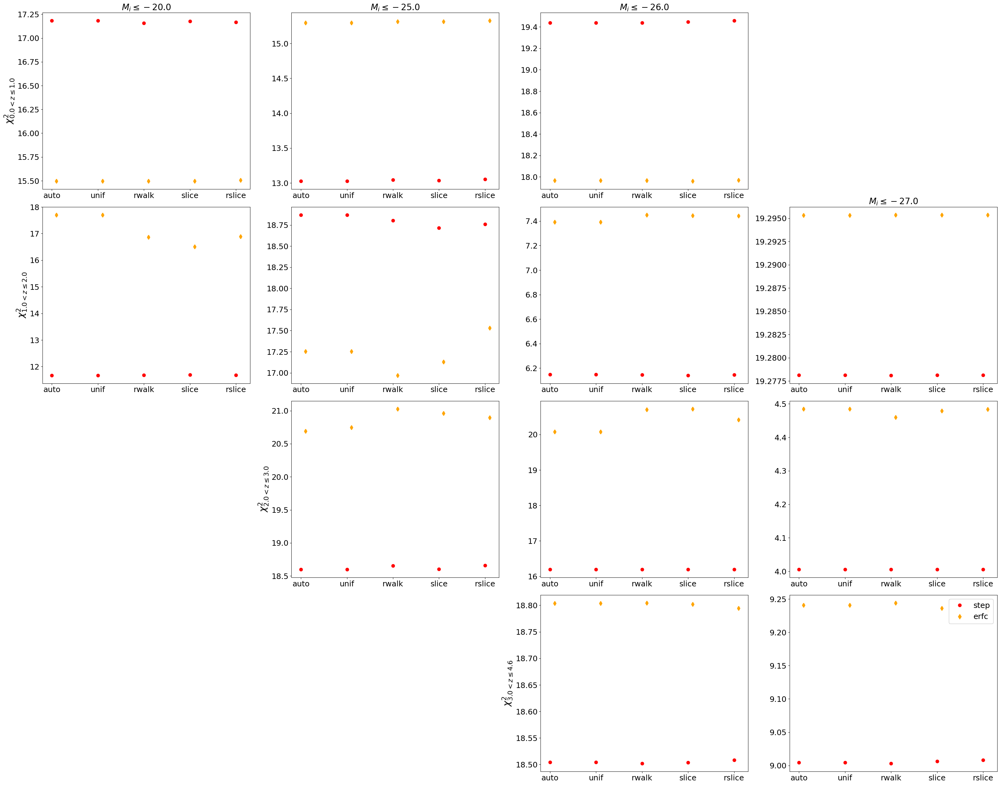

In [50]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.2, hspace = 0.1)
    
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i]) 
            
            for l, ndim in enumerate(ndim_array):
                
                for k, sample in enumerate(sample_array):

                    # try:
                        
                    #     file = '_G{}_logrmin{}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                    #         G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                        
                    #     # read the results
                    #     with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                    #         results = pickle.load(fp)
                    
                    #     logz = results.logz[-1]
                    #     logzerr = results.logzerr[-1]
                    
                    #     ax1.errorbar(k+0.1*l, logz, yerr = logzerr, linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                    #                  label = '{}'.format(sample), color = colors[l]) #cmaps[l][0]) #orange')

                    # except Exception as e:
                    #     print(e)

                    # ax1.scatter(k+0.1*l, chi2_L_z[ndim][L_bins[i]][j], linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, 
                    ax1.scatter(k+0.1*l, chi2(j, i, ndim, dlogz, nlive, sample = sample)[0], linewidth = 2.5, marker = marker[l],
                                label = '{}'.format(sample), color = colors[l])

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))

            if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('$\chi^2_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xticks(range(len(sample_array)), sample_array)
    
custom_lines = [Line2D([0], [0], color = colors[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
fig.add_artist(second_legend)
                
plt.show()

## Scale

In [42]:
sample = 'auto'
nlive = 500
dlogz = 0.01
log_thetamin_array = np.log10(np.logspace(-2.8, -1.2, 5))
# colors = 'red', 'orange'

<>:95: SyntaxWarning: invalid escape sequence '\l'
<>:95: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/2059119011.py:95: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))


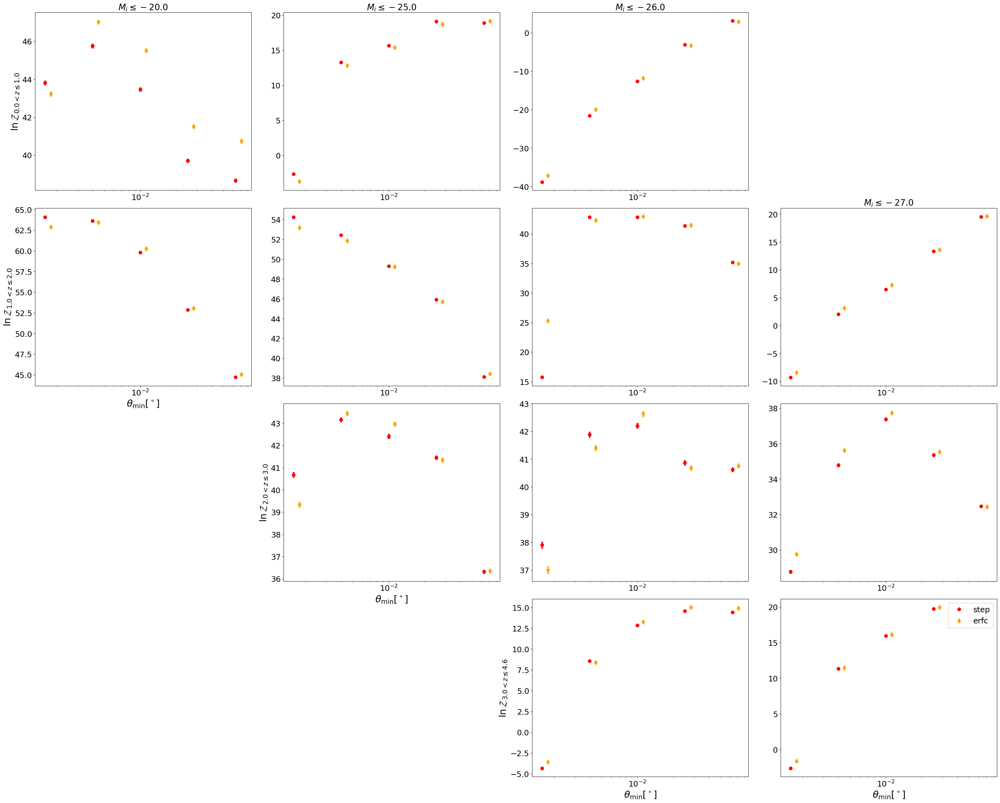

In [52]:
# fig = plt.figure(figsize = (40, 32))
# gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
    
# for i in range(len(L_bins)):
    
#     for j in range(len(z_array)):

#         if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
#             ax1 = fig.add_subplot(gs[j*4+i])
    
#             for k, ndim in enumerate(ndim_array):
                    
#                 for log_thetamin in log_thetamin_array:

#                     theta_mask=(quaia.recenter(np.log10(thetabins))>=float('{:.1f}'.format(log_thetamin))) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
#                     nbins_mask = np.sum(theta_mask)

#                     try:
                
#                         file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
#                             G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                        
#                         # read the results
#                         with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
#                             results = pickle.load(fp)
                    
#                         logz = results.logz[-1]
#                         logzerr = results.logzerr[-1]
                    
#                         ax1.errorbar(10**log_thetamin, logz, yerr = logzerr, linewidth = 2.5, marker = 'o', markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
#                                      label = 'ndim={}'.format(ndim), color = colors[k]) #orange')
                    
#                     except Exception as e:
#                         print(e)
    
#                 h, l = ax1.get_legend_handles_labels()
    
#                 if (j ==0) or ((j == 1) and (i == 3)):
#                     ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
    
#                 if i==0 or ((j>1) and (i <3) and (i!=j)):
#                     ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
#                 # ax1.set_xticks([])
#                 if j > 2 or ((j>0) and (i <2) and (i!=j)):
#                     ax1.set_xlabel(r'$\theta_\mathrm{min} [^\circ]$')
#                 ax1.set_xscale('log')
        
# ax1.legend(np.unique(l))
                
# plt.show()

    
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
    
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i]) 
            
            for l, ndim in enumerate(ndim_array):
                
                for k, log_thetamin in enumerate(log_thetamin_array):

                    theta_mask=(quaia.recenter(np.log10(thetabins))>=float('{:.1f}'.format(log_thetamin))) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
                    nbins_mask = np.sum(theta_mask)

                    try:
                    
                        file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                            G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                        
                        # read the results
                        with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                            results = pickle.load(fp)
                    
                        logz = results.logz[-1]
                        logzerr = results.logzerr[-1]
                    
                        ax1.errorbar(10**(log_thetamin+0.05*l), logz, yerr = logzerr, linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                     label = 'ndim={}'.format(ndim), color = colors[l]) #cmaps[l][k]) #orange')

                    except Exception as e:
                        print(e)


            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))

            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel('$\ln{{\mathcal{{Z}}}}_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta_\mathrm{min} [^\circ]$')
            ax1.set_xscale('log')          
                
    
custom_lines = [Line2D([0], [0], color = colors[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))] #np.mean(cmaps[l], axis = 0)
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
fig.add_artist(second_legend)
                    
plt.show()

In [43]:
# cmaps = [sns.color_palette("Reds", n_colors = len(log_thetamin_array)), sns.color_palette("Greens", n_colors = len(log_thetamin_array))]

In [43]:
cmap = sns.color_palette("crest_r", n_colors = len(L_bins))
cmap

[(0.12811691, 0.33411727, 0.51652464),
 (0.14051521, 0.46268258, 0.54653253),
 (0.26693801, 0.58118582, 0.56045121),
 (0.42702625, 0.69711868, 0.56614659)]

In [44]:
colors_thesis = [np.mean(cmap_theta, axis = 0), np.mean(cmap, axis = 0)]

<>:56: SyntaxWarning: invalid escape sequence '\l'
<>:56: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/2934147405.py:56: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))


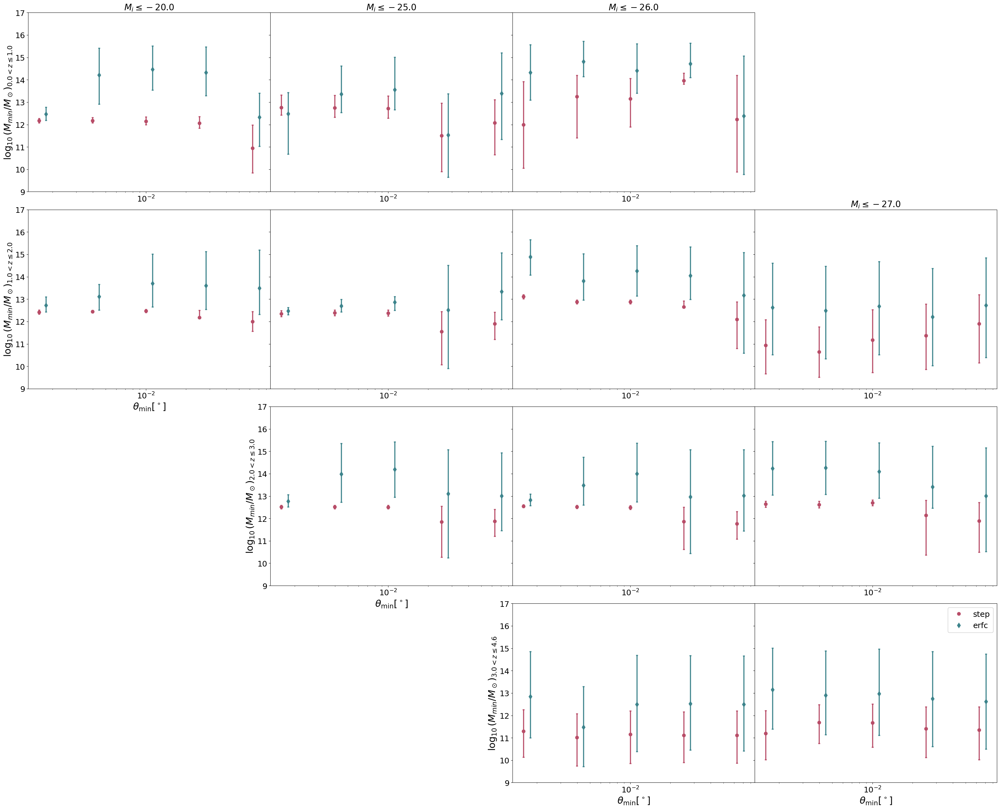

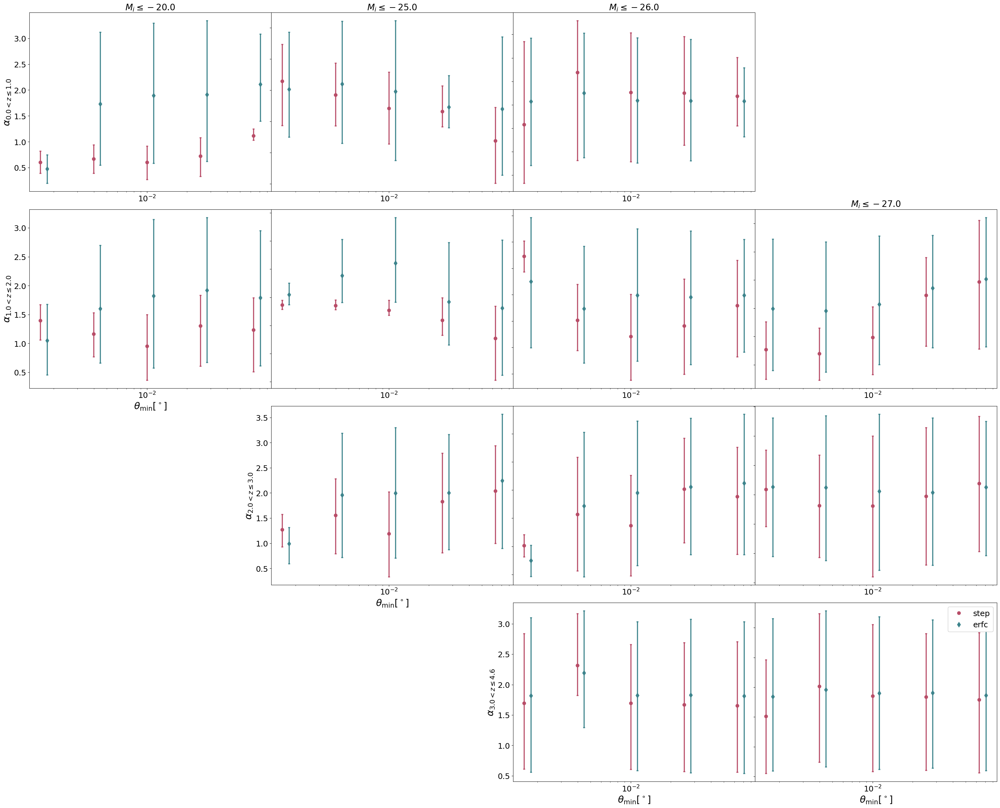

list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out o

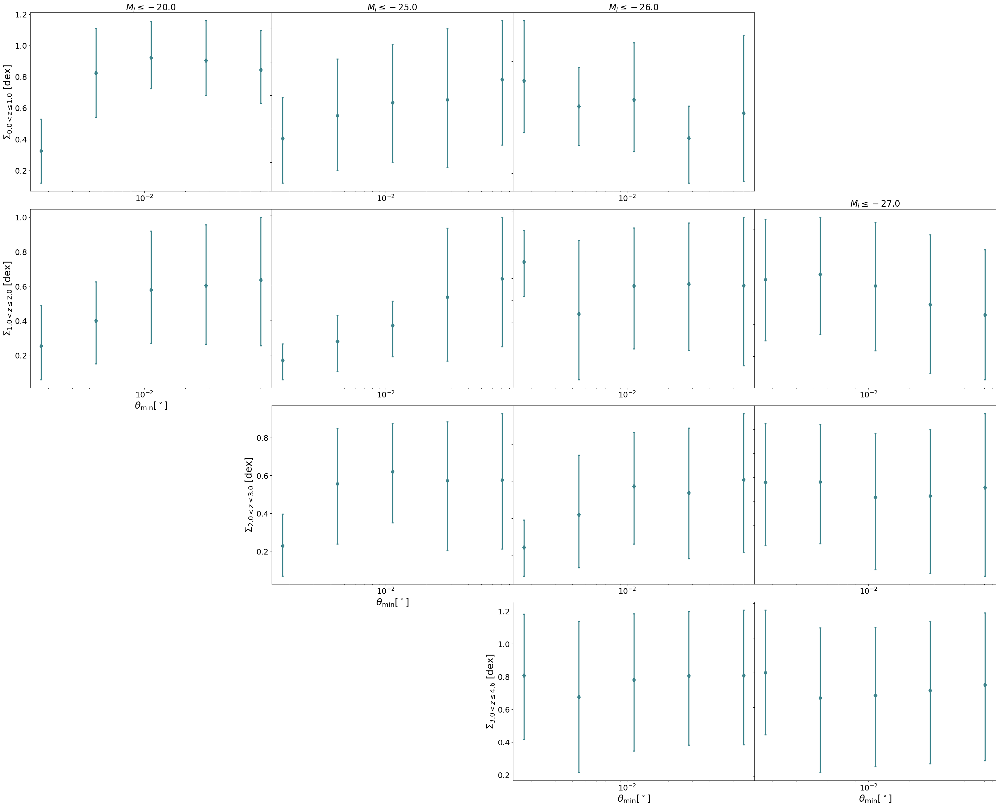

In [56]:
for m in range(ndim_array[-1]):
    
    fig = plt.figure(figsize = (40, 32))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
        
    for i in range(len(L_bins)):
        
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i]) 
                
                for l, ndim in enumerate(ndim_array):
                    
                    for k, log_thetamin in enumerate(log_thetamin_array):

                        theta_mask=(quaia.recenter(np.log10(thetabins))>=float('{:.1f}'.format(log_thetamin))) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
                        nbins_mask = np.sum(theta_mask)
                        # print(nbins_mask)
                        try:
                        
                            file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                            G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 

                            # read the results
                            with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                                results = pickle.load(fp)
                        
                            samples, weights = results.samples, results.importance_weights()
                            
                            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                            quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                                         for i in range(samples.shape[1])]
                        
                            lo, mid, hi = quantiles[m]

                            # Compute weighted mean and covariance.
                            mean, cov = dyfunc.mean_and_cov(samples, weights)
                            mid = mean[m]
                        
                            ax1.errorbar(10**(log_thetamin+0.05*l), mid, yerr = [[mid - lo], [hi - mid]], linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                     label = 'ndim={}'.format(ndim), color = colors_thesis[l]) # cmaps[l][k]) #orange')

                        except Exception as e:
                            print(e)


                if (j ==0) or ((j == 1) and (i == 3)):
                    ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))

                if m ==0:
                    ax1.set_ylim(9, 17)
                
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))
                else:
                    ax1.set_yticklabels([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel(r'$\theta_\mathrm{min} [^\circ]$')
                ax1.set_xscale('log')          
                    
    if m == ndim_array[-1]-1:

        pass

    else:
        
        custom_lines = [Line2D([0], [0], color = colors_thesis[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
        second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
        fig.add_artist(second_legend)

    plt.savefig('../figures/convergence_scale_{}.pdf'.format(err_labels[1:][m]), bbox_inches = 'tight')
    plt.show()

<>:57: SyntaxWarning: invalid escape sequence '\l'
<>:57: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_108786/2375636892.py:57: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]), fontsize = 40)


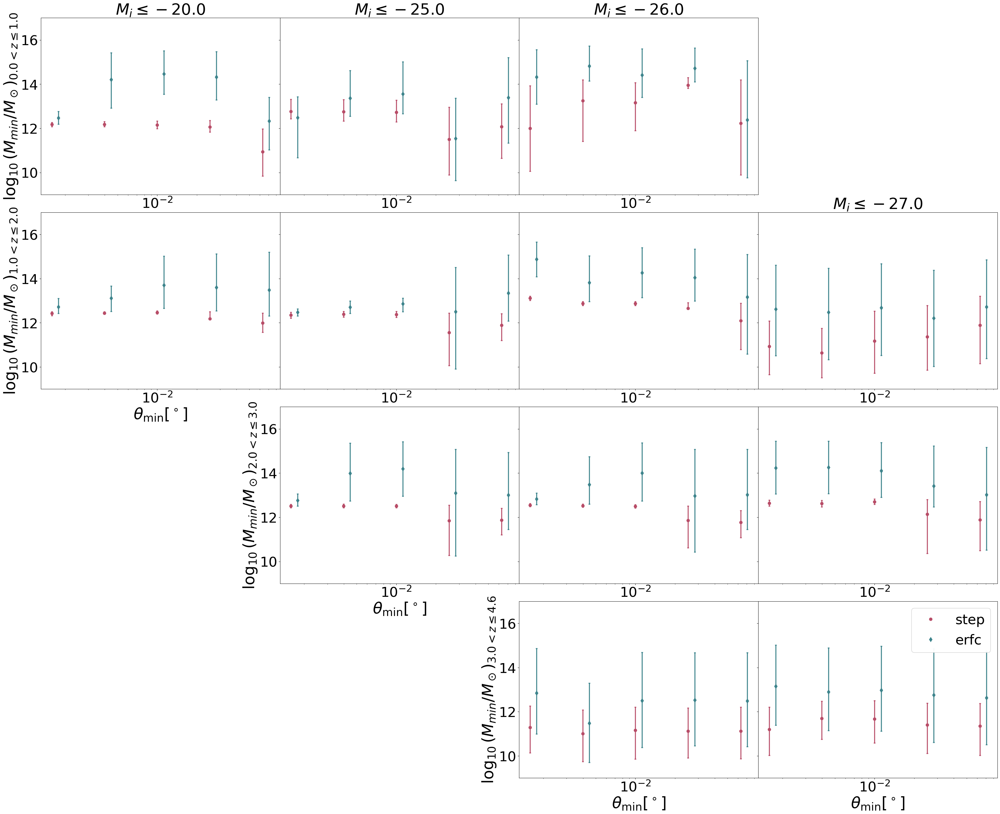

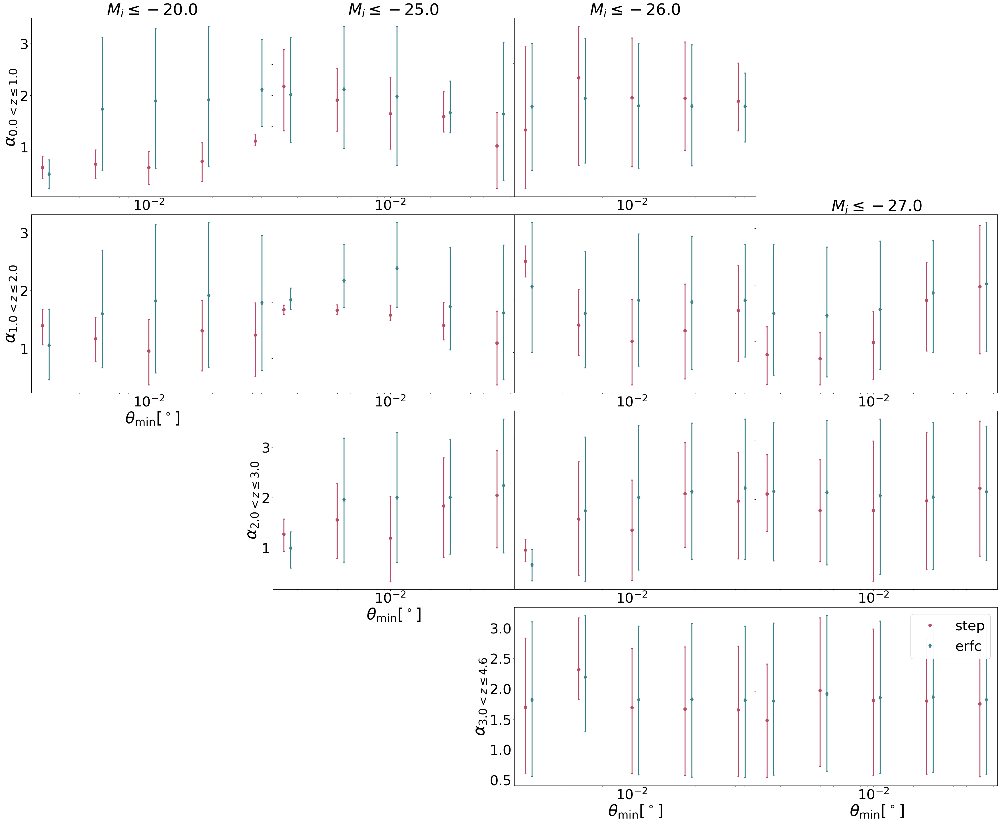

list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out o

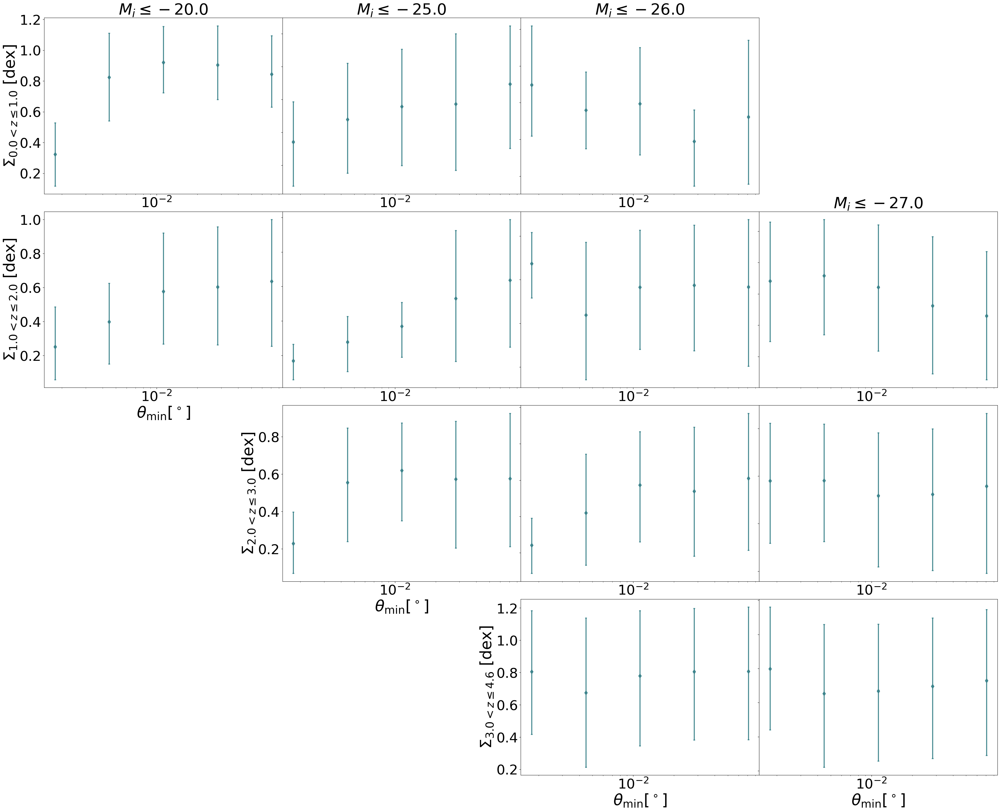

In [53]:
legends = ['step', 'erfc']
for m in range(ndim_array[-1]):
    
    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
        
    for i in range(len(L_bins)):
        
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i]) 
                
                for l, ndim in enumerate(ndim_array):
                    
                    for k, log_thetamin in enumerate(log_thetamin_array):

                        theta_mask=(quaia.recenter(np.log10(thetabins))>=float('{:.1f}'.format(log_thetamin))) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
                        nbins_mask = np.sum(theta_mask)

                        try:
                        
                            file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                            G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 

                            # read the results
                            with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                                results = pickle.load(fp)
                        
                            samples, weights = results.samples, results.importance_weights()
                            
                            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                            quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                                         for i in range(samples.shape[1])]
                        
                            lo, mid, hi = quantiles[m]

                            # Compute weighted mean and covariance.
                            mean, cov = dyfunc.mean_and_cov(samples, weights)
                            mid = mean[m]
                        
                            ax1.errorbar(10**(log_thetamin+0.05*l), mid, yerr = [[mid - lo], [hi - mid]], linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                     label = legends[l], color = colors_thesis[l]) # cmaps[l][k]) #orange')

                        except Exception as e:
                            print(e)


                if (j ==0) or ((j == 1) and (i == 3)):
                    ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]), fontsize = 40)

                if m ==0:
                    ax1.set_ylim(9, 17)
                
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]), fontsize = 40)
                else:
                    ax1.set_yticklabels([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel(r'$\theta_\mathrm{min} [^\circ]$', fontsize = 40)
                ax1.set_xscale('log')     
                ax1.tick_params(axis='both', labelsize=35)
                    
    if m == ndim_array[-1]-1:

        pass

    else:
        
        custom_lines = [Line2D([0], [0], color = colors_thesis[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
        second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right', fontsize = 35)
        fig.add_artist(second_legend)
        # ax1.legend(fontsize = 30)

    plt.savefig('../figures/convergence_scale_{}.pdf'.format(err_labels[1:][m]), bbox_inches = 'tight')
    plt.show()

<>:53: SyntaxWarning: invalid escape sequence '\l'
<>:53: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/923092834.py:53: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))


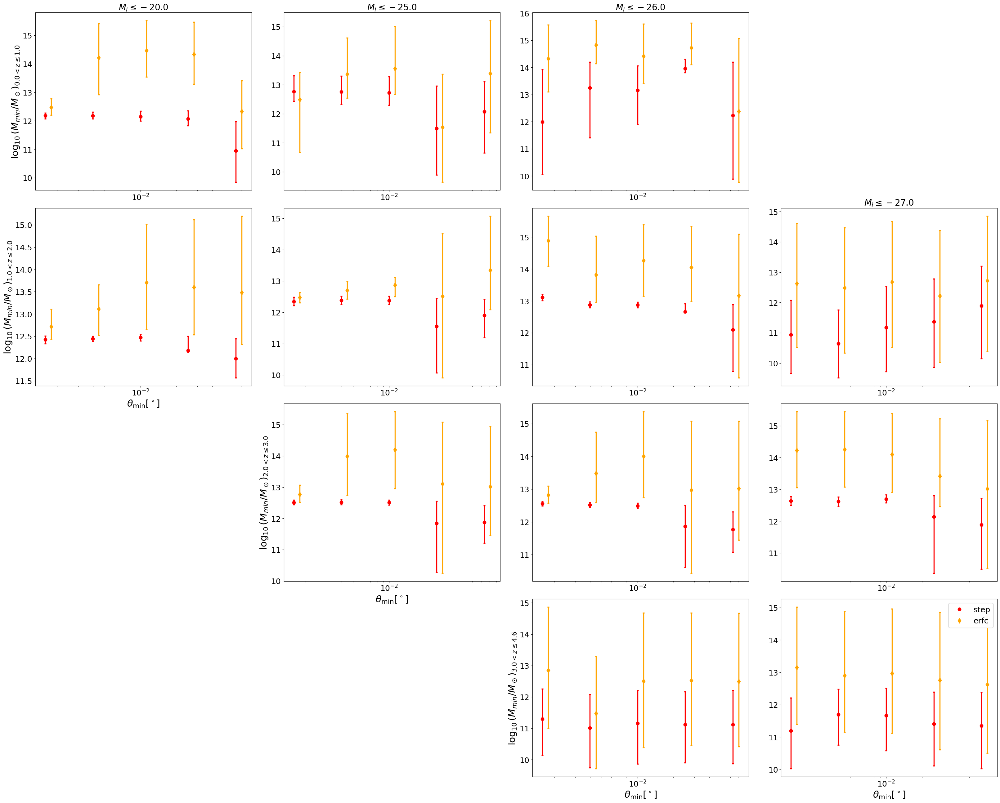

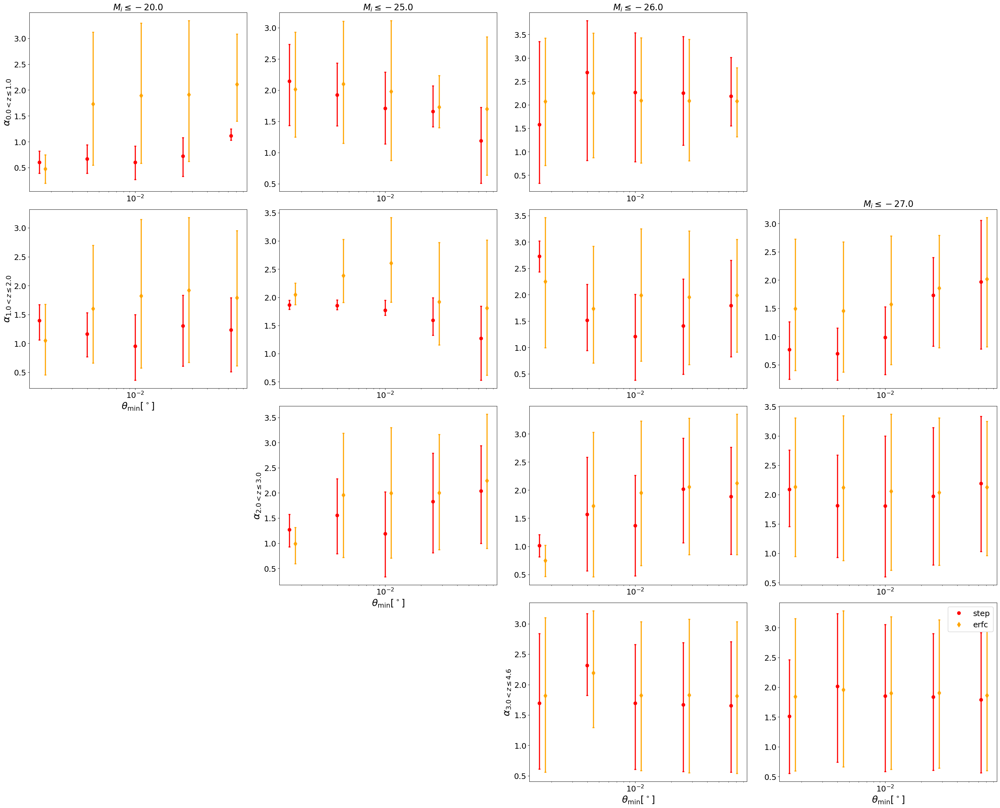

list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out of range
list index out o

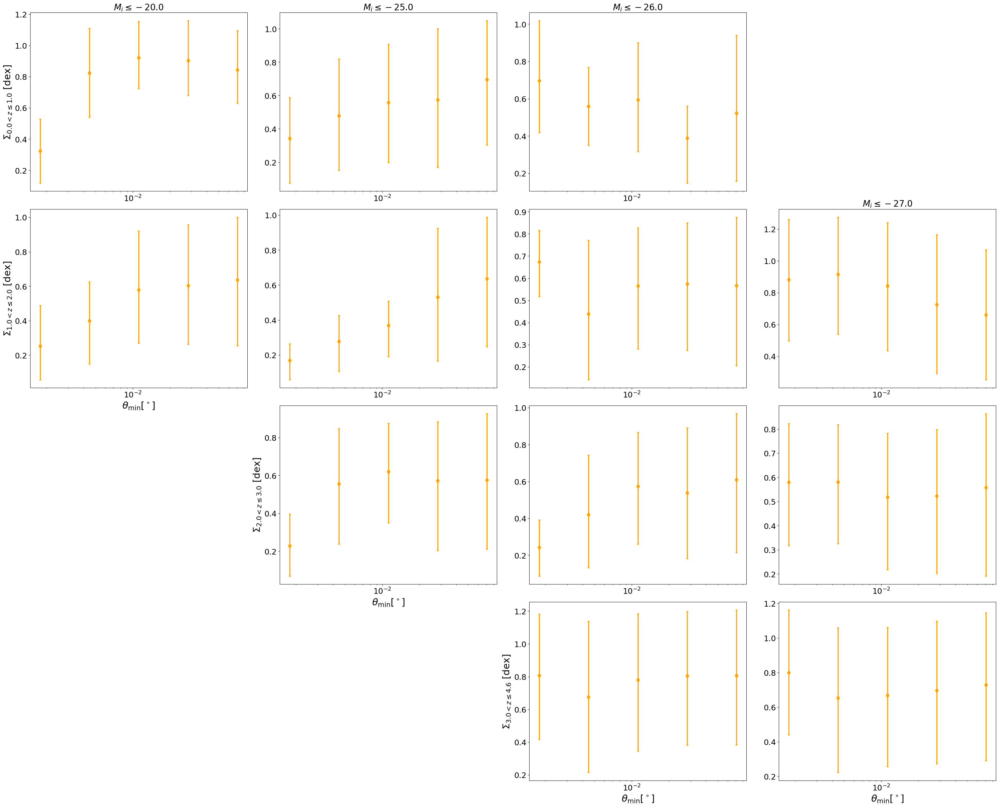

In [57]:
for m in range(ndim_array[-1]):
    
    fig = plt.figure(figsize = (40, 32))
    gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
        
    for i in range(len(L_bins)):
        
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i]) 
                
                for l, ndim in enumerate(ndim_array):
                    
                    for k, log_thetamin in enumerate(log_thetamin_array):

                        theta_mask=(quaia.recenter(np.log10(thetabins))>=float('{:.1f}'.format(log_thetamin))) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
                        nbins_mask = np.sum(theta_mask)
                        # print(nbins_mask)
                        try:
                        
                            file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                            G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                            # print(file)
                            # read the results
                            with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                                results = pickle.load(fp)
                        
                            samples, weights = results.samples, results.importance_weights()
                            
                            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                            quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                                         for i in range(samples.shape[1])]
                        
                            lo, mid, hi = quantiles[m]

                            # Compute weighted mean and covariance.
                            mean, cov = dyfunc.mean_and_cov(samples, weights)
                            mid = mean[m]
                        
                            ax1.errorbar(10**(log_thetamin+0.05*l), mid, yerr = [[mid - lo], [hi - mid]], linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                                     label = 'ndim={}'.format(ndim), color = colors[l]) # cmaps[l][k]) #orange')

                        except Exception as e:
                            print(e)


                if (j ==0) or ((j == 1) and (i == 3)):
                    ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))
    
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel('${}_{{{:.1f}<z \leq{:.1f}}}${}'.format(ylabels[m], z_bins[j], z_bins[j+1], units[m]))
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel(r'$\theta_\mathrm{min} [^\circ]$')
                ax1.set_xscale('log')          
                    
    if m == ndim_array[-1]-1:

        pass

    else:
        
        custom_lines = [Line2D([0], [0], color = colors[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))]
        second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
        fig.add_artist(second_legend)
                    
    plt.show()

<>:46: SyntaxWarning: invalid escape sequence '\c'
<>:46: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_6061/2449435239.py:46: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_ylabel('$\chi^2_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-2.84586774 -2.72960258 -2.61079024]
 [12.07421457 12.17399832 12.27440264]
 [ 0.3899721   0.60186185  0.82189531]]
[[-2.83721748 -2.71824255 -2.57679   ]
 [12.07308778 12.17950756 12.31164631]
 [ 0.38952852  0.66760661  0.94146658]]
[[-2.91957943 -2.76640575 -2.5742974 ]
 [11.99145976 12.14800347 12.33807218]
 [ 0.26893295  0.60027915  0.91623308]]
[[-3.06833659 -2.83919691 -2.54552128]
 [11.83371905 12.06508558 12.35751057]
 [ 0.32921022  0.72329877  1.07999588]]
[[-5.21091411 -4.0354808  -2.93135099]
 [ 9.84310613 10.94214566 11.97451791]
 [ 1.03104651  1.11282461  1.24891908]]
[[-2.75512226 -2.5623331  -2.36731359]
 [12.19447634 12.47140119 12.77237985]
 [ 0.19585549  0.4774309   0.7484938 ]
 [ 0.11777331  0.32424313  0.52870644]]
[[-2.21601482 -1.37204111 -0.64168124]
 [12.9210938  14.21005729 15.41592802]
 [ 0.55103205  1.73231611  3.11583562]
 [ 0.53990758  0.82376179  1.10994425]]
[[-1.84885961 -1.27260135 -0.6641462 ]
 [13.54168228 14.46872672 15.51632902]
 [ 0.58736357  1.8

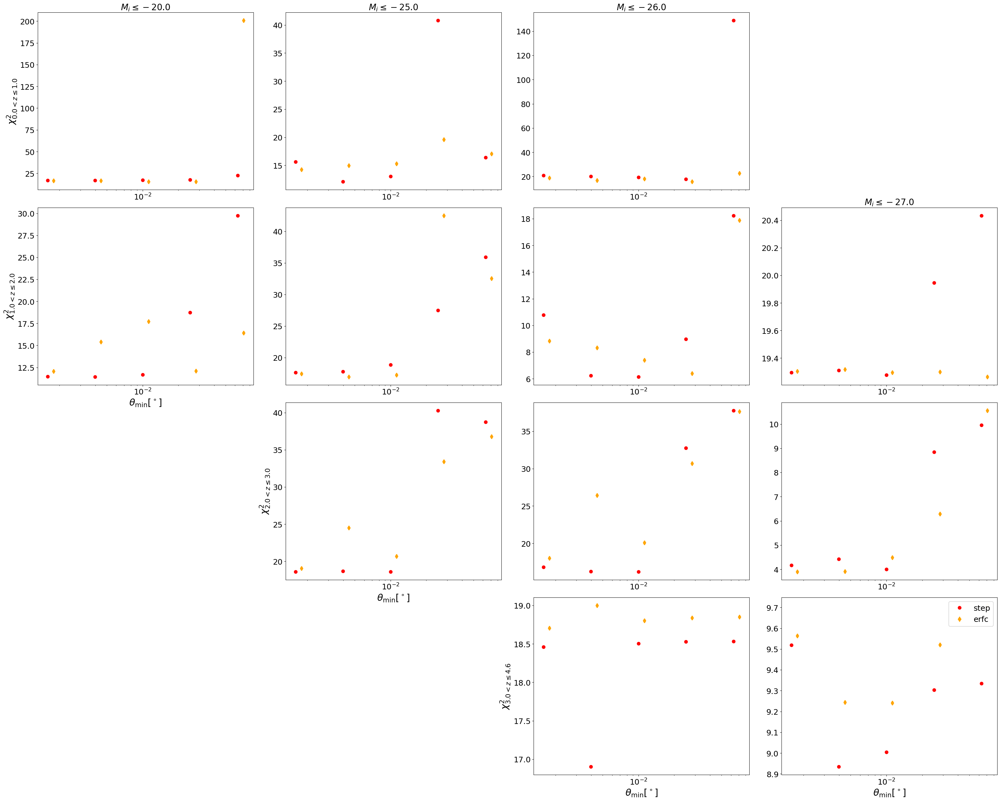

In [58]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
    
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i]) 
            
            for l, ndim in enumerate(ndim_array):
                
                for k, log_thetamin in enumerate(log_thetamin_array):

                    theta_mask=(quaia.recenter(np.log10(thetabins))>=float('{:.1f}'.format(log_thetamin))) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
                    nbins_mask = np.sum(theta_mask)
                    # print(nbins_mask)

                    try:

                        # file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                        #     G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, nlive, sample) 
                        # # print(file)
                        
                        # # read the results
                        # with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        #         results = pickle.load(fp)
                    
                        # logz = results.logz[-1]
                        # logzerr = results.logzerr[-1]
                    
                        # ax1.errorbar(10**(log_thetamin+0.05*l), logz, yerr = logzerr, linewidth = 2.5, marker = marker[l], markeredgewidth = 2.5, capsize = 2.5, linestyle = 'None', 
                        ax1.scatter(10**(log_thetamin+0.05*l), chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, 
                                                                    nbins_mask = nbins_mask)[0],
                                    linewidth = 2.5, marker = marker[l], linestyle = 'None', label = 'ndim={}'.format(ndim), 
                                    color = colors[l]) #cmaps[l][k]) #orange')

                    except Exception as e:
                        print(e)

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))

            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel('$\chi^2_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta_\mathrm{min} [^\circ]$')
            ax1.set_xscale('log')          
    
custom_lines = [Line2D([0], [0], color = colors[l], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5) for l in range(len(ndim_array))] #np.mean(cmaps[l], axis = 0)
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'upper right')
fig.add_artist(second_legend)
                    
plt.show()

# Select fiducial parameters

In [46]:
log_thetamin = -2.8 #-1
log_thetamax = 0.0
theta_mask=(quaia.recenter(np.log10(thetabins))>=log_thetamin) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
nbins_mask = np.sum(theta_mask)
dlogz = 0.001 #01
sample = 'auto'
nlive = 1500 #2000
ndim_array = [2,3]

In [47]:
def make_contour_cmap(color, n_levels, alpha_min=0, alpha_max=1.0):
    
    cmap = []
    alphas = np.linspace(0,alpha_max,n_levels+1)
    for alpha in alphas:
        rgba = np.array(mcolors.to_rgba(color))
        rgba[-1] = alpha
        cmap.append(rgba)

    return cmap

In [48]:
quantile_2d = 1.0 - np.exp(-0.5 * np.array([1, 2])**2)#, 3])**2)
quantile_2d

array([0.39346934, 0.86466472])

In [49]:
smooth = [[0.04, 0.05, 0.03, 0.05], [0.09, 0.09, 0.08, 0.09]] # 0.05 # 0.08

In [50]:
N_max = np.max(np.array([N_q[L_bin] for L_bin in L_bins]).flatten())

<>:66: SyntaxWarning: invalid escape sequence '\l'
<>:66: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/3869893549.py:66: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


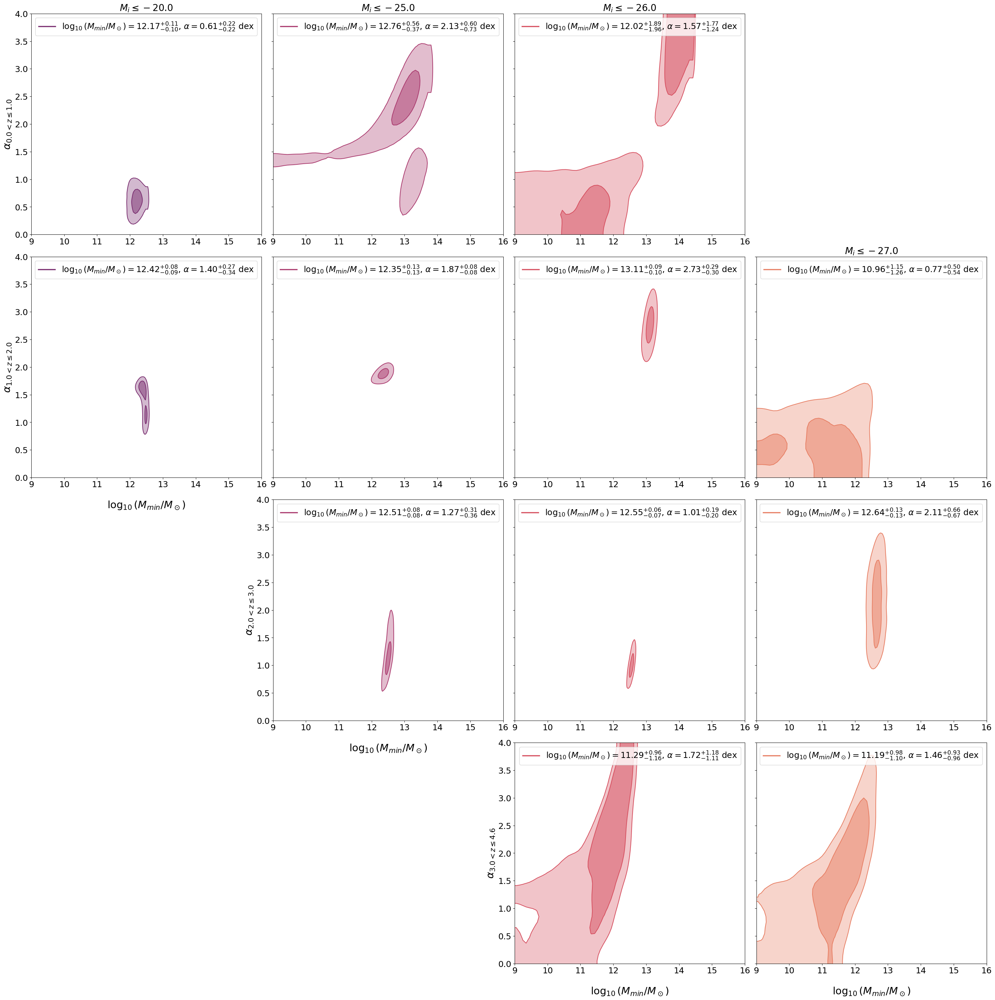

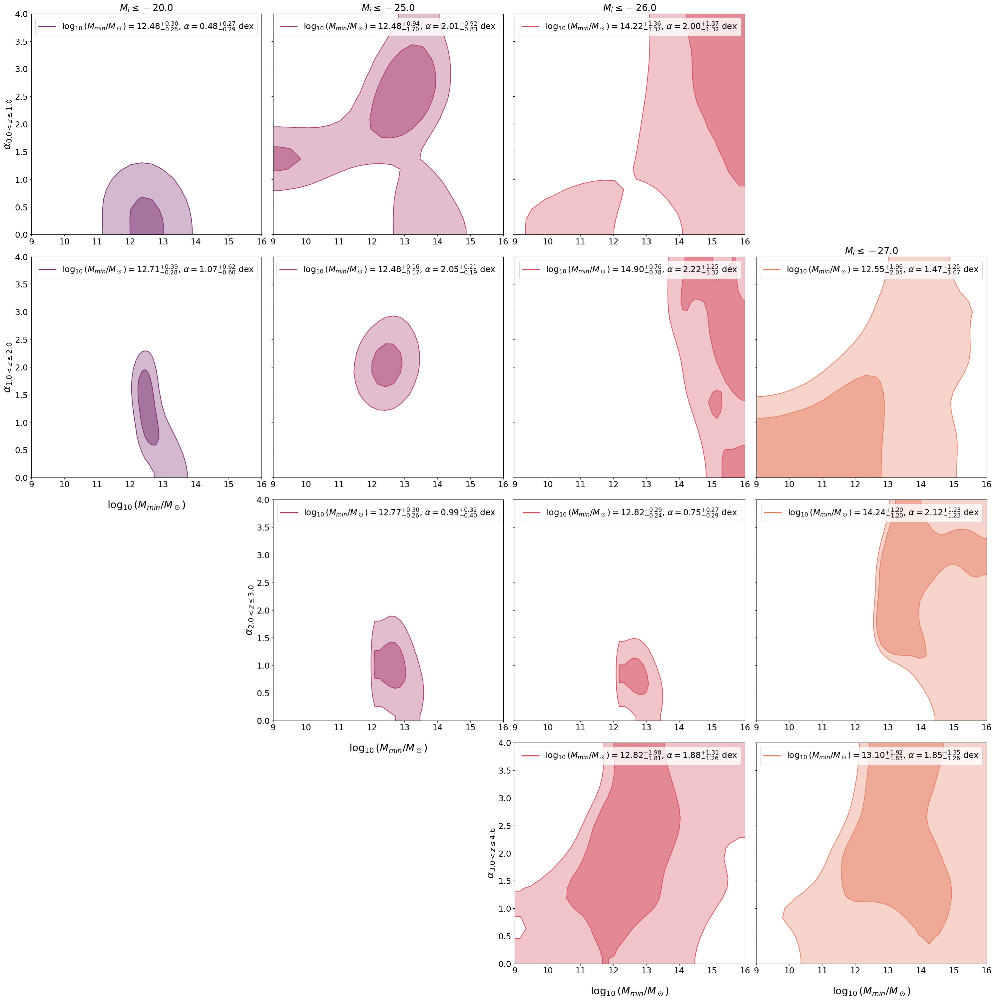

In [64]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):
    
    fig = plt.figure(figsize = (37, 37))
    gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)
    
    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

                ax1 = fig.add_subplot(gs[j*4+i])

                try:

                    if ndim == 2:
                        sigma='_Sigma0.0'
                    else:
                        sigma=''
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
                            
                    samples, weights = results.samples, results.importance_weights() # try to figure out a way to do this without results_Mmin, I think I can? its from the stuff ive already saved
                    equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                    # print(len(samples))
                    # --- corner plot -> buffer -> master cell ---
                    contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile))}
                    contour_kwargs = {'colors': [cmap_theta[i]]}
                    dyplot._hist2d(equal_weight_samples[:, 0], equal_weight_samples[:, 1], color=cmap_theta[i], levels = quantile_2d,
                                   contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs, smooth = smooth[l][j])
                                   # smooth = 0.02/(np.log10(N_q[L_bins[i]][j])/np.log10(N_max))**5)
                                   # smooth = 0.02/(len(samples)/22247)**3) #, fill_contours = False)
                    
                    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for k, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[k]
                        
                        legend.append(f"${ylabels[k]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                    custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
                    ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
                    ax1.xaxis.set_label_coords(0.5, -0.1)
                
                except Exception as e:
                    print(e)
                                
                ax1.set_xlim(9, 16)
                ax1.set_ylim(0,4)
                # titles & labels
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[1],
                        z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticklabels([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('${}$'.format(ylabels[0]))
                plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
                # ... rest of your existing sample/quantile code ...
                
    # fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
    plt.show()

In [65]:
cmaps = [cmap_theta, cmap]

<>:91: SyntaxWarning: invalid escape sequence '\l'
<>:91: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/2799794854.py:91: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


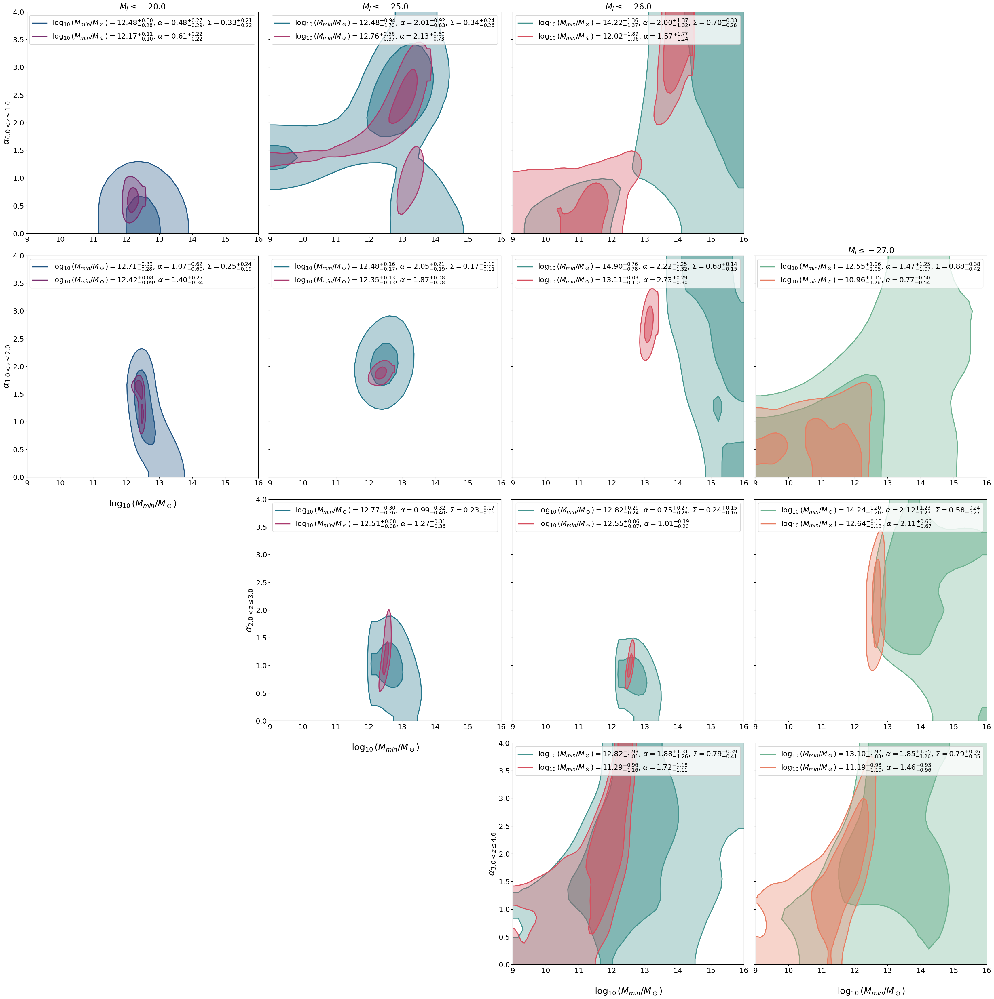

In [66]:
# remove bottom panel and just print bq somewhere
# plot!
# for ndim in ndim_array:

fig = plt.figure(figsize = (43, 43))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            custom_lines, custom_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):
                # k = 0
                try:
                
                    if ndim == 2:
                        sigma='_Sigma0.0'
                    else:
                        sigma=''
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
                            
                    samples, weights = results.samples, results.importance_weights() # try to figure out a way to do this without results_Mmin, I think I can? its from the stuff ive already saved
                    equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                    
                    # --- corner plot -> buffer -> master cell ---
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile))}
                    if ndim == 2:
                        linewidth = 2.5
                        no_fill_contours = True
                        zorder = 3
                        # contour_kwargs = {'colors': [cmaps[k][i]], 'linewidths': 2.5}
                    else:
                        linewidth = 2.5
                        no_fill_contours = True
                        zorder = 1
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    # if ndim == 2:
                    #     color = 'k'
                    #     contourf_kwargs = None
                    #     contour_kwargs = None
                    #     plot_density = False
                    #     no_fill_contours = True
                    # else:
                    #     color = cmaps[k][i]
                    #     contourf_kwargs = {'colors': make_contour_cmap(cmaps[k][i], len(quantile))}
                    #     contour_kwargs = {'colors': [cmaps[k][i]]}
                    #     plot_density = True
                    #     no_fill_contours = True
                    dyplot._hist2d(equal_weight_samples[:, 0], equal_weight_samples[:, 1], color=cmaps[k][i], levels = quantile_2d,
                                   contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs, smooth = smooth[::-1][k][j], #, plot_density = plot_density) 
                                   no_fill_contours = no_fill_contours)
    
                    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                    custom_lines.append(Line2D([0], [0], color = cmaps[::-1][k][i], linestyle = '-', linewidth=linewidth))
                    if ndim == 2:
                        custom_labels.append('{}, {}'.format(legend[0],legend[1]))
                    else:
                        custom_labels.append('{}, {}, {}'.format(legend[0],legend[1],legend[2]))
                
                except Exception as e:
                    print(e)
                                
                ax1.set_xlim(9, 16)
                ax1.set_ylim(0,4)
                # titles & labels
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[1],
                        z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticklabels([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('${}$'.format(ylabels[0]))
                plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
                # ... rest of your existing sample/quantile code ...

            ax1.legend(handles=custom_lines, labels=custom_labels)
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:81: SyntaxWarning: invalid escape sequence '\l'
<>:81: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/3541755451.py:81: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


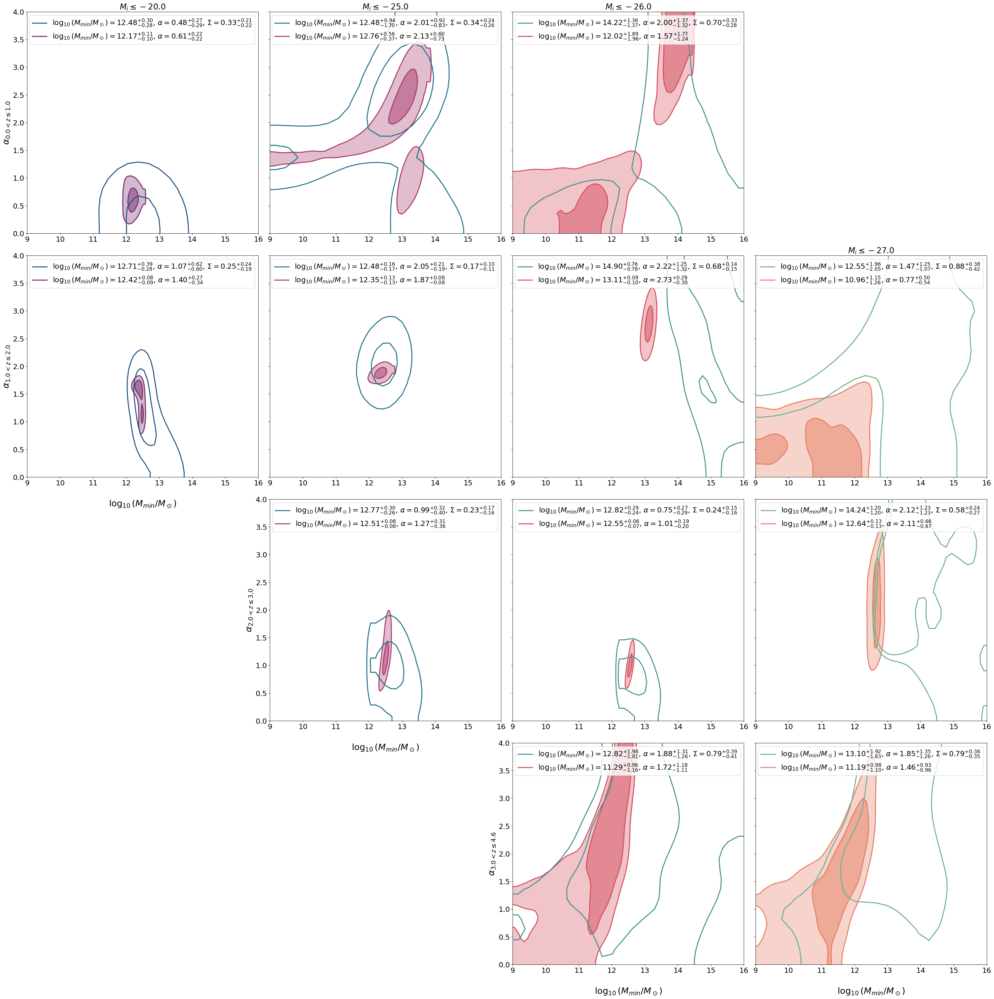

In [67]:
# remove bottom panel and just print bq somewhere
# plot!
# for ndim in ndim_array:

fig = plt.figure(figsize = (43, 43))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            custom_lines, custom_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):
                try:
                
                    if ndim == 2:
                        sigma='_Sigma0.0'
                    else:
                        sigma=''
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
                            
                    samples, weights = results.samples, results.importance_weights() # try to figure out a way to do this without results_Mmin, I think I can? its from the stuff ive already saved
                    equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                    
                    # --- corner plot -> buffer -> master cell ---
                    if ndim == 2:
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 1
                    else:
                        linewidth = 2.5
                        fill_contours = False
                        plot_density = False
                        no_fill_contours = True
                        zorder = 3
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot._hist2d(equal_weight_samples[:, 0], equal_weight_samples[:, 1], color=cmaps[k][i], levels = quantile_2d,
                                   contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs, smooth = smooth[::-1][k][j], #, plot_density = plot_density) 
                                   no_fill_contours = no_fill_contours, fill_contours = fill_contours, plot_density = plot_density)
    
                    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                    custom_lines.append(Line2D([0], [0], color = cmaps[::-1][k][i], linestyle = '-', linewidth=linewidth))
                    if ndim == 2:
                        custom_labels.append('{}, {}'.format(legend[0],legend[1]))
                    else:
                        custom_labels.append('{}, {}, {}'.format(legend[0],legend[1],legend[2]))
                
                except Exception as e:
                    print(e)
                                
                ax1.set_xlim(9, 16)
                ax1.set_ylim(0,4)
                # titles & labels
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[1],
                        z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticklabels([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('${}$'.format(ylabels[0]))
                plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
                # ... rest of your existing sample/quantile code ...

            ax1.legend(handles=custom_lines, labels=custom_labels)
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:81: SyntaxWarning: invalid escape sequence '\l'
<>:81: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/647565919.py:81: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


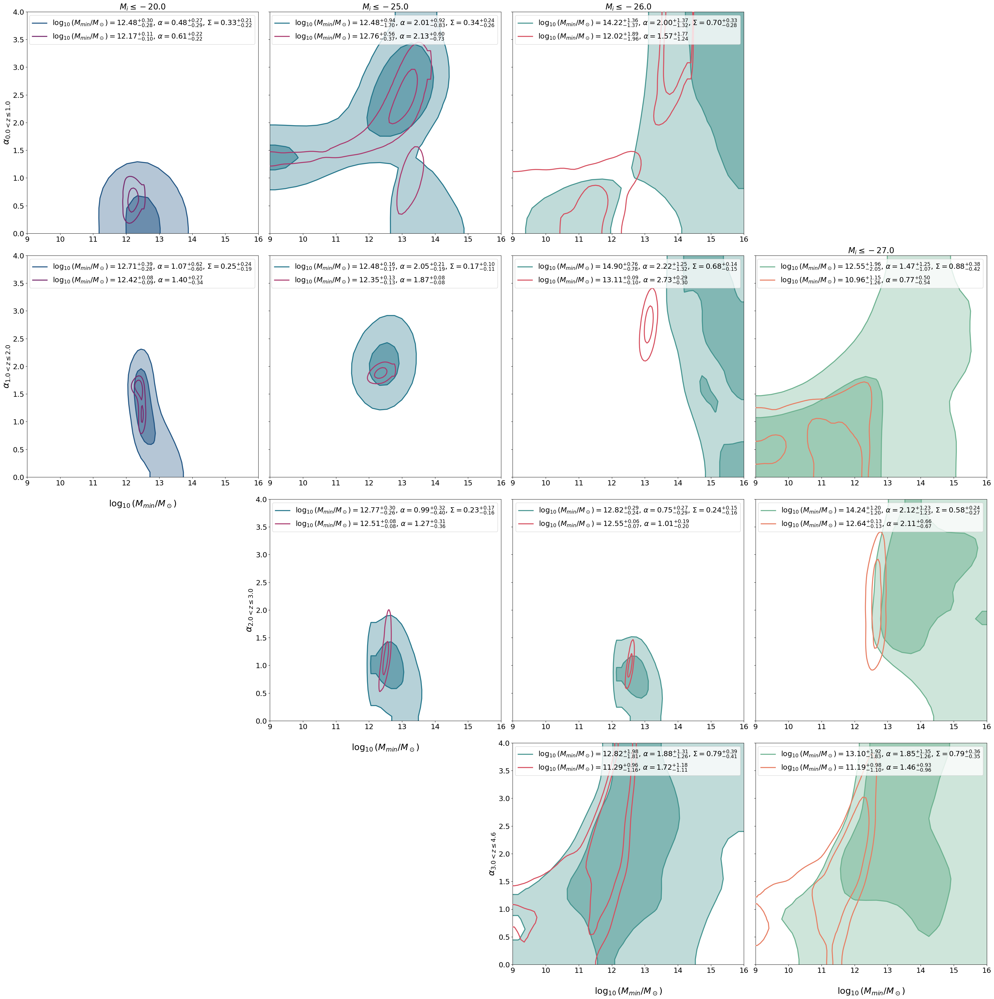

In [68]:
# remove bottom panel and just print bq somewhere
# plot!
# for ndim in ndim_array:

fig = plt.figure(figsize = (43, 43))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            custom_lines, custom_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):
                try:
                
                    if ndim == 2:
                        sigma='_Sigma0.0'
                    else:
                        sigma=''
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
                            
                    samples, weights = results.samples, results.importance_weights() # try to figure out a way to do this without results_Mmin, I think I can? its from the stuff ive already saved
                    equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                    
                    # --- corner plot -> buffer -> master cell ---
                    if ndim == 2:
                        linewidth = 2.5
                        fill_contours = False
                        plot_density = False
                        no_fill_contours = True
                        zorder = 3
                    else:
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 1
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot._hist2d(equal_weight_samples[:, 0], equal_weight_samples[:, 1], color=cmaps[k][i], levels = quantile_2d,
                                   contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs, smooth = smooth[::-1][k][j], #, plot_density = plot_density) 
                                   no_fill_contours = no_fill_contours, fill_contours = fill_contours, plot_density = plot_density)
    
                    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                    custom_lines.append(Line2D([0], [0], color = cmaps[::-1][k][i], linestyle = '-', linewidth=linewidth))
                    if ndim == 2:
                        custom_labels.append('{}, {}'.format(legend[0],legend[1]))
                    else:
                        custom_labels.append('{}, {}, {}'.format(legend[0],legend[1],legend[2]))
                
                except Exception as e:
                    print(e)
                                
                ax1.set_xlim(9, 16)
                ax1.set_ylim(0,4)
                # titles & labels
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[1],
                        z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticklabels([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('${}$'.format(ylabels[0]))
                plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
                # ... rest of your existing sample/quantile code ...

            ax1.legend(handles=custom_lines, labels=custom_labels)
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:73: SyntaxWarning: invalid escape sequence '\l'
<>:73: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/3639320653.py:73: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


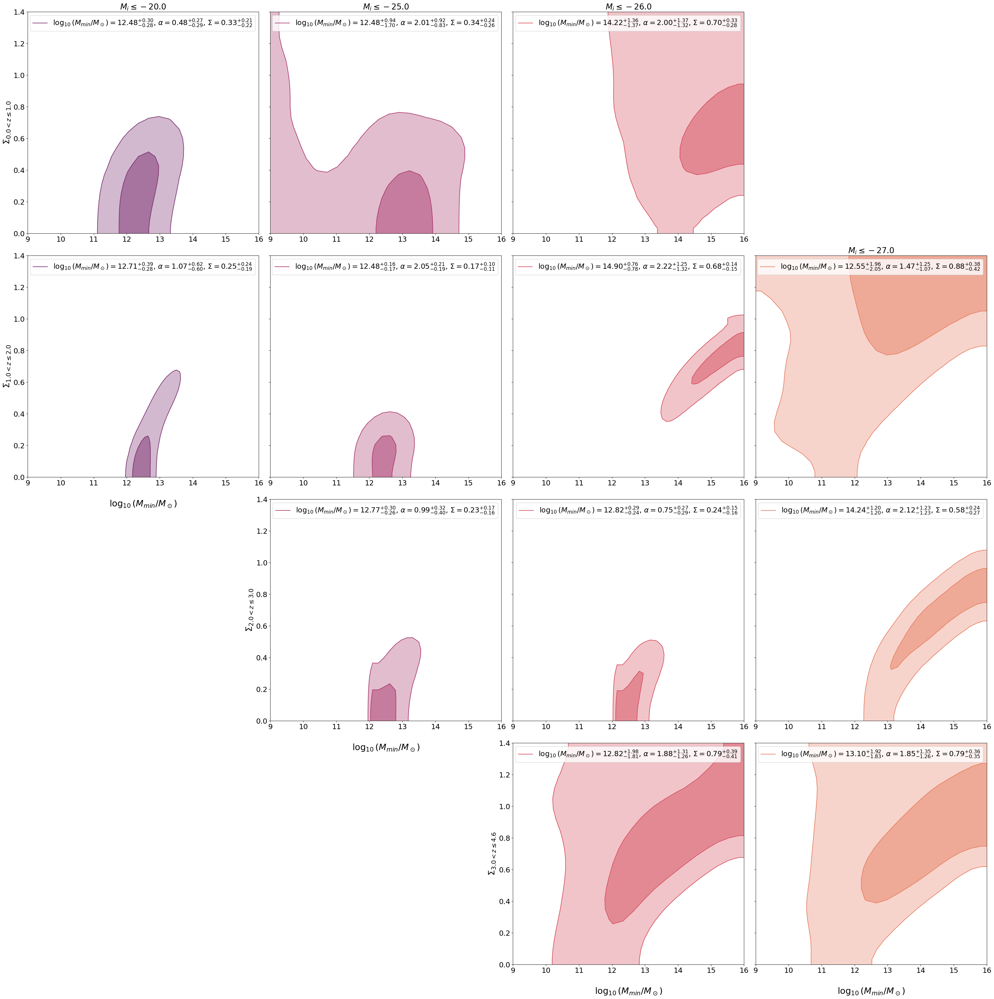

In [69]:
ndim = 3
fig = plt.figure(figsize = (43, 43))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            custom_lines, custom_labels = [], []
            # for k, ndim in enumerate(ndim_array):
                # k = 0
            try:
                
                k = 0
                if ndim == 2:
                    sigma='_Sigma0.0'
                else:
                    sigma=''
                file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                    nlive, sample) 
                
                # read the results
                with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                    results = pickle.load(fp)
                        
                samples, weights = results.samples, results.importance_weights() # try to figure out a way to do this without results_Mmin, I think I can? its from the stuff ive already saved
                equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                
                # --- corner plot -> buffer -> master cell ---
                contourf_kwargs = {'colors': make_contour_cmap(cmaps[k][i], len(quantile))}
                if ndim == 2:
                    linewidth = 2.5
                    # contour_kwargs = {'colors': [cmaps[k][i]], 'linewidths': 2.5}
                else:
                    linewidth = 1.5
                contour_kwargs = {'colors': [cmaps[k][i]], 'linewidths': linewidth}
                
                dyplot._hist2d(equal_weight_samples[:, 0], equal_weight_samples[:, 2], color=cmaps[k][i], levels = quantile_2d,
                               contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs, smooth = 0.09) #, plot_density = plot_density) 
                               # no_fill_contours = no_fill_contours)

                # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                             for k in range(samples.shape[1])]

                # Compute weighted mean and covariance.
                mean, cov = dyfunc.mean_and_cov(samples, weights)
                
                legend=[]
                for l, (lo, mid, hi) in enumerate(quantiles):

                    mid = mean[l]
                    
                    legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                custom_lines = [Line2D([0], [0], color = cmaps[k][i], linestyle = '-', linewidth=linewidth)]
                custom_labels = ['{}, {}, {}'.format(legend[0],legend[1],legend[2])]
                ax1.legend(handles=custom_lines, labels=custom_labels)
                ax1.xaxis.set_label_coords(0.5, -0.1)
            
            except Exception as e:
                print(e)
                            
            ax1.set_xlim(9, 16)
            ax1.set_ylim(0,1.4)
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[2],
                    z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel('${}$'.format(ylabels[0]))
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:71: SyntaxWarning: invalid escape sequence '\l'
<>:71: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/1361924085.py:71: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


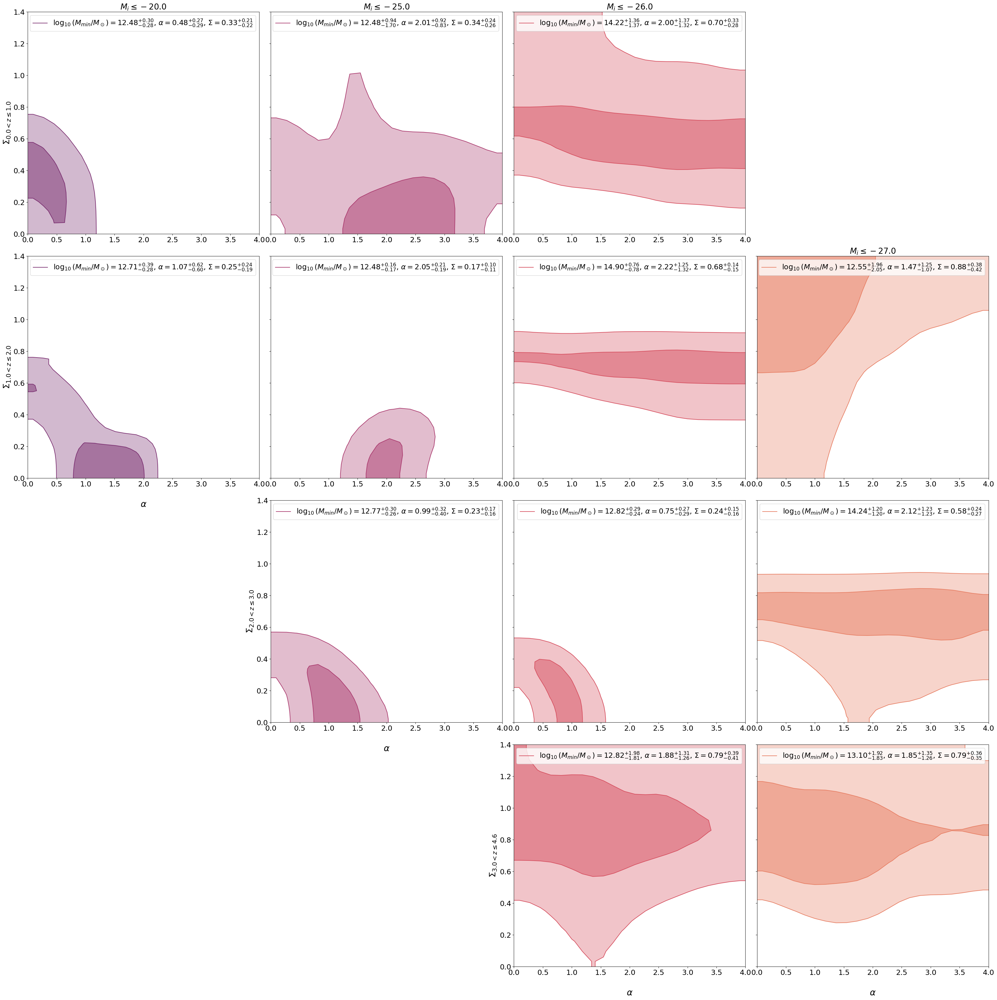

In [70]:
ndim = 3
fig = plt.figure(figsize = (43, 43))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            custom_lines, custom_labels = [], []
            try:
                
                k = 0
                # if ndim == 2:
                #     sigma='_Sigma0.0'
                # else:
                #     sigma=''
                file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, 
                    nlive, sample) 
                
                # read the results
                with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                    results = pickle.load(fp)
                        
                samples, weights = results.samples, results.importance_weights() # try to figure out a way to do this without results_Mmin, I think I can? its from the stuff ive already saved
                equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                
                # --- corner plot -> buffer -> master cell ---
                contourf_kwargs = {'colors': make_contour_cmap(cmaps[k][i], len(quantile))}
                if ndim == 2:
                    linewidth = 2.5
                    # contour_kwargs = {'colors': [cmaps[k][i]], 'linewidths': 2.5}
                else:
                    linewidth = 1.5
                contour_kwargs = {'colors': [cmaps[k][i]], 'linewidths': linewidth}
                
                dyplot._hist2d(equal_weight_samples[:, 1], equal_weight_samples[:, 2], color=cmaps[k][i], levels = quantile_2d,
                               contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs, smooth = 0.09) #, plot_density = plot_density) 
                               # no_fill_contours = no_fill_contours)

                # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                             for k in range(samples.shape[1])]

                # Compute weighted mean and covariance.
                mean, cov = dyfunc.mean_and_cov(samples, weights)
                
                legend=[]
                for l, (lo, mid, hi) in enumerate(quantiles):

                    mid = mean[l]
                    
                    legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                custom_lines = [Line2D([0], [0], color = cmaps[k][i], linestyle = '-', linewidth=linewidth)]
                custom_labels = ['{}, {}, {}'.format(legend[0],legend[1],legend[2])]
                ax1.legend(handles=custom_lines, labels=custom_labels)
                ax1.xaxis.set_label_coords(0.5, -0.1)
            
            except Exception as e:
                print(e)
                            
            ax1.set_xlim(0, 4)
            ax1.set_ylim(0,1.4)
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[2],
                    z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel('${}$'.format(ylabels[1]))
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

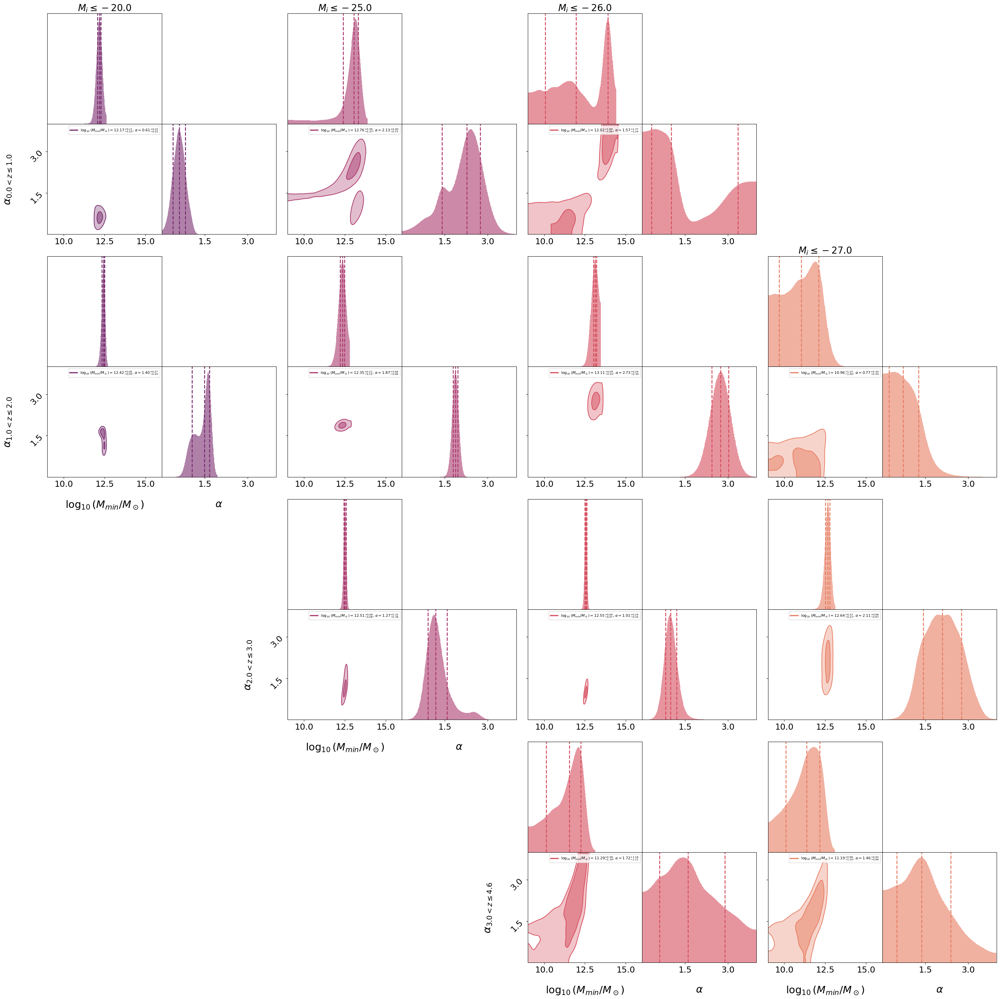

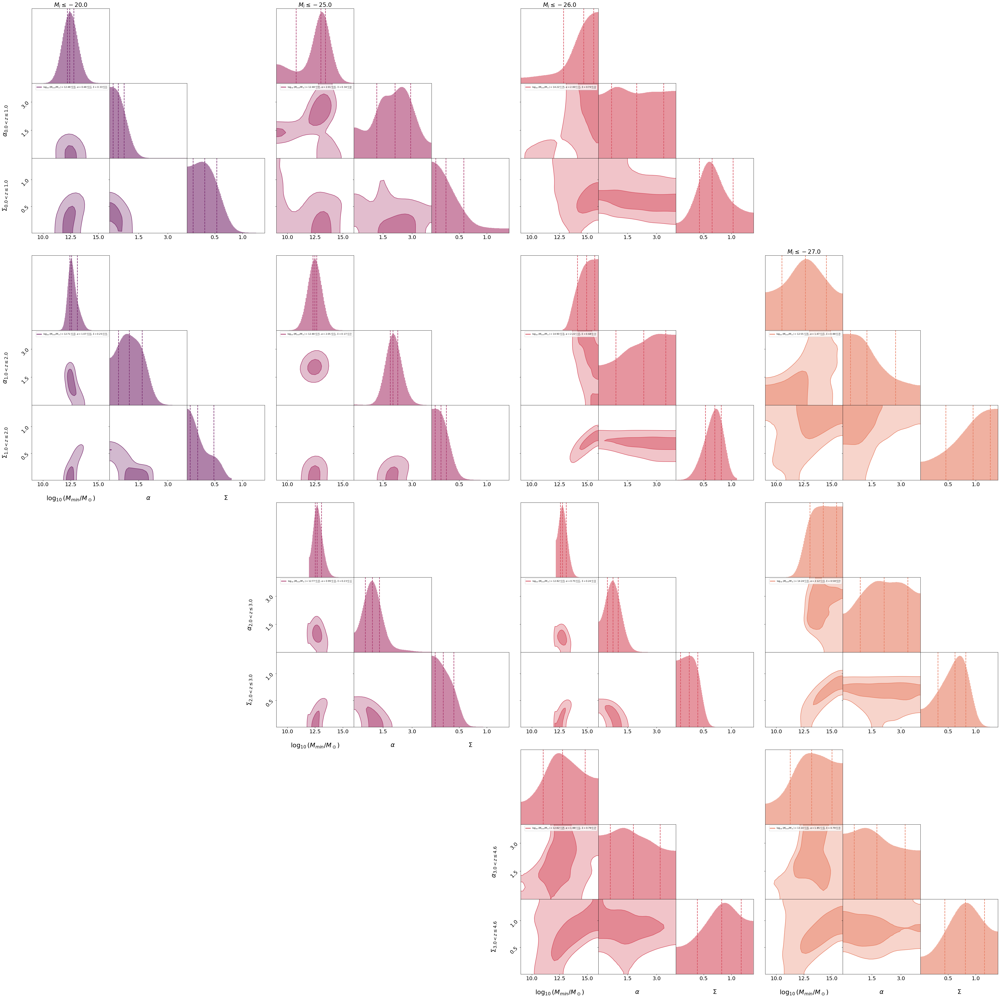

In [71]:
# plot!
for m, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize=(57/3*ndim, 57/3*ndim))
    gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)

    for j in range(len(z_array)):

        for i in range(len(L_bins)):

            if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

                # carve an ndim x ndim sub-grid out of this outer cell
                sub_gs = gs[j*4+i].subgridspec(ndim, ndim, wspace=0.0, hspace=0.0)
                ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(ndim)]
                                     for r in range(ndim)])

                try:
                    if ndim == 2:
                        sigma='_Sigma0.0'
                    else:
                        sigma=''
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
                        
                    # # --- load primary results (whatever ndim this outer loop is on) ---
                    # file_primary = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                    #     G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1],
                    #     L_bins[i], cosmo, ndim, dlogz, nlive, sample)
                    # with open('../results/results{}.npy'.format(file_primary), 'rb') as fp:
                    #     results_primary = pickle.load(fp)

                    samples, weights = results.samples, results.importance_weights()

                    # dims_primary = list(range(ndim))   # <-- fixed: matches actual samples width

                    contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile))}
                    contour_kwargs = {'colors': [cmap_theta[i]]}
                    dyplot.cornerplot(results, color=cmap_theta[i], hist2d_kwargs = {'contourf_kwargs': 
                                                                                     contourf_kwargs, 'contour_kwargs': contour_kwargs}, 
                           max_n_ticks=3, quantiles=quantile, quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                      # labels=['${}$'.format(ylabel) for ylabel in ylabels],
                                      fig=(fig, ax), smooth = smooth[m][j])
                    
                    # dyplot.cornerplot(
                    #     results_primary,
                    #     dims=dims_primary,
                    #     fig=(fig, axesNxN),
                    #     color=cmap_theta[i],
                    #     hist2d_kwargs={'contourf_kwargs': contourf_kwargs_p,
                    #                    'contour_kwargs': contour_kwargs_p},
                    #     quantiles_2d=quantile_2d,
                    #     quantiles=quantile,
                    #     labels=[ylabels[k] for k in dims_primary],
                    #     show_titles=False,
                    #     max_n_ticks=3,
                    #     smooth=0.02,
                    # )

                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")
                    
                    # legend_primary = []
                    # for k, (lo, mid, hi) in enumerate(quantiles_primary):
                    #     legend_primary.append(f"${ylabels[k]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                    custom_lines = [Line2D([0], [0], color=cmap_theta[i], linestyle='-', linewidth=2.5)]
                    if ndim == 2:
                        legend_labels = ['{}, {}'.format(legend[0], legend[1])]
                    else:
                        legend_labels = ['{}, {}, {}'.format(legend[0], legend[1], legend[2])]

                    # --- only attempt overlay if primary model has room for it ---
                    # if ndim > 2:
                    #     try:
                    #         file_2p = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                    #             G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1],
                    #             L_bins[i], cosmo, 2, dlogz, nlive, sample)
                    #         with open('../results/results{}.npy'.format(file_2p), 'rb') as fp:
                    #             results_2p = pickle.load(fp)

                    #         samples_2p = results_2p.samples
                    #         weights_2p = results_2p.importance_weights()
                    #         dims_2p = [0, 1]
                    #         sub_axes = axesNxN[0:2, 0:2]

                    #         contourf_kwargs_2p = {'colors': make_contour_cmap(cmap_theta_2p[i], len(quantile))}
                    #         contour_kwargs_2p = {'colors': [cmap_theta_2p[i]]}

                    #         dyplot.cornerplot(
                    #             results_2p,
                    #             dims=dims_2p,
                    #             fig=(fig, sub_axes),
                    #             color=cmap_theta_2p[i],
                    #             hist2d_kwargs={'contourf_kwargs': contourf_kwargs_2p,
                    #                            'contour_kwargs': contour_kwargs_2p},
                    #             quantiles_2d=quantile_2d,
                    #             quantiles=quantile,
                    #             labels=None,
                    #             show_titles=False,
                    #             max_n_ticks=3,
                    #             smooth=0.02,
                    #             fill_contours=False,
                    #         )

                    #         quantiles_2p_vals = [dyfunc.quantile(samples_2p[:, k], quantile, weights=weights_2p)
                    #                               for k in range(samples_2p.shape[1])]
                    #         legend_2p = []
                    #         for k, (lo, mid, hi) in enumerate(quantiles_2p_vals):
                    #             legend_2p.append(f"${ylabels[k]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                    #         custom_lines.append(Line2D([0], [0], color=cmap_theta_2p[i], linestyle='-', linewidth=2.5))
                    #         legend_labels.append('2-param: {}, {}'.format(legend_2p[0], legend_2p[1]))

                    #     except FileNotFoundError as e2:
                    #         print('No 2-param overlay for bin (j={}, i={}): {}'.format(j, i, e2))

                    ax1 = ax[1, 0]
                    ax1.legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')
                    # ax1.xaxis.set_label_coords(0.5, -0.1)

                # except FileNotFoundError as e1:
                #     print('No primary results for bin (j={}, i={}): {}'.format(j, i, e1))
                #     continue
                except Exception as e:
                    print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))
                    # continue

                # --- axis limits/labels on the main Mmin-alpha panel ---
                # ax1 = ax[1, 0]
                # ax1.set_xlim(9, 16)
                ax[1, 0].set_ylim(0, 4)
                ax[1, 1].set_xlim(0, 4)
                if ndim==3:
                    ax[-1, 0].set_ylim(0, 1.4)
                    ax[-1, 1].set_ylim(0, 1.4)
                    ax[-1, 1].set_xlim(0, 4)
                    ax[-1, -1].set_xlim(0, 1.4)

                if j == 0 or ((j == 1) and (i == 3)):
                    ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
                for k, axis in enumerate(ax[:, 0]):
                    axis.set_xlim(9, 16)
                    if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                        axis.set_yticklabels([])
                    elif k>0:
                        axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]))
                for k, axis in enumerate(ax[-1, :]):
                    axis.xaxis.set_label_coords(0.5, -0.2)
                    if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                        # ax1.set_xlabel('${}$'.format(ylabels[0]))
                        axis.set_xlabel('${}$'.format(ylabels[k]))
                    plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

    # fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(ndim), bbox_inches='tight')
    plt.show()

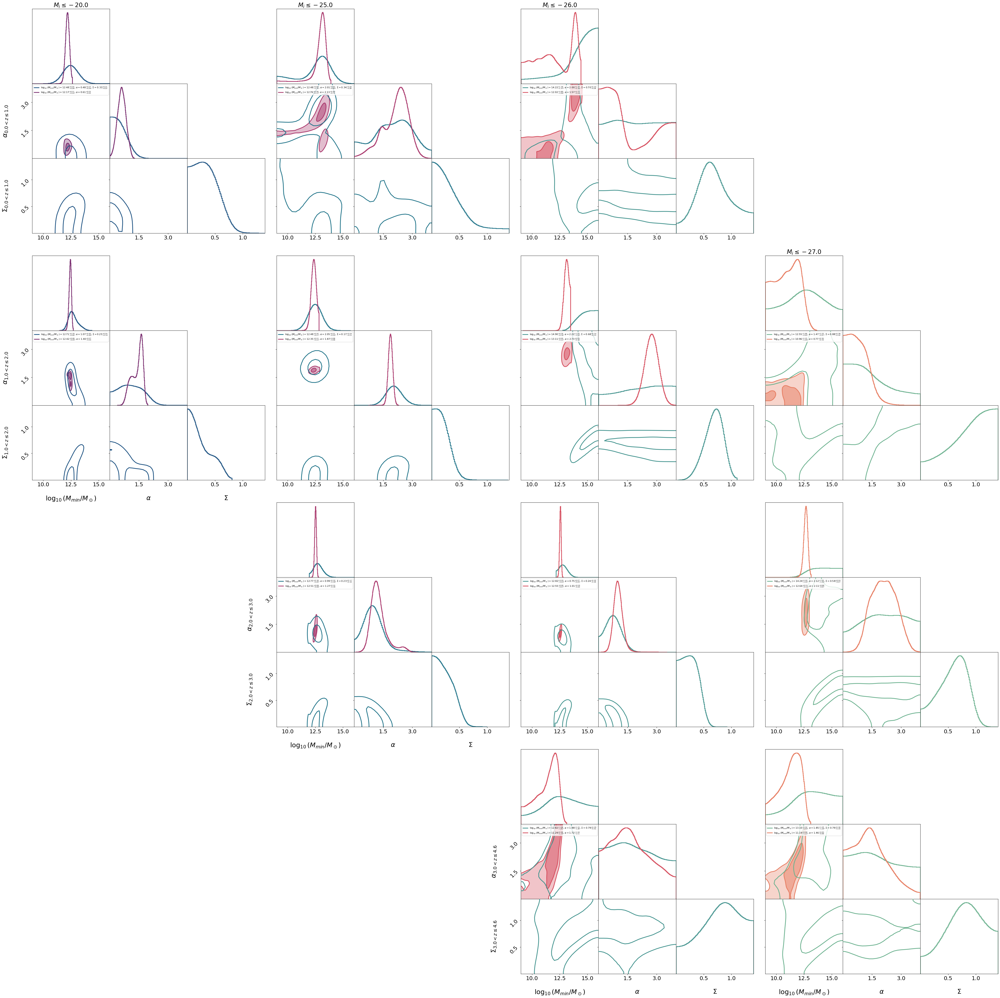

In [72]:
# ndim_primary = 3     # model whose full corner grid gets drawn
# ndim_overlay = 2      # model overlaid on just the Mmin-alpha block
# cmap_theta_2p = cmap_theta
# fig = plt.figure(figsize=(37, 37))
# gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)

# for j in range(len(z_array)):

#     for i in range(len(L_bins)):

#         if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) \
#            and (np.round(N_q[L_bins[i]][j]/1000) > 1):

#             # carve an ndim_primary x ndim_primary sub-grid out of this outer cell
#             sub_gs = gs[j*4 + i].subgridspec(ndim_primary, ndim_primary, wspace=0.05, hspace=0.05)
#             axesNxN = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(ndim_primary)]
#                                  for r in range(ndim_primary)])

#             custom_lines = []
#             legend_labels = []

#             try:
#                 # --- primary (3-param) model ---
#                 file_primary = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
#                     G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1],
#                     L_bins[i], cosmo, ndim_primary, dlogz, nlive, sample)
#                 with open('../results/results{}.npy'.format(file_primary), 'rb') as fp:
#                     results_primary = pickle.load(fp)

#                 samples_primary = results_primary.samples
#                 weights_primary = results_primary.importance_weights()
#                 dims_primary = list(range(ndim_primary))

#                 contourf_kwargs_p = {'colors': make_contour_cmap(cmap_theta[i], len(quantile))}
#                 contour_kwargs_p = {'colors': [cmap_theta[i]]}

#                 dyplot.cornerplot(
#                     results_primary,
#                     dims=dims_primary,
#                     fig=(fig, axesNxN),
#                     color=cmap_theta[i],
#                     hist2d_kwargs={'contourf_kwargs': contourf_kwargs_p,
#                                    'contour_kwargs': contour_kwargs_p},
#                     quantiles_2d=quantile_2d,
#                     quantiles=quantile,
#                     labels=[ylabels[k] for k in dims_primary],
#                     show_titles=False,
#                     max_n_ticks=3,
#                     smooth=0.02,
#                 )

#                 quantiles_primary = [dyfunc.quantile(samples_primary[:, k], quantile, weights=weights_primary)
#                                       for k in range(samples_primary.shape[1])]
#                 legend_primary = [f"${ylabels[k]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$"
#                                    for k, (lo, mid, hi) in enumerate(quantiles_primary)]

#                 custom_lines.append(Line2D([0], [0], color=cmap_theta[i], linestyle='-', linewidth=2.5))
#                 legend_labels.append('{}-param: {}, {}'.format(ndim_primary, legend_primary[0], legend_primary[1]))

#             except FileNotFoundError as e1:
#                 print('No primary results for bin (j={}, i={}): {}'.format(j, i, e1))
#                 continue
#             except Exception as e:
#                 print('Unexpected error (primary) for bin (j={}, i={}): {}'.format(j, i, e))
#                 continue

#             # --- overlay (2-param) model, drawn into the SAME axes object as the primary Mmin-alpha block ---
#             try:
#                 file_overlay = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
#                     G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1],
#                     L_bins[i], cosmo, ndim_overlay, dlogz, nlive, sample)
#                 with open('../results/results{}.npy'.format(file_overlay), 'rb') as fp:
#                     results_overlay = pickle.load(fp)

#                 samples_overlay = results_overlay.samples
#                 weights_overlay = results_overlay.importance_weights()
#                 dims_overlay = [0, 1]
#                 sub_axes = axesNxN[0:2, 0:2]   # existing Axes objects, sliced -- NOT new axes

#                 contourf_kwargs_o = {'colors': make_contour_cmap(cmap_theta_2p[i], len(quantile))}
#                 contour_kwargs_o = {'colors': [cmap_theta_2p[i]]}

#                 dyplot.cornerplot(
#                     results_overlay,
#                     dims=dims_overlay,
#                     fig=(fig, sub_axes),
#                     color=cmap_theta_2p[i],
#                     hist2d_kwargs={'contourf_kwargs': contourf_kwargs_o,
#                                    'contour_kwargs': contour_kwargs_o},
#                     quantiles_2d=quantile_2d,
#                     quantiles=quantile,
#                     labels=None,
#                     show_titles=False,
#                     max_n_ticks=3,
#                     smooth=0.02,
#                     # fill_contours=False,
#                 )

#                 quantiles_overlay = [dyfunc.quantile(samples_overlay[:, k], quantile, weights=weights_overlay)
#                                       for k in range(samples_overlay.shape[1])]
#                 legend_overlay = [f"${ylabels[k]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$"
#                                    for k, (lo, mid, hi) in enumerate(quantiles_overlay)]

#                 custom_lines.append(Line2D([0], [0], color=cmap_theta_2p[i], linestyle='-', linewidth=2.5))
#                 legend_labels.append('{}-param: {}, {}'.format(ndim_overlay, legend_overlay[0], legend_overlay[1]))

#             except FileNotFoundError as e2:
#                 print('No overlay results for bin (j={}, i={}): {}'.format(j, i, e2))

#             # --- legend, axis limits/labels on the main Mmin-alpha panel ---
#             ax1 = axesNxN[1, 0]
#             ax1.legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')
#             ax1.xaxis.set_label_coords(0.5, -0.1)
#             ax1.set_xlim(9, 16)
#             ax1.set_ylim(0, 4)

#             if j == 0 or ((j == 1) and (i == 3)):
#                 axesNxN[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
#             if i == 0 or ((j > 1) and (i < 3) and (i != j)):
#                 ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[1], z_bins[j], z_bins[j+1]))
#             else:
#                 ax1.set_yticklabels([])
#             if j > 2 or ((j > 0) and (i < 2) and (i != j)):
#                 ax1.set_xlabel('${}$'.format(ylabels[0]))
#             plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')

# # fig.savefig('../figures/cornerplot_Mmin_overlay_wtheta.pdf', bbox_inches='tight')
# plt.show()

# plot!
fig = plt.figure(figsize=(60, 60))
gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)
for j in range(len(z_array)):

    for i in range(len(L_bins)):

        if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

            # carve an ndim x ndim sub-grid out of this outer cell
            sub_gs = gs[j*4+i].subgridspec(3, 3, wspace=0.0, hspace=0.0) #0.05
            ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(3)]
                                 for r in range(3)])

            custom_lines, legend_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):

                try:
                    if ndim == 2:
                        sigma='_Sigma0.0'
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        zorder = 1
                    else:
                        sigma=''
                        linewidth = 2.5
                        fill_contours = False
                        plot_density = False
                        zorder = 3
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
    
                    samples, weights = results.samples, results.importance_weights()
    
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot.cornerplot(results, color=cmaps[::-1][k][i], hist2d_kwargs = {
                        'contourf_kwargs': contourf_kwargs, 'contour_kwargs': contour_kwargs, 'fill_contours': fill_contours, 
                        'plot_density': plot_density}, max_n_ticks=3, 
                                      quantiles=[], quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                      fig=(fig, ax[:ndim, :ndim]), smooth = smooth[::-1][k][j], hist_kwargs = {
                                          'density': True, 'histtype': 'step', 'linewidth': linewidth, 'alpha': 1})
    
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")
    
                    custom_lines.append(Line2D([0], [0], color=cmaps[::-1][k][i], linestyle='-', linewidth=linewidth))
                    if ndim == 2:
                        legend_labels.append('{}, {}'.format(legend[0], legend[1]))
                    else:
                        legend_labels.append('{}, {}, {}'.format(legend[0], legend[1], legend[2]))
                
                except Exception as e:
                    print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))

                ax1 = ax[1, 0]
                ax1.legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')
                
                # --- axis limits/labels on the main Mmin-alpha panel ---
                # ax1 = ax[1, 0]
                # ax1.set_xlim(9, 16)
                # ax1.set_ylim(0, 4)
                ax[1, 0].set_ylim(0, 4)
                ax[1, 1].set_xlim(0, 4)
                if ndim==3:
                    ax[-1, 0].set_ylim(0, 1.4)
                    ax[-1, 1].set_ylim(0, 1.4)
                    ax[-1, 1].set_xlim(0, 4)
                    ax[-1, -1].set_xlim(0, 1.4)
    
                if j == 0 or ((j == 1) and (i == 3)):
                    ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
                for k, axis in enumerate(ax[:, 0]):
                    axis.set_xlim(9, 16)
                    if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                        axis.set_yticklabels([])
                    elif k>0:
                        axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]))
                for k, axis in enumerate(ax[-1, :]):
                    axis.xaxis.set_label_coords(0.5, -0.2)
                    if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                        # ax1.set_xlabel('${}$'.format(ylabels[0]))
                        axis.set_xlabel('${}$'.format(ylabels[k]))
                    plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(ndim), bbox_inches='tight')
plt.show()

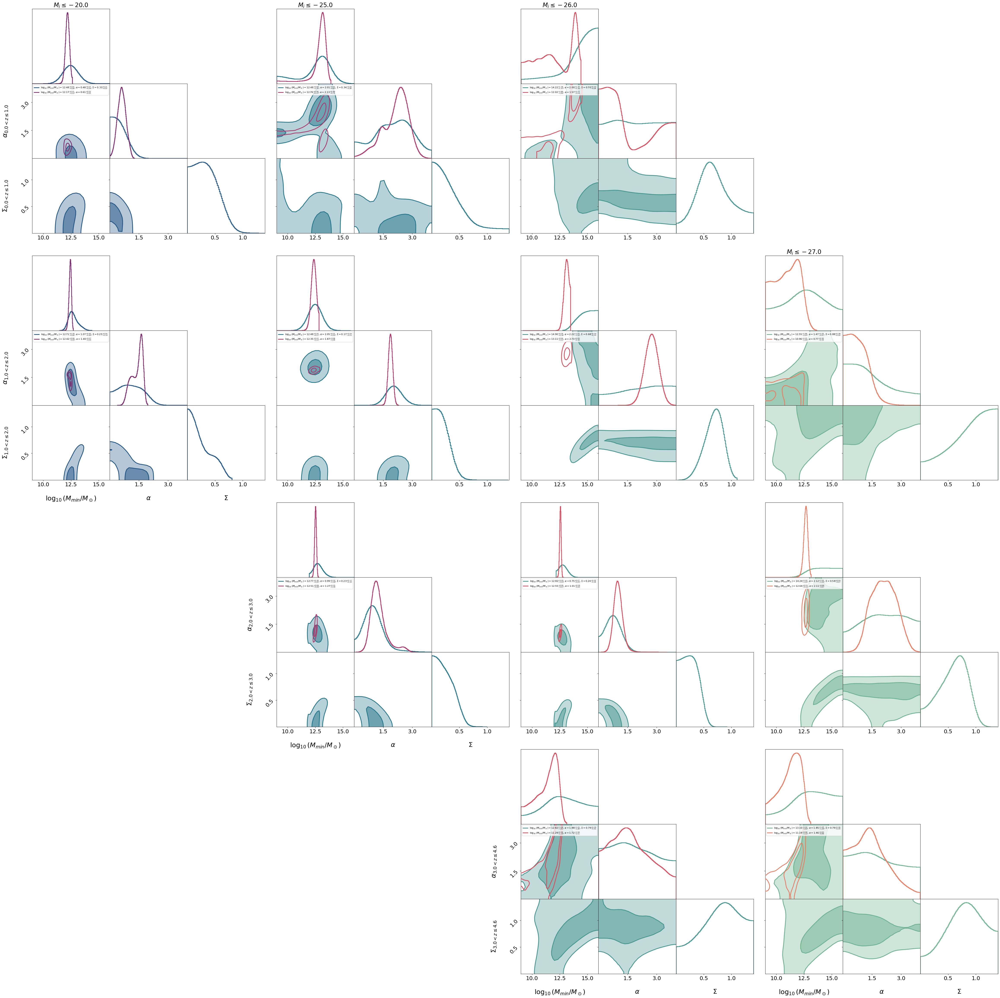

In [73]:
# plot!
fig = plt.figure(figsize=(60, 60))
gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)
for j in range(len(z_array)):

    for i in range(len(L_bins)):

        if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

            # carve an ndim x ndim sub-grid out of this outer cell
            sub_gs = gs[j*4+i].subgridspec(3, 3, wspace=0.0, hspace=0.0) #0.05
            ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(3)]
                                 for r in range(3)])

            custom_lines, legend_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):

                try:
                    if ndim == 2:
                        sigma='_Sigma0.0'
                        linewidth = 2.5
                        fill_contours = False
                        plot_density = False
                        no_fill_contours = True
                        zorder = 3
                    else:
                        sigma=''
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = False
                        zorder = 1
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
    
                    samples, weights = results.samples, results.importance_weights()
    
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot.cornerplot(results, color=cmaps[::-1][k][i], hist2d_kwargs = {
                        'contourf_kwargs': contourf_kwargs, 'contour_kwargs': contour_kwargs, 'fill_contours': fill_contours, 
                        'plot_density': plot_density, 'no_fill_contours': no_fill_contours}, max_n_ticks=3, 
                                      quantiles=[], quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                      fig=(fig, ax[:ndim, :ndim]), smooth = smooth[::-1][k][j], hist_kwargs = {
                                          'density': True, 'histtype': 'step', 'linewidth': linewidth, 'alpha': 1})
    
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")
    
                    custom_lines.append(Line2D([0], [0], color=cmaps[::-1][k][i], linestyle='-', linewidth=linewidth))
                    if ndim == 2:
                        legend_labels.append('{}, {}'.format(legend[0], legend[1]))
                    else:
                        legend_labels.append('{}, {}, {}'.format(legend[0], legend[1], legend[2]))
                
                except Exception as e:
                    print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))

                ax1 = ax[1, 0]
                ax1.legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')
                
                # --- axis limits/labels on the main Mmin-alpha panel ---
                ax[1, 0].set_ylim(0, 4)
                ax[1, 1].set_xlim(0, 4)
                if ndim==3:
                    ax[-1, 0].set_ylim(0, 1.4)
                    ax[-1, 1].set_ylim(0, 1.4)
                    ax[-1, 1].set_xlim(0, 4)
                    ax[-1, -1].set_xlim(0, 1.4)
    
                if j == 0 or ((j == 1) and (i == 3)):
                    ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
                for k, axis in enumerate(ax[:, 0]):
                    axis.set_xlim(9, 16)
                    if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                        axis.set_yticklabels([])
                    elif k>0:
                        axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]))
                for k, axis in enumerate(ax[-1, :]):
                    axis.xaxis.set_label_coords(0.5, -0.2)
                    if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                        # ax1.set_xlabel('${}$'.format(ylabels[0]))
                        axis.set_xlabel('${}$'.format(ylabels[k]))
                    plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(ndim), bbox_inches='tight')
plt.show()

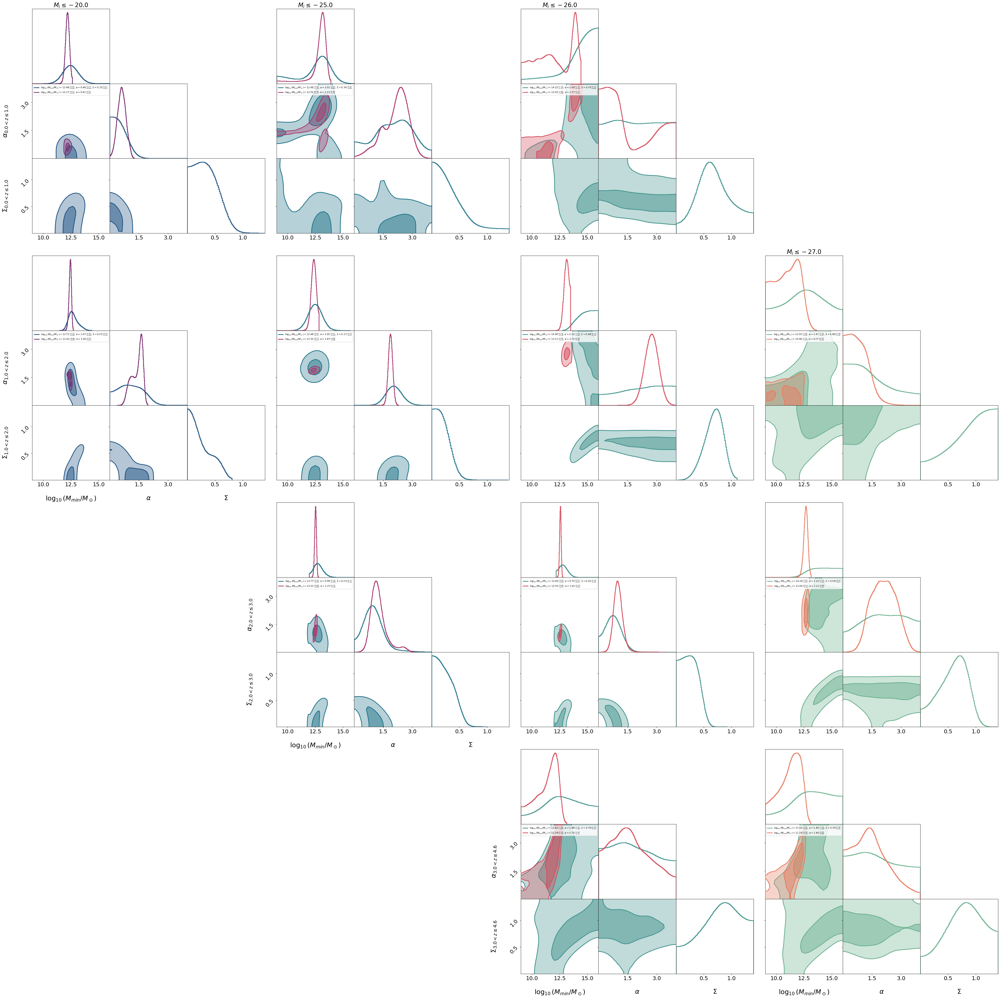

In [74]:
# plot!
fig = plt.figure(figsize=(60, 60))
gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)
for j in range(len(z_array)):

    for i in range(len(L_bins)):

        if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

            # carve an ndim x ndim sub-grid out of this outer cell
            sub_gs = gs[j*4+i].subgridspec(3, 3, wspace=0.0, hspace=0.0) #0.05
            ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(3)]
                                 for r in range(3)])

            custom_lines, legend_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):

                try:
                    if ndim == 2:
                        sigma='_Sigma0.0'
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 3
                    else:
                        sigma=''
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 1
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
    
                    samples, weights = results.samples, results.importance_weights()
    
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot.cornerplot(results, color=cmaps[::-1][k][i], hist2d_kwargs = {
                        'contourf_kwargs': contourf_kwargs, 'contour_kwargs': contour_kwargs, 'fill_contours': fill_contours, 
                        'plot_density': plot_density, 'no_fill_contours': no_fill_contours}, max_n_ticks=3, 
                                      quantiles=[], quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                      fig=(fig, ax[:ndim, :ndim]), smooth = smooth[::-1][k][j], hist_kwargs = {
                                          'density': True, 'histtype': 'step', 'linewidth': linewidth, 'alpha': 1})
    
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")
    
                    custom_lines.append(Line2D([0], [0], color=cmaps[::-1][k][i], linestyle='-', linewidth=linewidth))
                    if ndim == 2:
                        legend_labels.append('{}, {}'.format(legend[0], legend[1]))
                    else:
                        legend_labels.append('{}, {}, {}'.format(legend[0], legend[1], legend[2]))
                
                except Exception as e:
                    print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))

                ax1 = ax[1, 0]
                ax1.legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')
                
                # --- axis limits/labels on the main Mmin-alpha panel ---
                ax[1, 0].set_ylim(0, 4)
                ax[1, 1].set_xlim(0, 4)
                if ndim==3:
                    ax[-1, 0].set_ylim(0, 1.4)
                    ax[-1, 1].set_ylim(0, 1.4)
                    ax[-1, 1].set_xlim(0, 4)
                    ax[-1, -1].set_xlim(0, 1.4)
    
                if j == 0 or ((j == 1) and (i == 3)):
                    ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
                for k, axis in enumerate(ax[:, 0]):
                    axis.set_xlim(9, 16)
                    if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                        axis.set_yticklabels([])
                    elif k>0:
                        axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]))
                for k, axis in enumerate(ax[-1, :]):
                    axis.xaxis.set_label_coords(0.5, -0.2)
                    if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                        # ax1.set_xlabel('${}$'.format(ylabels[0]))
                        axis.set_xlabel('${}$'.format(ylabels[k]))
                    plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

fig.savefig('../figures/cornerplot.pdf'.format(ndim), bbox_inches='tight')
plt.show()

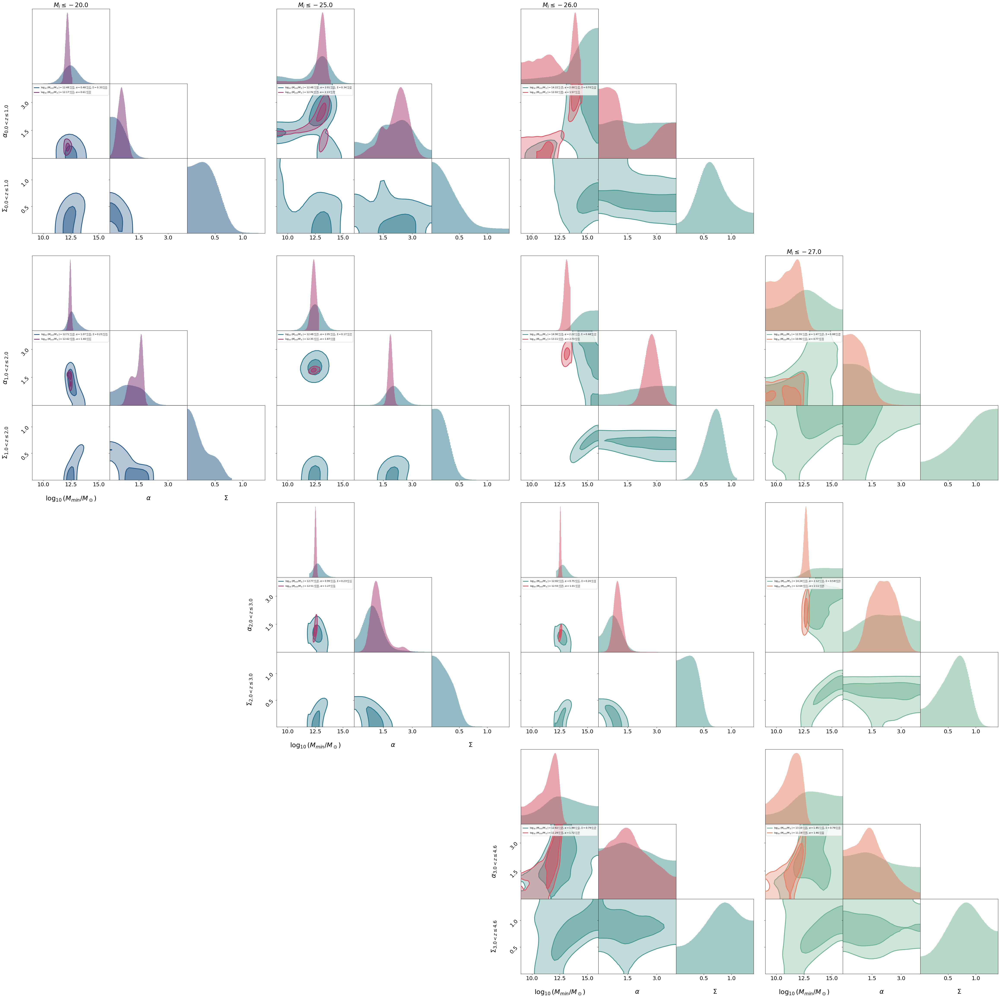

In [75]:
# plot!
fig = plt.figure(figsize=(60, 60))
gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)
for j in range(len(z_array)):

    for i in range(len(L_bins)):

        if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

            # carve an ndim x ndim sub-grid out of this outer cell
            sub_gs = gs[j*4+i].subgridspec(3, 3, wspace=0.0, hspace=0.0) #0.05
            ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(3)]
                                 for r in range(3)])

            custom_lines, legend_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):

                try:
                    if ndim == 2:
                        sigma='_Sigma0.0'
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 3
                    else:
                        sigma=''
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 1
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
    
                    samples, weights = results.samples, results.importance_weights()
    
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 
                                       'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot.cornerplot(results, color=cmaps[::-1][k][i], hist2d_kwargs = {
                        'contourf_kwargs': contourf_kwargs, 'contour_kwargs': contour_kwargs, 'fill_contours': fill_contours, 
                        'plot_density': plot_density, 'no_fill_contours': no_fill_contours}, max_n_ticks=3, 
                                      quantiles=[], quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                      fig=(fig, ax[:ndim, :ndim]), smooth = smooth[::-1][k][j], hist_kwargs = {
                                          'density': True, 'alpha': 0.5})
    
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")
    
                    custom_lines.append(Line2D([0], [0], color=cmaps[::-1][k][i], linestyle='-', linewidth=linewidth))
                    if ndim == 2:
                        legend_labels.append('{}, {}'.format(legend[0], legend[1]))
                    else:
                        legend_labels.append('{}, {}, {}'.format(legend[0], legend[1], legend[2]))
                
                except Exception as e:
                    print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))

                ax1 = ax[1, 0]
                ax1.legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')
                
                # --- axis limits/labels on the main Mmin-alpha panel ---
                ax[1, 0].set_ylim(0, 4)
                ax[1, 1].set_xlim(0, 4)
                if ndim==3:
                    ax[-1, 0].set_ylim(0, 1.4)
                    ax[-1, 1].set_ylim(0, 1.4)
                    ax[-1, 1].set_xlim(0, 4)
                    ax[-1, -1].set_xlim(0, 1.4)
    
                if j == 0 or ((j == 1) and (i == 3)):
                    ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
                for k, axis in enumerate(ax[:, 0]):
                    axis.set_xlim(9, 16)
                    if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                        axis.set_yticklabels([])
                    elif k>0:
                        axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]))
                for k, axis in enumerate(ax[-1, :]):
                    axis.xaxis.set_label_coords(0.5, -0.2)
                    if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                        # ax1.set_xlabel('${}$'.format(ylabels[0]))
                        axis.set_xlabel('${}$'.format(ylabels[k]))
                    plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(ndim), bbox_inches='tight')
plt.show()

## Fix $\Sigma=0.4$ dex

<>:63: SyntaxWarning: invalid escape sequence '\l'
<>:63: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/3716834652.py:63: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


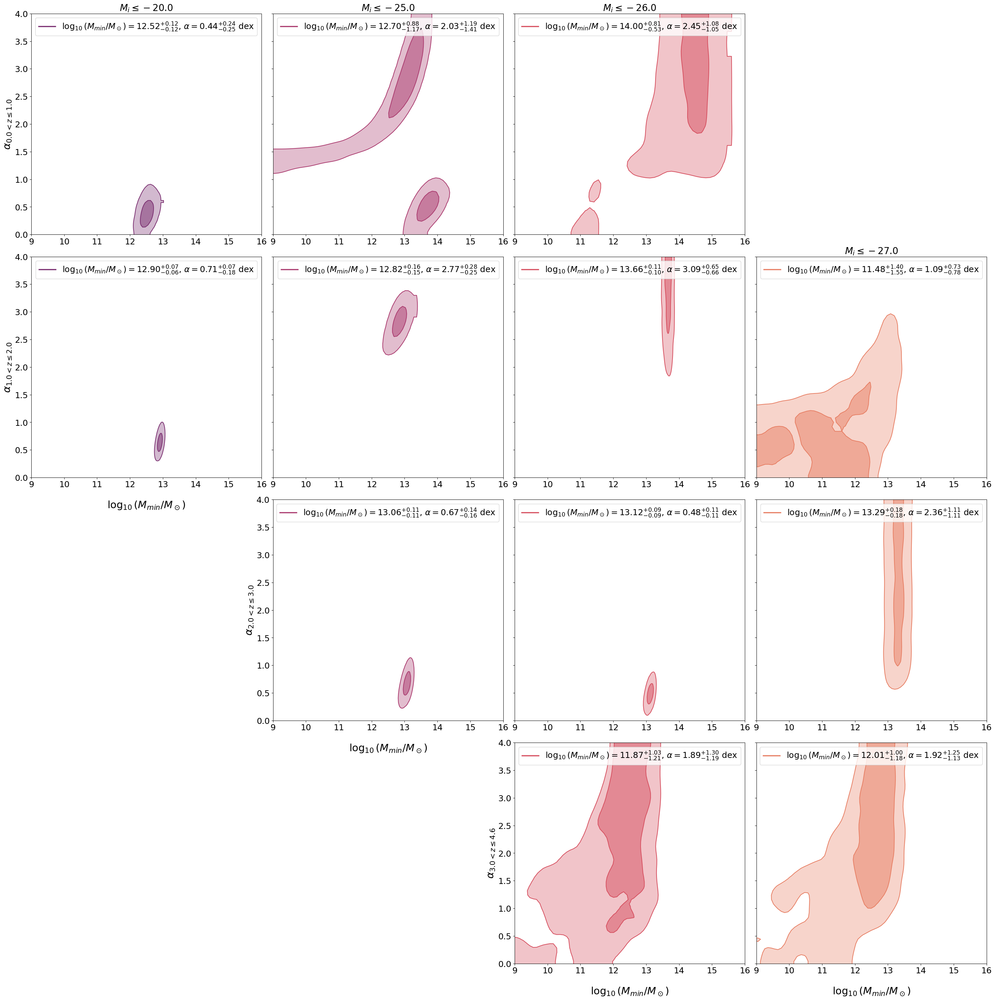

In [76]:
# remove bottom panel and just print bq somewhere
# plot!
ndim = 2    
fig = plt.figure(figsize = (37, 37))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            try:

                # if ndim == 2:
                #     sigma='_Sigma0.0'
                # else:
                #     sigma=''
                file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_Sigma0.4_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, 
                        nlive, sample) 
                
                # read the results
                with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                    results = pickle.load(fp)
                        
                samples, weights = results.samples, results.importance_weights() # try to figure out a way to do this without results_Mmin, I think I can? its from the stuff ive already saved
                equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rng)
                
                # --- corner plot -> buffer -> master cell ---
                contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile))}
                contour_kwargs = {'colors': [cmap_theta[i]]}
                dyplot._hist2d(equal_weight_samples[:, 0], equal_weight_samples[:, 1], color=cmap_theta[i], levels = quantile_2d,
                               contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs, smooth = 0.04) #, fill_contours = False)
                
                # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
                quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                             for k in range(samples.shape[1])]

                # Compute weighted mean and covariance.
                mean, cov = dyfunc.mean_and_cov(samples, weights)
                
                legend=[]
                for k, (lo, mid, hi) in enumerate(quantiles):

                    mid = mean[k]
                    
                    legend.append(f"${ylabels[k]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
                ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
                ax1.xaxis.set_label_coords(0.5, -0.1)
            
            except Exception as e:
                print(e)
                            
            ax1.set_xlim(9, 16)
            ax1.set_ylim(0,4)
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[1],
                    z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel('${}$'.format(ylabels[0]))
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

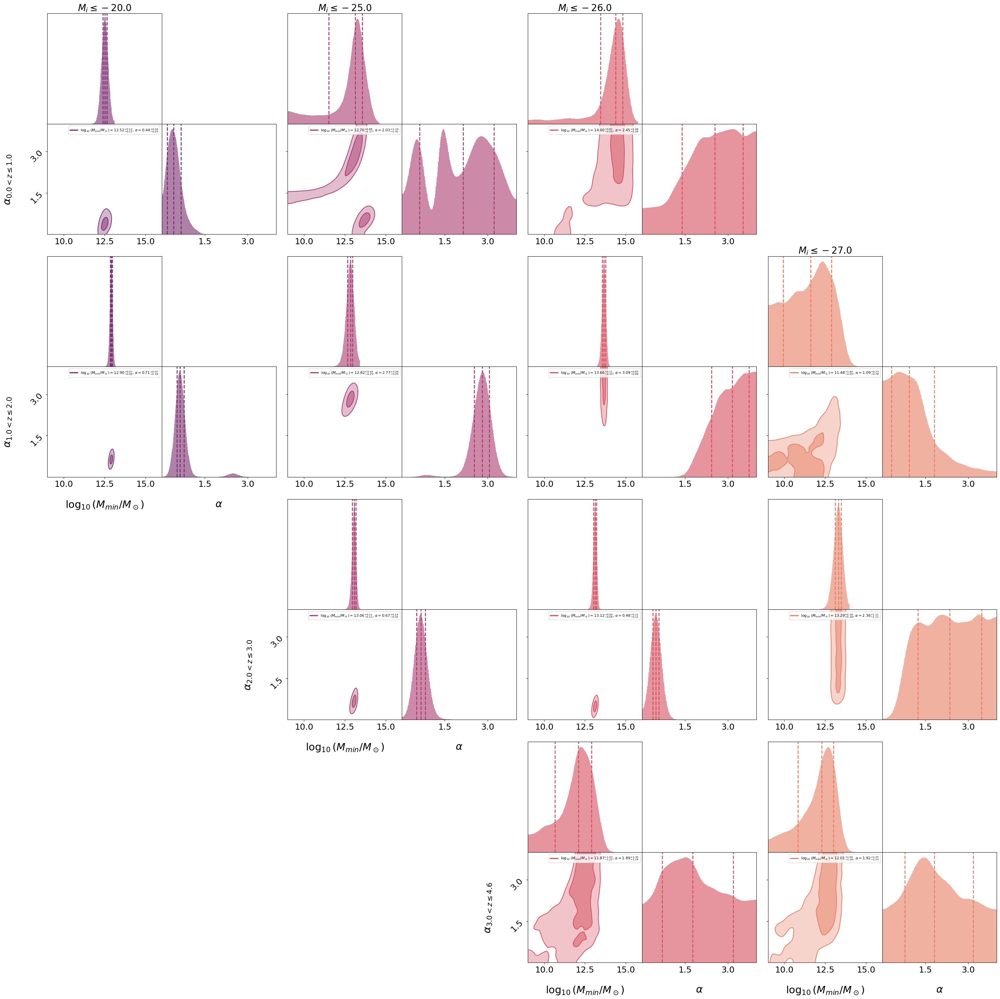

In [77]:
# plot!
ndim = 2
# for ndim in ndim_array:

fig = plt.figure(figsize=(57/3*ndim, 57/3*ndim))
gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)

for j in range(len(z_array)):

    for i in range(len(L_bins)):

        if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

            # carve an ndim x ndim sub-grid out of this outer cell
            sub_gs = gs[j*4+i].subgridspec(ndim, ndim, wspace=0.0, hspace=0.0)
            ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(ndim)]
                                 for r in range(ndim)])

            try:
                # if ndim == 2:
                #     sigma='_Sigma0.0'
                # else:
                #     sigma=''
                file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_Sigma0.4_dlogz{}_nlive{}_{}'.format(
                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, 
                    nlive, sample) 
                
                # read the results
                with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                    results = pickle.load(fp)

                samples, weights = results.samples, results.importance_weights()

                contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile))}
                contour_kwargs = {'colors': [cmap_theta[i]]}
                dyplot.cornerplot(results, color=cmap_theta[i], hist2d_kwargs = {'contourf_kwargs': 
                                                                                 contourf_kwargs, 'contour_kwargs': contour_kwargs}, 
                       max_n_ticks=3, quantiles=quantile, quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                  fig=(fig, ax), smooth = 0.04)

                quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                             for k in range(samples.shape[1])]

                # Compute weighted mean and covariance.
                mean, cov = dyfunc.mean_and_cov(samples, weights)
                
                legend=[]
                for l, (lo, mid, hi) in enumerate(quantiles):

                    mid = mean[l]
                    
                    legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

                custom_lines = [Line2D([0], [0], color=cmap_theta[i], linestyle='-', linewidth=2.5)]
                if ndim == 2:
                    legend_labels = ['{}, {}'.format(legend[0], legend[1])]
                else:
                    legend_labels = ['{}, {}, {}'.format(legend[0], legend[1], legend[2])]

                # ax1 = ax[1, 0]
                ax[1, 0].legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')

            except Exception as e:
                print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))

            # --- axis limits/labels on the main Mmin-alpha panel ---
            # ax1 = ax[1, 0]
            # ax1.set_xlim(9, 16)
            ax[1, 0].set_ylim(0, 4)
            ax[1, -1].set_xlim(0, 4)

            if j == 0 or ((j == 1) and (i == 3)):
                ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
            for k, axis in enumerate(ax[:, 0]):
                axis.set_xlim(9, 16)
                if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                    axis.set_yticklabels([])
                elif k>0:
                    axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]))
            for k, axis in enumerate(ax[-1, :]):
                axis.xaxis.set_label_coords(0.5, -0.2)
                if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                    axis.set_xlabel('${}$'.format(ylabels[k]))
                plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(ndim), bbox_inches='tight')
plt.show()

# Plot results

In [51]:
labels=[r'$\log(f_\mathrm{duty})$', r'$\log_{10} (M_\mathrm{min}/M_\odot)$', r'$\alpha$', r'$\Sigma$']

In [52]:
Sigma = [0, None]

In [80]:
quantiles = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
equal_weight_samples = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        for l, ndim in enumerate(ndim_array):

            if np.round(N_q[L_bins[i]][j]/1000)>1:

            # a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
            #                 G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            # zbin = 1/a-1
            # xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]

            # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = 0, log_thetamin = log_thetamin, nbins_mask = nbins_mask, a = a)

                quantiles_bin, equal_weight_samples_bin = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                quantiles[ndim][L_bins[i]].append(quantiles_bin)
                equal_weight_samples[ndim][L_bins[i]].append(equal_weight_samples_bin)
                # quantiles[ndim][L_bins[i]].append(f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, 
                #                                      nbins_mask = nbins_mask))
                
            else:
                
                quantiles[ndim][L_bins[i]].append([[np.nan]*3])
                equal_weight_samples[ndim][L_bins[i]].append([np.nan]*(ndim+1))

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


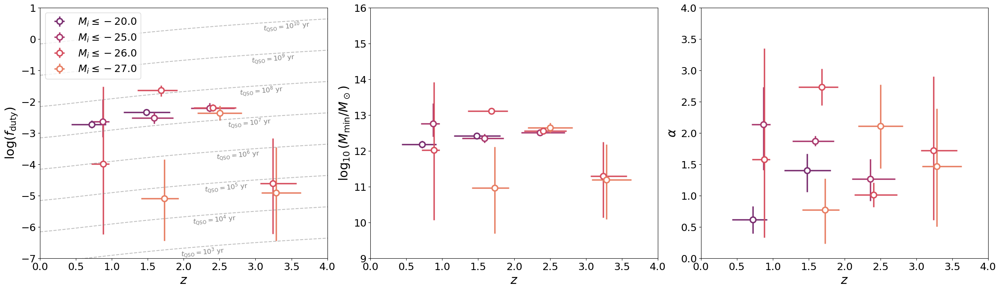

In [81]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.15, hspace = 0.15)
# quantiles = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
# ax4 = fig.add_subplot(gs[3])
ndim = 2
ax = [ax1, ax2, ax3] #, ax4]

for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                            G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            zbin = 1/a-1
            xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]
            
            for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                
                ax[l].errorbar(zbin, mid, yerr = [[mid-lo], [hi-mid]], 
                     xerr = xerr, linestyle = 'none', marker = 'o', label = r'$M_i\leq{}$'.format(L_bins[i]),
                     color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#,
                ax[l].set_ylabel(labels[l])
                ax[l].set_xlabel('$z$')
                ax[l].set_xlim(0, 4)

# ax3.set_xlabel('$z$')
# ax4.set_xlabel('$z$')

h, l = ax1.get_legend_handles_labels()
label, ind = np.unique(l, return_index = True)
ax1.legend([h[i] for i in ind], label)

d = 1
start = 12
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    # if (t>1e2) and (t<1e11):
    ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,16)
ax3.set_ylim(0, 4)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

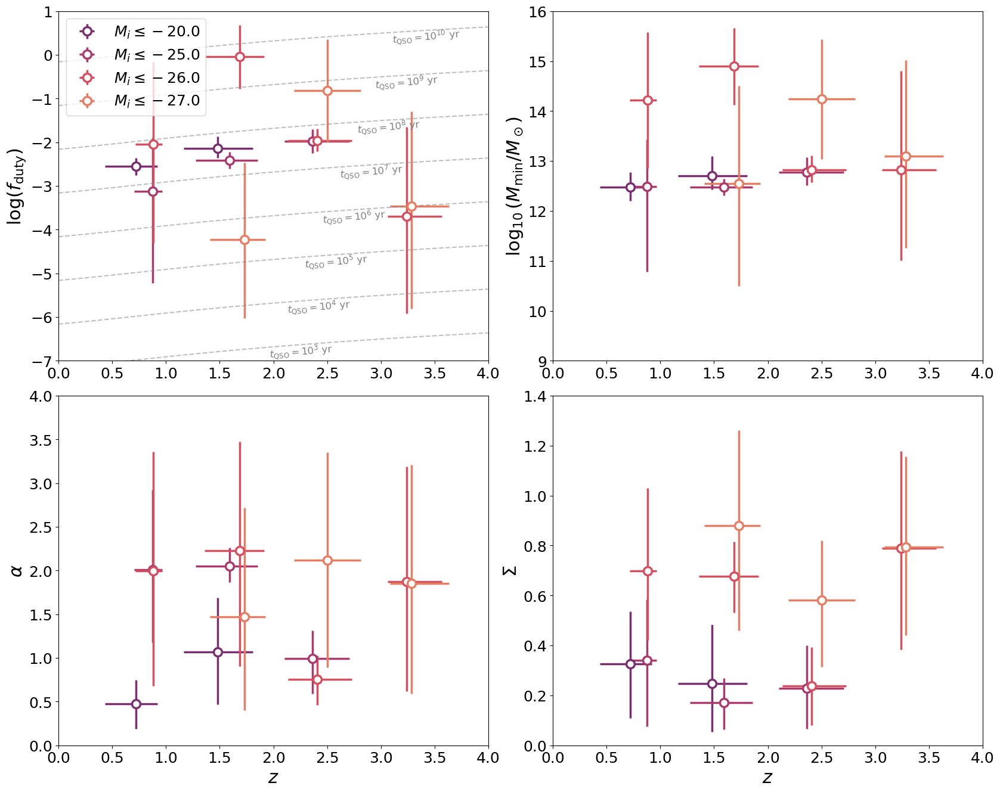

In [82]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ndim = 3
# a_zbin = {L: [] for L in L_bins}
# err_L_z = {i: {L: [] for L in L_bins} for i in err_labels}
# z_sigma = {L: [] for L in L_bins}
# M_min, Sigma = {L: [] for L in L_bins}, {L: [] for L in L_bins}
# mid_array = [M_min, Sigma]
ax = [ax1, ax2, ax3, ax4]
for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                            G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            zbin = 1/a-1
            xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]

            # quantiles = f_duty(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, a = a)
            # quantiles[ndim][L_bins[i]].append(f_duty(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask,
            #                                          a = a))
            
            # file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_Sigma0.0_dlogz{}_nlive{}_{}'.format(
            #             G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, 
            #             nlive, sample) 
    
            # # read the results
            # with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
            #     results = pickle.load(fp)
    
            # samples, weights = results.samples, results.importance_weights()
    
            # quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
            #              for k in range(samples.shape[1])]
            
            for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                ax[l].errorbar(zbin, mid, yerr = [[mid-lo], [hi-mid]], 
                     xerr = xerr, linestyle = 'none', marker = 'o', label = r'$M_i\leq{}$'.format(L_bins[i]),
                     color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#,
                ax[l].set_ylabel(labels[l])
                # ax[l].set_xlabel('$z$')
                ax[l].set_xlim(0, 4)
        
    # M_min_lo, M_min_hi = err_L_z['log10(M_min)'][L_bins[i]][:,0], err_L_z['log10(M_min)'][L_bins[i]][:,1]
    
    # zbin = 1/np.array(a)-1
    # xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

    # ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
    #              xerr = xerr, linestyle = 'none', marker = 'o', label = r'$M_i\leq{}$'.format(L_bins[i]),
    #              color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#, 
    
    # f_duty_lo, f_duty_hi = err_L_z['log10(f_duty)'][L_bins[i]][:,0], err_L_z['log10(f_duty)'][L_bins[i]][:,1]
    # ax2.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
    #              marker = 'o', color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

    # Sigma_lo, Sigma_hi = np.array(err_L_z['Sigma'][L_bins[i]])[:,0], np.array(err_L_z['Sigma'][L_bins[i]])[:,1]
    # ax3.errorbar(zbin, Sigma[L_bins[i]], yerr = [Sigma[L_bins[i]]-Sigma_lo, Sigma_hi-Sigma[L_bins[i]]], linestyle = 'none', xerr = xerr, 
    #              marker = 'o', color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

# ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
# ax1.set_xlabel('$z$')

# ax2.set_ylabel('$\log_{10}(f_{duty})$')
# ax2.set_xlabel('$z$')

# ax3.set_ylabel(labels[-1])
ax3.set_xlabel('$z$')
ax4.set_xlabel('$z$')

h, l = ax1.get_legend_handles_labels()
label, ind = np.unique(l, return_index = True)
ax1.legend([h[i] for i in ind], label)
# ax1.legend()

d = 1
start = 12
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    # if (t>1e2) and (t<1e10):
    ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

# ax1.set_xlim(0, 4)
# ax2.set_xlim(0, 4)
# ax3.set_xlim(0, 4)
ax1.set_ylim(-7,1)
ax2.set_ylim(9,16)
ax3.set_ylim(0, 4)
ax4.set_ylim(0, 1.4)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

In [64]:
linewidth = [2.5, 2.5] #1.5]

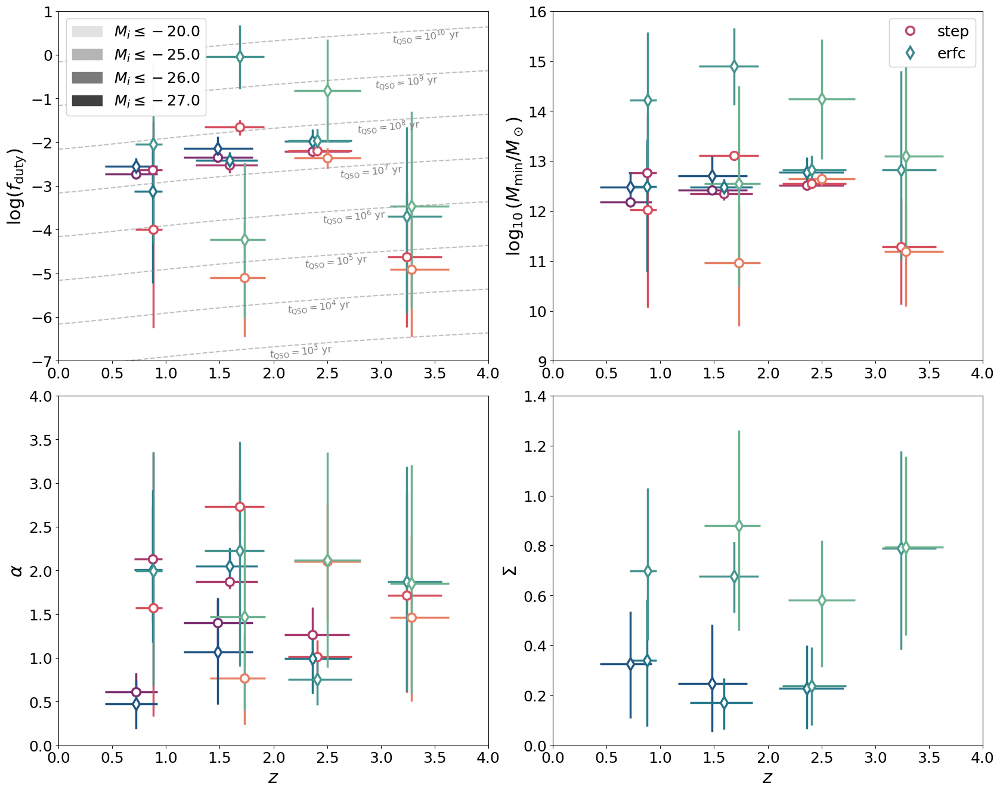

In [84]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ax = [ax1, ax2, ax3, ax4]

for k, ndim in enumerate(ndim_array):
    
    for i in range(len(L_bins)):    
    
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                                G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
                zbin = 1/a-1
                xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]
    
                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[k], log_thetamin = log_thetamin, nbins_mask = nbins_mask, 
                #                    a = a)
                
                for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                    ax[l].errorbar(zbin, mid, yerr = [[mid-lo], [hi-mid]], xerr = xerr, linestyle = 'none', marker = marker[k], 
                                   label = r'$M_i\leq{}$'.format(L_bins[i]), color = cmaps[k][i], linewidth = linewidth[k], 
                                   markeredgewidth = linewidth[k], markerfacecolor = 'white', markersize = 10)#,
                    ax[l].set_ylabel(labels[l])
                    ax[l].set_xlim(0, 4)
        
ax3.set_xlabel('$z$')
ax4.set_xlabel('$z$')

# h, l = ax1.get_legend_handles_labels()
# label, ind = np.unique(l, return_index = True)
# ax1.legend([h[i] for i in ind], label)

custom_lines = [mpatches.Patch(color=sns.color_palette("Greys", n_colors = len(L_bins))[i]) for i in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])#, title = 'Shiferaw et al. 2026 (this work)',
fig.add_artist(first_legend)

custom_lines = [Line2D([0], [0], color = np.mean(cmaps[l], axis = 0), linestyle = 'None', marker = marker[l],
                       markeredgewidth = linewidth[l], markersize = 10, linewidth = linewidth[l], markerfacecolor = 'white') 
                for l in range(len(ndim_array))]
second_legend = ax2.legend(custom_lines, ['step', 'erfc'])
fig.add_artist(second_legend)

d = 1
start = 12
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    # if (t>1e2) and (t<1e10):
    ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,16)
ax3.set_ylim(0, 4)
ax4.set_ylim(0, 1.4)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

## Compare to literature

In [53]:
z_centers_eft    = [2.50, 2.29, 2.51, 3.02, 2.50, 2.50, 2.50][:4]
z_err_lo_eft     = [0.30, 0.09, 0.13, 0.38, 0.30, 0.30, 0.30][:4]
z_err_hi_eft     = [0.30, 0.09, 0.13, 0.38, 0.30, 0.30, 0.30][:4]

fduty_eft        = np.log10([0.00734, 0.0162, 0.0061, 0.00145, 0.0019, 0.0023, 0.0044])[:4]
fduty_err_hi_eft = np.log10(10**fduty_eft+[0.0014,  0.0031, 0.0016, 0.0003,  0.0004, 0.0006, 0.0015][:4])-fduty_eft
fduty_err_lo_eft = fduty_eft-np.log10(10**fduty_eft-[0.0011,  0.0025, 0.0014, 0.0002,  0.0003, 0.0004, 0.0008][:4]) #table 7 https://arxiv.org/pdf/1507.08380

In [54]:
Mmin_eft        = np.log10(np.array([0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26])*1e12/Planck18.h)[:4]
Mmin_err_hi_eft = np.log10(np.add([0.11, 0.16, 0.15, 0.04, 0.12, 0.12, 0.26],[0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26])[:4]*1e12/Planck18.h)-Mmin_eft
Mmin_err_lo_eft = Mmin_eft-np.log10(np.subtract([0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26], [0.09, 0.15, 0.14, 0.07, 0.10, 0.16, 0.15])[:4]*1e12/Planck18.h) #table 7 https://arxiv.org/pdf/1507.08380

In [55]:
z_centers_2    = [1.05, 1.35, 1.65, 2.00, 1.55][:-1]
z_err_lo_2     = [0.15, 0.15, 0.15, 0.20, 0.65][:-1]
z_err_hi_2     = [0.15, 0.15, 0.15, 0.20, 0.65][:-1]

fduty_2        = np.log10([0.0091, 0.0183, 0.0355, 0.0422, 0.0292])[:-1]
fduty_err_hi_2 = np.log10(10**fduty_2+[0.0027, 0.0028, 0.0133, 0.0077, 0.0048][:-1])-fduty_2
fduty_err_lo_2 = fduty_2-np.log10(10**fduty_2-[0.0027, 0.0028, 0.0133, 0.0077, 0.0048][:-1])

Mmin_2         = np.log10(np.array([1.99, 2.24, 2.51, 1.99, 2.51])*1e12/Planck18.h)[:-1]
Mmin_err_hi_2  = np.log10(np.add([0.52, 0.27, 0.65, 0.24, 0.31], [1.99, 2.24, 2.51, 1.99, 2.51])[:-1]*1e12/Planck18.h)-Mmin_2
Mmin_err_lo_2  = Mmin_2-np.log10(np.subtract([1.99, 2.24, 2.51, 1.99, 2.51],[0.41, 0.24, 0.27, 0.41, 0.27])[:-1]*1e12/Planck18.h) # table 4 https://arxiv.org/pdf/1705.04718

In [56]:
z_shen = [3.2, 4.6]
z_err_shen = [0.3, 0.8]

fduty_shen = (np.log10(0.05)+np.log10(0.004))/2, (np.log10(0.6)+np.log10(0.03))/2
fduty_err_lo_shen = fduty_shen - np.log10([0.004, 0.03])
fduty_err_hi_shen = np.log10([0.05, 0.6]) - fduty_shen

Mmin_shen = np.log10([(2.26e12+3.11e12)/2, (3.83e12+5.76e12)/2]/Planck18.h) # https://arxiv.org/abs/astro-ph/0702214 table 6
Mmin_err_lo_shen = Mmin_shen-np.log10([2.26e12, 3.83e12]/Planck18.h)
Mmin_err_hi_shen = np.log10([3.11e12, 5.76e12]/Planck18.h)-Mmin_shen

In [57]:
z_charles = [2.143, 2.479, 3.264]
z_err_charles = np.array([[2,2.3], [2.3,2.7], [3.1,3.5]])
z_err_lo_charles = z_charles - z_err_charles[:,0]
z_err_hi_charles = z_err_charles[:,1] - z_charles

fduty_charles = np.log10([0.0243, 0.0207, 0.0142])
fduty_err_charles = np.array([0.0008, 0.0008, 0.0016])
fduty_err_lo_charles = fduty_charles-np.log10(10**fduty_charles-fduty_err_charles)
fduty_err_hi_charles = np.log10(10**fduty_charles+fduty_err_charles)-fduty_charles

In [58]:
z_pizzati = 2.5, 4
z_err_pizzati = 0.3, 0.5

fduty_pizzati = np.log10(np.array([1.01, 51])/100)
fduty_err_pizzati = np.array([[0.04, 31], [1.59, 32]])/100
fduty_err_lo_pizzati = fduty_pizzati-np.log10(10**fduty_pizzati-fduty_err_pizzati[0]/100)
fduty_err_hi_pizzati = np.log10(10**fduty_pizzati+fduty_err_pizzati[1]/100)-fduty_pizzati

In [59]:
z_cordova = 0.9
z_err_cordova = [0.2], [0.1]

Mmin_cordova = 13.21
Mmin_err_cordova = [0.06], [0.04]

alpha_cordova = 1.2 # https://arxiv.org/abs/2409.08314
alpha_err_cordova = 0.2

In [60]:
z_mitra = 1.04
z_err_mitra = 0.58

Mmin_mitra = 15.75
Mmin_err_mitra = [0.94], [0.75]

alpha_mitra = 2.59 #https://arxiv.org/pdf/1802.04758
alpha_err_mitra = [1.27], [1.41]

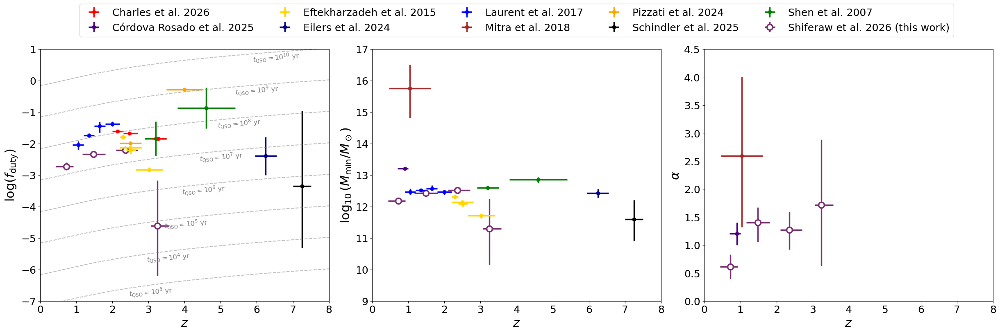

In [93]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.15, hspace = 0.15)

i = 0
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax = [ax1, ax2, ax3]
ndim = 2

# M_min_lo, M_min_hi = np.array(err['log10(M_min)'][L_bins[i]])[:,0], np.array(err['log10(M_min)'][L_bins[i]])[:,1]
# zbin = 1/np.array(a_zbin[L_bins[i]])-1
# xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

# ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
#              xerr = xerr, linestyle = 'none', marker = 'o', 
#              color = cmap_theta[i], linewidth = 2.5, 
#              label = 'Shiferaw et al. 2026 (this work)', zorder = 0, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
    
# ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
# ax1.set_xlabel('$z$')
# ax1.set_ylim(9, 16)
# ax1.set_xlim(0, 8)

ax3.errorbar(z_cordova, alpha_cordova, yerr = alpha_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax3.errorbar(z_mitra, alpha_mitra, yerr = alpha_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')

ax2.errorbar(z_shen, Mmin_shen, yerr = [Mmin_err_lo_shen, Mmin_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007') #https://arxiv.org/abs/2403.07986 p13
ax2.errorbar(z_centers_eft, Mmin_eft, yerr = [Mmin_err_lo_eft, Mmin_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax2.errorbar(z_centers_2, Mmin_2, yerr = [Mmin_err_lo_2, Mmin_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax2.errorbar(6.25, 12.43, yerr = [[0.15], [0.13]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024')
ax2.errorbar(7.25, 11.6, yerr = [[0.7], [0.6]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 abstract
ax2.errorbar(z_cordova, Mmin_cordova, yerr = Mmin_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax2.errorbar(z_mitra, Mmin_mitra, yerr = Mmin_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')

# f_duty_lo, f_duty_hi = np.array(err['log10(f_duty)'][L_bins[i]])[:,0], np.array(err['log10(f_duty)'][L_bins[i]])[:,1]
# ax1.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
#              marker = 'o', color = cmap_theta[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
   
# ax1.set_ylabel('$\log_{10}(f_{duty})$')
# ax1.set_xlabel('$z$')
# ax1.set_ylim(-7,0)

ax1.errorbar(z_shen, fduty_shen, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')
ax1.errorbar(z_centers_eft, fduty_eft, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, fduty_2, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, np.log10(0.4/100), yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_pizzati, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3
ax1.errorbar(7.25, -3.36, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4
ax1.errorbar(z_charles, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2

d = 3
start = 15
z_linspace = np.linspace(0,8)
for k, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    # if (t>1e2) and (t<1e10):
    ax1.text(z_linspace[start:][::d][k], np.log10(fduty_linspace)[start:][::d][k]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

# h, l = ax1.get_legend_handles_labels()
# label, ind = np.unique(l, return_index = True)

k = 0
legend_handles, legend_labels = [], []
for j in range(len(z_array)):
    
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                                    G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
    zbin = 1/a-1
    xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]
    
    # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[k], log_thetamin = log_thetamin, nbins_mask = nbins_mask, a = a)
    
    for m, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
        ax[m].errorbar(zbin, mid, yerr = [[mid-lo], [hi-mid]], 
             xerr = xerr, linestyle = 'none', marker = 'o', 
             color = cmap_theta[i], linewidth = 2.5, 
             label = 'Shiferaw et al. 2026 (this work)', zorder = 0, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
        ax[m].set_ylabel(labels[m])
        ax[m].set_xlabel('$z$')
        ax[m].set_xlim(0, 8)

        h, l = ax[m].get_legend_handles_labels()
        legend_handles.extend(h)
        legend_labels.extend(l)

label, ind = np.unique(legend_labels, return_index = True)
ax1.legend([legend_handles[i] for i in ind], label, ncol=5, loc='upper center', bbox_to_anchor=(1.65, 1.2))
# ax1.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.2))
# ax1.set_xlim(0, 8)

# ax1 = fig.add_subplot(gs[2])
# i = 0
# Sigma_lo, Sigma_hi = np.array(err['Sigma'][L_bins[i]])[:,0], np.array(err['Sigma'][L_bins[i]])[:,1]
# ax2.errorbar(zbin, Sigma[L_bins[i]], yerr = [Sigma[L_bins[i]]-Sigma_lo, Sigma_hi-Sigma[L_bins[i]]], linestyle = 'none', xerr = xerr, 
#              marker = 'o', color = cmap_theta[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
# ax2.errorbar(z_pizzati, Sigma_pizzati, yerr = Sigma_err_pizzati, linestyle = 'none', xerr = z_err_pizzati, 
#              marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2606.27115 table 2
# ax1.set_ylabel(labels[-1])
# ax1.set_xlabel('$z$')
# ax1.set_xlim(0, 8)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,17)
ax3.set_ylim(0, 4.5)
# ax4.set_ylim(0, 1.4)

plt.show()

In [61]:
sigma_pizzati = np.array([0.52, 0.20])
sigma_err_pizzati = [0.22, 0.07], [0.18, 0.06]

gamma_pizzati = np.array([1.15, 2])
gamma_err_pizzati = [0.07, 0.23], [0.06, 0.22]

Sigma_pizzati = sigma_pizzati/gamma_pizzati
Sigma_err_pizzati = Sigma_pizzati*np.sqrt((sigma_err_pizzati/sigma_pizzati)**2+(gamma_err_pizzati/gamma_pizzati)**2)

In [62]:
Sigma_mitra = 1.49/(np.sqrt(2)*np.log(10)) #https://arxiv.org/pdf/1802.04758
Sigma_err_mitra = [[0.38], [0.33]]/(np.sqrt(2)*np.log(10))

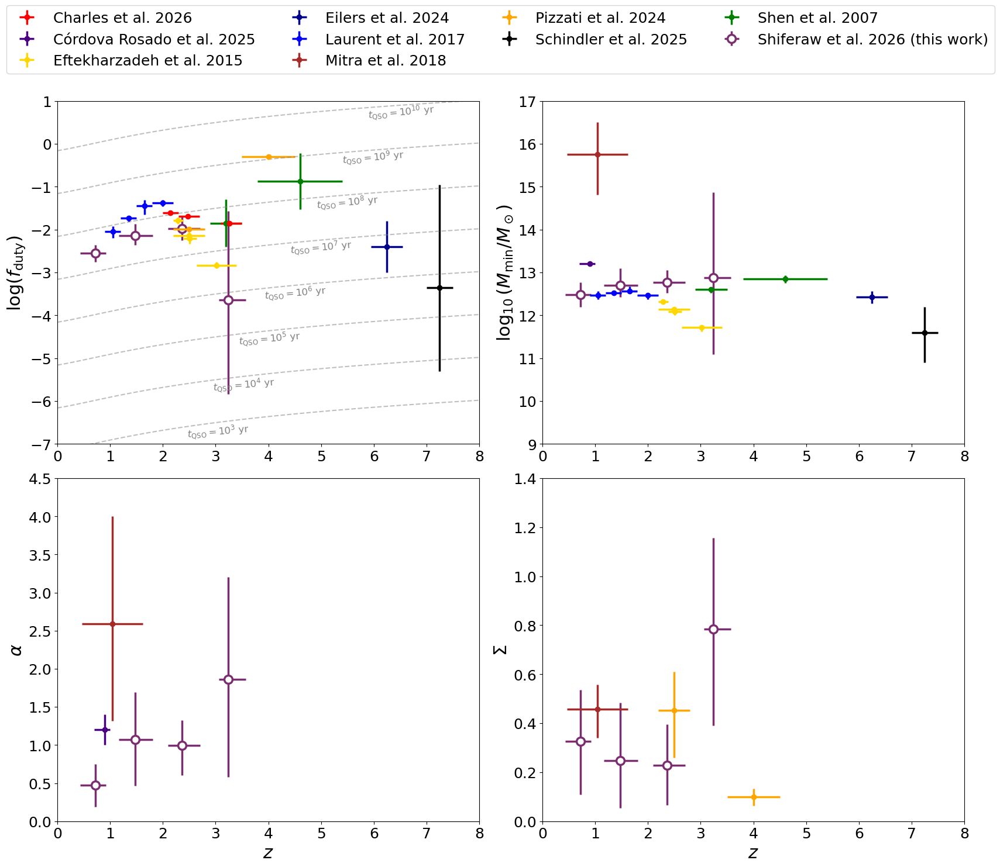

In [96]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

i = 0
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ax = [ax1, ax2, ax3, ax4]
ndim = 3

ax2.errorbar(z_shen, Mmin_shen, yerr = [Mmin_err_lo_shen, Mmin_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007') #https://arxiv.org/abs/2403.07986 p13
ax2.errorbar(z_centers_eft, Mmin_eft, yerr = [Mmin_err_lo_eft, Mmin_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax2.errorbar(z_centers_2, Mmin_2, yerr = [Mmin_err_lo_2, Mmin_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax2.errorbar(6.25, 12.43, yerr = [[0.15], [0.13]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024')
ax2.errorbar(7.25, 11.6, yerr = [[0.7], [0.6]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 abstract
ax2.errorbar(z_cordova, Mmin_cordova, yerr = Mmin_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax2.errorbar(z_mitra, Mmin_mitra, yerr = Mmin_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')

ax1.errorbar(z_shen, fduty_shen, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')
ax1.errorbar(z_centers_eft, fduty_eft, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, fduty_2, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, np.log10(0.4/100), yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_pizzati, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3
ax1.errorbar(7.25, -3.36, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4
ax1.errorbar(z_charles, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2

ax3.errorbar(z_cordova, alpha_cordova, yerr = alpha_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax3.errorbar(z_mitra, alpha_mitra, yerr = alpha_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')
ax3.set_xlabel('$z$')

ax4.errorbar(z_pizzati, Sigma_pizzati, yerr = Sigma_err_pizzati, linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2606.27115 table 2
ax4.errorbar(z_mitra, Sigma_mitra, yerr = Sigma_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')
ax4.set_xlabel('$z$')

d = 3
start = 15
z_linspace = np.linspace(0,8)
for k, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    ax1.text(z_linspace[start:][::d][k], np.log10(fduty_linspace)[start:][::d][k]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

k = 1
legend_handles, legend_labels = [], []
for j in range(len(z_array)):
    
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                                    G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
    zbin = 1/a-1
    xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]
    
    # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[k], log_thetamin = log_thetamin, nbins_mask = nbins_mask, a = a)
    
    for m, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
        ax[m].errorbar(zbin, mid, yerr = [[mid-lo], [hi-mid]], 
             xerr = xerr, linestyle = 'none', marker = 'o', 
             color = cmap_theta[i], linewidth = 2.5, 
             label = 'Shiferaw et al. 2026 (this work)', zorder = 0, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
        ax[m].set_ylabel(labels[m])
        ax[m].set_xlim(0, 8)
        
        h, l = ax[m].get_legend_handles_labels()
        legend_handles.extend(h)
        legend_labels.extend(l)

label, ind = np.unique(legend_labels, return_index = True)
ax1.legend([legend_handles[i] for i in ind], label, ncol=4, loc='upper center', bbox_to_anchor=(1.05, 1.3))

ax1.set_ylim(-7,1)
ax2.set_ylim(9,17)
ax3.set_ylim(0, 4.5)
ax4.set_ylim(0, 1.4)

plt.show()

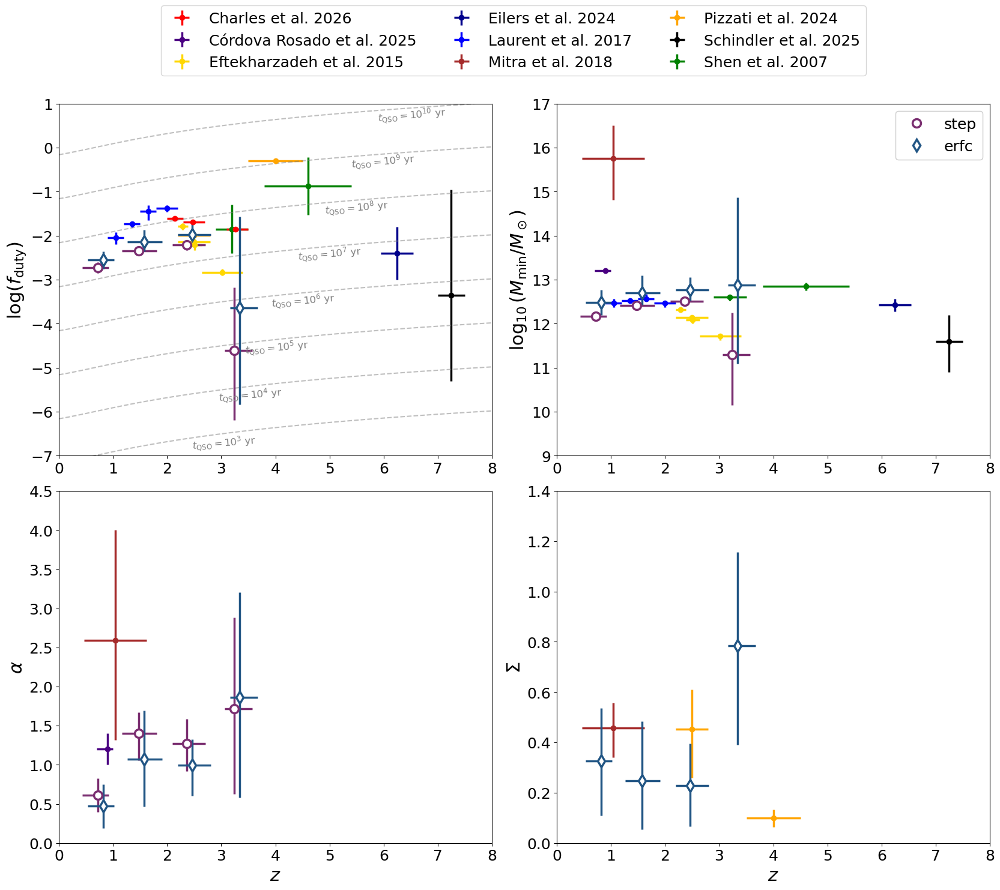

In [97]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

i = 0
# k = 1
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ax = [ax1, ax2, ax3, ax4]
# ndim = 3
    
ax2.errorbar(z_shen, Mmin_shen, yerr = [Mmin_err_lo_shen, Mmin_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007') #https://arxiv.org/abs/2403.07986 p13
ax2.errorbar(z_centers_eft, Mmin_eft, yerr = [Mmin_err_lo_eft, Mmin_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax2.errorbar(z_centers_2, Mmin_2, yerr = [Mmin_err_lo_2, Mmin_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax2.errorbar(6.25, 12.43, yerr = [[0.15], [0.13]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024')
ax2.errorbar(7.25, 11.6, yerr = [[0.7], [0.6]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 abstract
ax2.errorbar(z_cordova, Mmin_cordova, yerr = Mmin_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax2.errorbar(z_mitra, Mmin_mitra, yerr = Mmin_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')

ax1.errorbar(z_shen, fduty_shen, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')
ax1.errorbar(z_centers_eft, fduty_eft, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, fduty_2, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, np.log10(0.4/100), yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_pizzati, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3
ax1.errorbar(7.25, -3.36, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4
ax1.errorbar(z_charles, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2

ax3.errorbar(z_cordova, alpha_cordova, yerr = alpha_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax3.errorbar(z_mitra, alpha_mitra, yerr = alpha_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')
ax3.set_xlabel('$z$')

ax4.errorbar(z_pizzati, Sigma_pizzati, yerr = Sigma_err_pizzati, linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2606.27115 table 2
ax4.errorbar(z_mitra, Sigma_mitra, yerr = Sigma_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')
ax4.set_xlabel('$z$')

d = 3
start = 15
z_linspace = np.linspace(0,8)
for k, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    ax1.text(z_linspace[start:][::d][k], np.log10(fduty_linspace)[start:][::d][k]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

legend_handles, legend_labels = [], []
for j in range(len(z_array)):
    
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                                    G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
    zbin = 1/a-1
    xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]

    for k, ndim in enumerate(ndim_array):
        
        # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[k], log_thetamin = log_thetamin, nbins_mask = nbins_mask, a = a)
        
        for m, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
            ax[m].errorbar(zbin+k*0.1, mid, yerr = [[mid-lo], [hi-mid]], xerr = xerr, linestyle = 'none', marker = marker[k], 
                           color = cmaps[k][i], linewidth = linewidth[k], #label = 'Shiferaw et al. 2026 (this work)', zorder = 0, 
                           markeredgewidth = linewidth[k], markerfacecolor = 'white', markersize = 10)
            ax[m].set_ylabel(labels[m])
            # ax[l].set_xlabel('$z$')
            ax[m].set_xlim(0, 8)
            
            h, l = ax[m].get_legend_handles_labels()
            legend_handles.extend(h)
            legend_labels.extend(l)
            
# h, l = ax1.get_legend_handles_labels()
label, ind = np.unique(legend_labels, return_index = True)
ax1.legend([legend_handles[i] for i in ind], label, ncol=3, loc='upper center', bbox_to_anchor=(1.05, 1.3))

custom_lines = [Line2D([0], [0], color = cmaps[l][i], linestyle = 'None', marker = marker[l],
                       markeredgewidth = linewidth[l], markersize = 10, linewidth = linewidth[l], markerfacecolor = 'white') 
                for l in range(len(ndim_array))]
second_legend = ax2.legend(custom_lines, ['step', 'erfc'])#, title = 'Shiferaw et al. 2026 (this work)', title_fontsize = 18)
fig.add_artist(second_legend)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,17)
ax3.set_ylim(0, 4.5)
ax4.set_ylim(0, 1.4)

plt.show()

## Plot as a function of luminosity

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_6061/4032794147.py:24: SyntaxWarning: invalid escape sequence '\l'
  label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]),
/tmp/ipykernel_6061/4032794147.py:27: SyntaxWarning: invalid escape sequence '\m'
  ax[l].set_xlabel('$M_{i, \mathrm{max}}$')


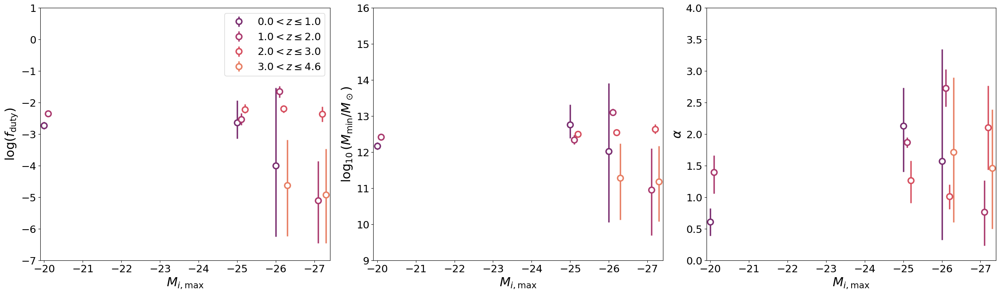

In [98]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.15, hspace = 0.15)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ndim = 2
ax = [ax1, ax2, ax3] #, ax4]
for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            # a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
            #                 G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            # zbin = 1/a-1
            # xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]

            # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = 0, log_thetamin = log_thetamin, nbins_mask = nbins_mask)
            
            for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                ax[l].errorbar(L_bins[i]-j*0.1, mid, yerr = [[mid-lo], [hi-mid]], linestyle = 'none', marker = 'o', 
                              label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]),
                     color = cmap_theta[j], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#,
                ax[l].set_ylabel(labels[l])
                ax[l].set_xlabel('$M_{i, \mathrm{max}}$')
                ax[l].set_xlim(L_bins[0]+0.1, L_bins[-1]-3*0.1-0.1)

h, l = ax1.get_legend_handles_labels()
label, ind = np.unique(l, return_index = True)
ax1.legend([h[i] for i in ind], label)

# d = 1
# start = 12
# z_linspace = np.linspace(0,8)
# for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
#     fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
#     ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

#     ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
#                 r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,16)
ax3.set_ylim(0, 4)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_6061/820758990.py:25: SyntaxWarning: invalid escape sequence '\l'
  label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), color = cmap_theta[j],
/tmp/ipykernel_6061/820758990.py:32: SyntaxWarning: invalid escape sequence '\m'
  ax3.set_xlabel('$M_{i, \mathrm{max}}$')
/tmp/ipykernel_6061/820758990.py:33: SyntaxWarning: invalid escape sequence '\m'
  ax4.set_xlabel('$M_{i, \mathrm{max}}$')


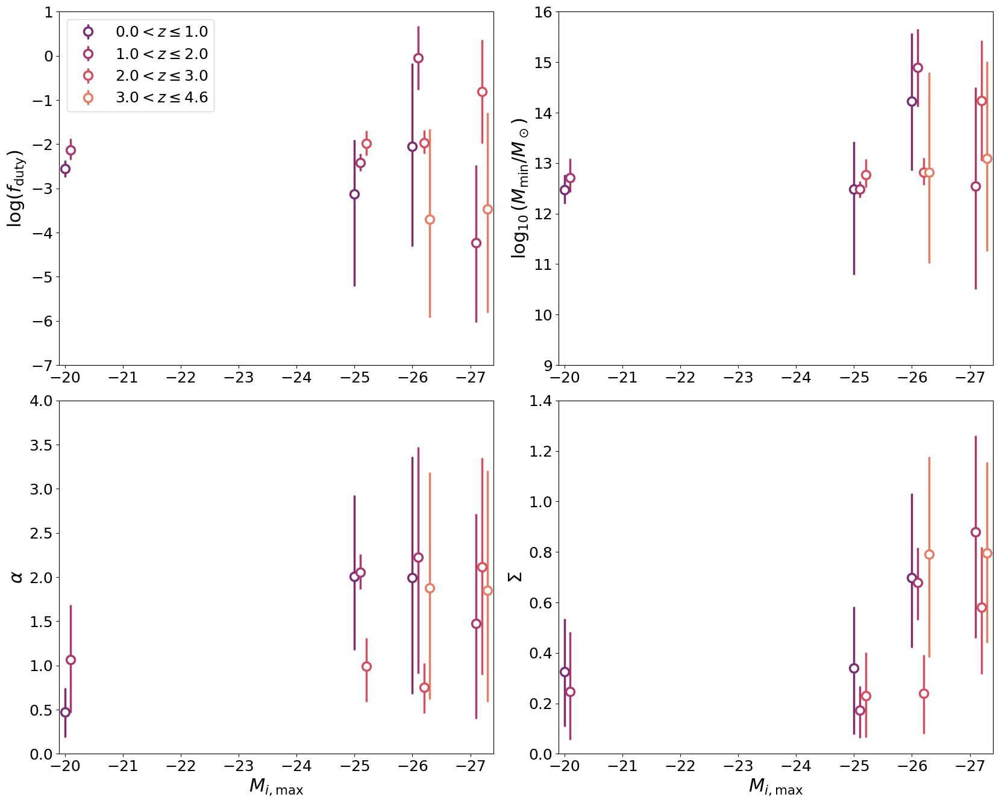

In [99]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ndim = 3
ax = [ax1, ax2, ax3, ax4]
for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            # a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
            #                 G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            # zbin = 1/a-1
            # xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]

            # quantiles = f_duty(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask)
            
            for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                ax[l].errorbar(L_bins[i]-j*0.1, mid, yerr = [[mid-lo], [hi-mid]], linestyle = 'none', marker = 'o', 
                               label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), color = cmap_theta[j], 
                               linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#,
                ax[l].set_ylabel(labels[l])
                ax[l].set_xlim(L_bins[0]+0.1, L_bins[-1]-3*0.1-0.1)
        
# ax3.set_xlabel('$z$')
# ax4.set_xlabel('$z$')
ax3.set_xlabel('$M_{i, \mathrm{max}}$')
ax4.set_xlabel('$M_{i, \mathrm{max}}$')

h, l = ax1.get_legend_handles_labels()
label, ind = np.unique(l, return_index = True)
ax1.legend([h[i] for i in ind], label)

# d = 1
# start = 12
# z_linspace = np.linspace(0,8)
# for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
#     fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
#     ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

#     ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
#                 r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_ylim(-7, 1)
ax2.set_ylim(9, 16)
ax3.set_ylim(0, 4)
ax4.set_ylim(0, 1.4)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

<>:36: SyntaxWarning: invalid escape sequence '\l'
<>:36: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6061/2145930586.py:36: SyntaxWarning: invalid escape sequence '\l'
  first_legend = ax1.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]) for j in range(len(z_array))])#, title = 'Shiferaw et al. 2026 (this work)',


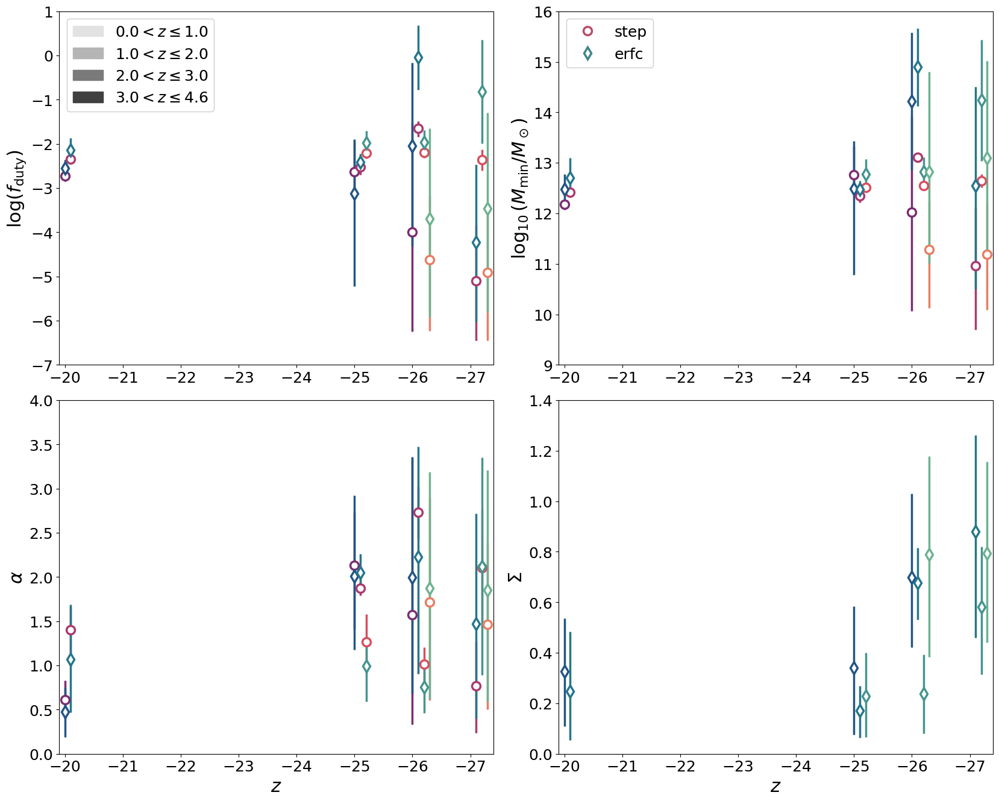

In [100]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ax = [ax1, ax2, ax3, ax4]

for k, ndim in enumerate(ndim_array):
    
    for i in range(len(L_bins)):    
    
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                # a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                #                 G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
                # zbin = 1/a-1
                # xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]
    
                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[k], log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                
                for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                    ax[l].errorbar(L_bins[i]-j*0.1, mid, yerr = [[mid-lo], [hi-mid]], linestyle = 'none', marker = marker[k], 
                                   color = cmaps[k][j], linewidth = linewidth[k], markeredgewidth = linewidth[k], 
                                   markerfacecolor = 'white', markersize = 10)#,
                    ax[l].set_ylabel(labels[l])
                    ax[l].set_xlim(L_bins[0]+0.1, L_bins[-1]-3*0.1-0.1)
        
ax3.set_xlabel('$z$')
ax4.set_xlabel('$z$')

custom_lines = [mpatches.Patch(color=sns.color_palette("Greys", n_colors = len(L_bins))[i]) for i in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]) for j in range(len(z_array))])#, title = 'Shiferaw et al. 2026 (this work)',
fig.add_artist(first_legend)

custom_lines = [Line2D([0], [0], color = np.mean(cmaps[l], axis = 0), linestyle = 'None', marker = marker[l],
                       markeredgewidth = linewidth[l], markersize = 10, linewidth = linewidth[l], markerfacecolor = 'white') 
                for l in range(len(ndim_array))]
second_legend = ax2.legend(custom_lines, ['step', 'erfc'])
fig.add_artist(second_legend)

# d = 1
# start = 12
# z_linspace = np.linspace(0,8)
# for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
#     fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
#     ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

#     ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
#                 r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,16)
ax3.set_ylim(0, 4)
ax4.set_ylim(0, 1.4)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

# Null test

In [66]:
a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))
a

0.2333617976257798

In [67]:
k = 1
ndim = 3
j = 3
i = 3
chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, Sigma = Sigma[k], 
                               a = a)

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-5.81287482 -3.46878975 -1.2882099 ]
 [11.26206944 13.09675863 15.01309374]
 [ 0.58957717  1.8518656   3.20665239]
 [ 0.4405614   0.79470097  1.15640942]]


(15.411270011829222,
 array([-3.46878975, 13.09675863,  1.8518656 ,  0.79470097]))

In [74]:
ix_grid = np.ix_(theta_mask, theta_mask)

In [75]:
chi2_L_z = {ndim: [] for ndim in ndim_array}
df_L_z = {}
# Sigma = [0, None]
for k, ndim in enumerate(ndim_array):

    print('ndim: {}'.format(ndim))
    df_L_z[ndim] = nbins_mask-ndim #-1

    for i in range(len(L_bins)):
    
        print('M_i<={}'.format(L_bins[i]))
    
        chi2_z=[]
        
        for j in z_array:
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            
                print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
                # x = [median[err_label][L_bins[i][j]] for err_label in err_labels[1:]] #[M_min[L_bins[i]][j]]
                
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
                if diag == True:
                    C*=np.identity(len(C))

                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))
                
                chi_2, x = chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, Sigma = Sigma[k], 
                               a = a, theta_mask = theta_mask)
                # df_L_z = nbins_mask-ndim #-1
            
                print('           chi^2: {:.2f}'.format(chi_2))
                print('   reduced chi^2: {:.2f}'.format(chi_2/df_L_z[ndim]))
                print('         delta n: {:.2e}'.format(constraint(x, a, n_q[L_bins[i]][j]))) #, fduty = f_duty[L_bins[i]][j])))
                try:
                    print('condition number: {:.2f}'.format(np.linalg.cond(C[ix_grid])))
                except Exception as e:
                    print(e)
                print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi_2, df_L_z[ndim])))
    
            else:
                chi_2=np.nan
    
            chi2_z.append(chi_2)
            
        chi2_L_z[ndim].append(chi2_z)

ndim: 2
M_i<=-20.0
0.0<z<=1.0


/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))


[[-2.84393376 -2.72588236 -2.60475851]
 [12.07265009 12.1747504  12.28182419]
 [ 0.39365098  0.61190528  0.82761226]]
           chi^2: 49.53
   reduced chi^2: 2.48
         delta n: 2.75e-02
condition number: 1559678.57
             PTE: 0.00

1.0<z<=2.0
[[-2.4523477  -2.34020676 -2.24469595]
 [12.32994378 12.42065887 12.50303763]
 [ 1.05837718  1.40077738  1.66728631]]
           chi^2: 166.67
   reduced chi^2: 8.33
         delta n: 2.82e-02
condition number: 1766017.03
             PTE: 0.00

M_i<=-25.0
0.0<z<=1.0
[[-3.1445667  -2.63986514 -1.92419348]
 [12.39664459 12.76301543 13.32418083]
 [ 1.40670963  2.13283878  2.73331896]]
           chi^2: 29.00
   reduced chi^2: 1.45
         delta n: -6.91e-02
condition number: 6492632.87
             PTE: 0.09

1.0<z<=2.0
[[-2.70475612 -2.52875333 -2.33623391]
 [12.21976646 12.34883193 12.47774023]
 [ 1.7902268   1.86971436  1.95095108]]
           chi^2: 37.83
   reduced chi^2: 1.89
         delta n: 8.76e-03
condition number: 2024582.0

In [76]:
chi_2, x = chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, Sigma = Sigma[k], 
                               a = a, i_null = 0)

[[-5.98780795 -3.77914776 -1.69325501]
 [11.08503442 12.87253807 14.86374314]
 [ 0.58349113  1.86147374  3.20318863]
 [ 0.38992301  0.78445664  1.1555892 ]]


In [77]:
chi2_null = {ndim: [] for ndim in ndim_array}
# df_null = {}
# Sigma = [0, None]
df_null = nbins_mask #-1
for k, ndim in enumerate(ndim_array):

    print('ndim: {}'.format(ndim))
    # df_null = nbins_mask #-1

    for i in range(len(L_bins)):
    
        print('M_i<={}'.format(L_bins[i]))
    
        chi2_z=[]
        
        for j in z_array:
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            
                print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
                
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
                if diag == True:
                    C*=np.identity(len(C))

                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))
                
                chi_2, x = chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, Sigma = Sigma[k], 
                               a = a, i_null = 0, theta_mask = theta_mask)
            
                print('           chi^2: {:.2f}'.format(chi_2))
                print('   reduced chi^2: {:.2f}'.format(chi_2/df_null))
                print('         delta n: {:.2e}'.format(constraint(x, a, n_q[L_bins[i]][j]))) #, fduty = f_duty[L_bins[i]][j])))
                try:
                    print('condition number: {:.2f}'.format(np.linalg.cond(C[ix_grid])))
                except Exception as e:
                    print(e)
                print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi_2, df_null)))
    
            else:
                chi_2=np.nan
    
            chi2_z.append(chi_2)
            
        chi2_null[ndim].append(chi2_z)

ndim: 2
M_i<=-20.0
0.0<z<=1.0
[[-2.84354762 -2.72712705 -2.60651471]
 [12.07265009 12.1747504  12.28182419]
 [ 0.39365098  0.61190528  0.82761226]]
           chi^2: 49.53
   reduced chi^2: 2.25
         delta n: 2.47e-02
condition number: 1559678.57
             PTE: 0.00

1.0<z<=2.0
[[-2.45238361 -2.34055002 -2.24467248]
 [12.32994378 12.42065887 12.50303763]
 [ 1.05837718  1.40077738  1.66728631]]
           chi^2: 166.67
   reduced chi^2: 7.58
         delta n: 2.90e-02
condition number: 1766017.03
             PTE: 0.00

M_i<=-25.0
0.0<z<=1.0
[[-3.54045149 -3.41932731 -3.29553426]
 [12.07265009 12.1747504  12.28182419]
 [ 0.39365098  0.61190528  0.82761226]]
           chi^2: 69.69
   reduced chi^2: 3.17
         delta n: 2.69e-02
condition number: 6492632.87
             PTE: 0.00

1.0<z<=2.0
[[-2.54986436 -2.43584177 -2.33766938]
 [12.32994378 12.42065887 12.50303763]
 [ 1.05837718  1.40077738  1.66728631]]
           chi^2: 146.10
   reduced chi^2: 6.64
         delta n: 2.74e-

In [78]:
L_array = np.array([-32, -27, -26, -25, -20])[::-1]

<>:11: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_28477/3909057341.py:11: SyntaxWarning: invalid escape sequence '\D'
  fig.colorbar(image, label = '$\Delta\chi^2$')
/tmp/ipykernel_28477/3909057341.py:15: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')


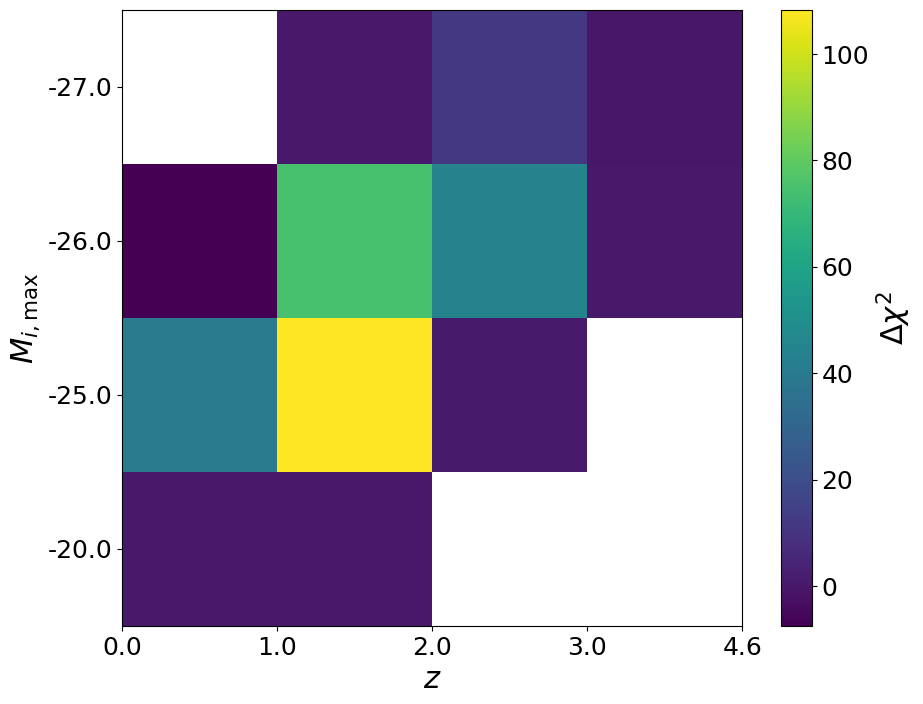

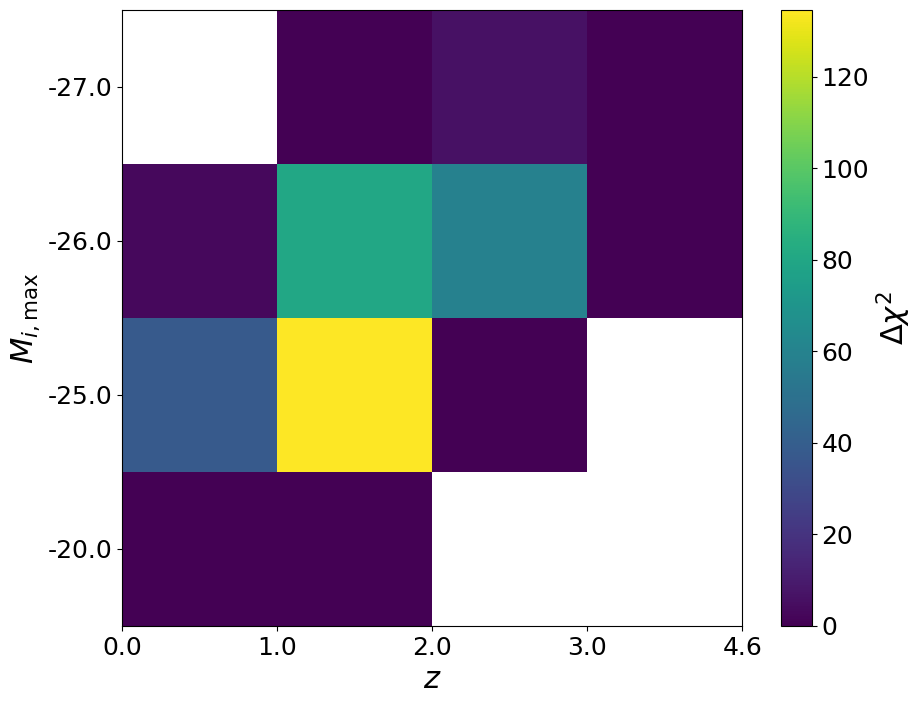

In [79]:
chi2_delta = {}
for k, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (10, 8))
    gs = gridspec.GridSpec(1, 1)
    ax1 = fig.add_subplot(gs[0])

    chi2_delta[ndim] = chi2_null[ndim]-np.array(chi2_L_z[ndim])
    image = plt.pcolormesh(chi2_delta[ndim])
    
    fig.colorbar(image, label = '$\Delta\chi^2$')
    ax1.set_xticks(range(len(z_bins)), labels = z_bins)
    ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
    ax1.set_xlabel('$z$')
    ax1.set_ylabel('$M_{i,\mathrm{max}}$')
    plt.show()

In [80]:
cmap_chi2 = sns.color_palette("vlag", as_cmap=True)

In [81]:
cmap_chi2.set_bad('lightgray')

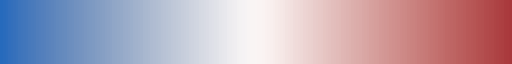

In [82]:
cmap_M_min = sns.color_palette("vlag", n_colors = len(bins_m))
palette_M_min = matplotlib.colors.ListedColormap(cmap_M_min)
palette_M_min

<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_28477/2598778136.py:22: SyntaxWarning: invalid escape sequence '\s'
  fig.colorbar(image, label = '$N\sigma$')
/tmp/ipykernel_28477/2598778136.py:26: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')


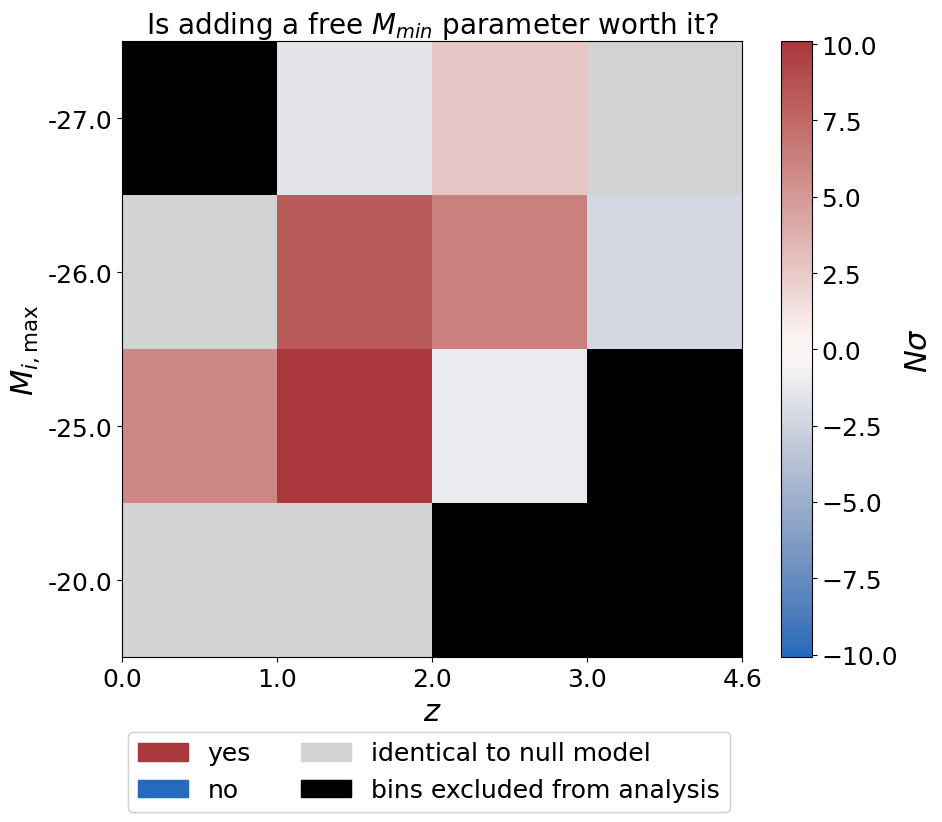

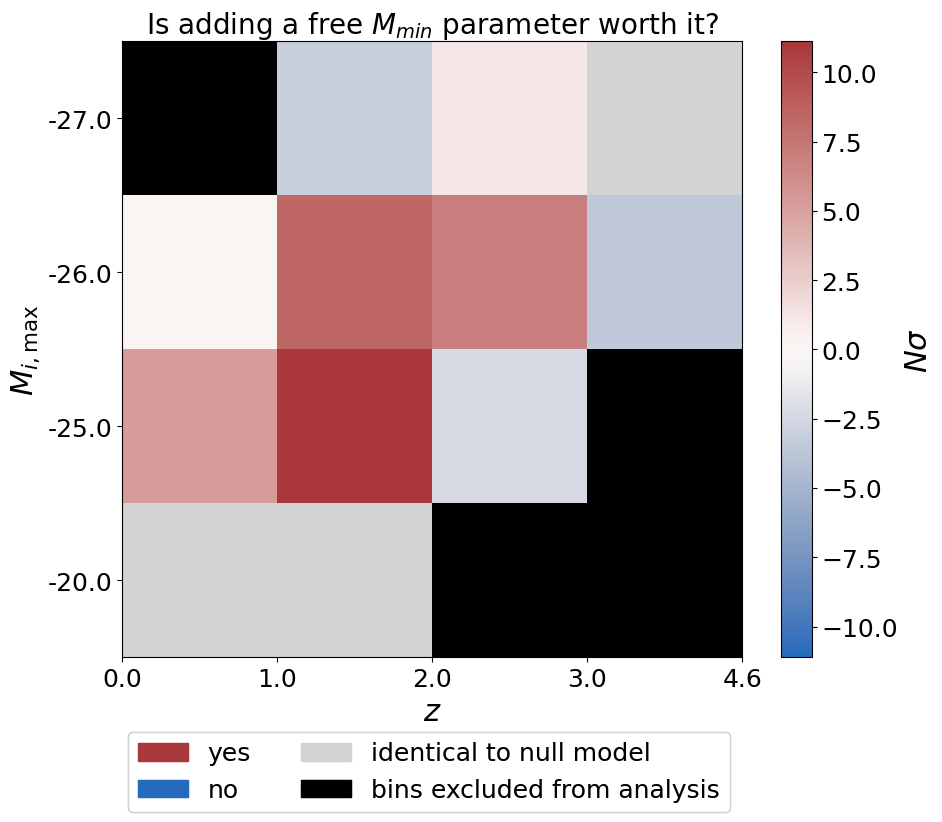

In [83]:
for k, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (10, 8))
    gs = gridspec.GridSpec(1, 1)
    ax1 = fig.add_subplot(gs[0])

    eps = 1e-8  # tolerance — anything below this is "zero" for your purposes
    chi2_delta_clean = np.where(np.abs(chi2_delta[ndim]) < eps, 0.0, chi2_delta[ndim])

    p_value = stats.chi2.sf(chi2_delta_clean, df_null-df_L_z[ndim])
    # print(df_null-df_L_z[ndim])
    # print(p_value)
    n_sigma_delta = stats.norm.isf(p_value)
    # print(n_sigma_delta)
    
    vlim = max(np.max(n_sigma_delta[np.isfinite(n_sigma_delta)]), np.min(np.abs(n_sigma_delta[np.isfinite(n_sigma_delta)])))
    image = ax1.pcolormesh(n_sigma_delta, vmin = -vlim, vmax = vlim, cmap = cmap_chi2)
    
    nan_overlay = np.where(np.isnan(n_sigma_delta), 1.0, np.nan)
    ax1.pcolormesh(nan_overlay, cmap=plt.cm.colors.ListedColormap(['black']), vmin=0, vmax=1)
    
    fig.colorbar(image, label = '$N\sigma$')
    ax1.set_xticks(range(len(z_bins)), labels = z_bins)
    ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
    ax1.set_xlabel('$z$')
    ax1.set_ylabel('$M_{i,\mathrm{max}}$')
    ax1.set_title('Is adding a free $M_{min}$ parameter worth it?')
    custom_lines = [mpatches.Patch(color=cmap_M_min[-1]), mpatches.Patch(color=cmap_M_min[0]), mpatches.Patch(color='lightgray'), 
                    mpatches.Patch(color='black')]
    first_legend = plt.legend(custom_lines, [r'yes', 'no', 'identical to null model', 
                                             'bins excluded from analysis'], bbox_to_anchor=(0.5, -0.6, 0.5, 0.5), ncol =2)
    fig.add_artist(first_legend)
    
    # plt.savefig('../figures/null_test.pdf', bbox_inches = 'tight')
    plt.show()

<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_28477/548632175.py:34: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')
/tmp/ipykernel_28477/548632175.py:39: SyntaxWarning: invalid escape sequence '\s'
  fig.colorbar(image, label = '$N\sigma$', cax = fig.add_subplot(gs[-1]))


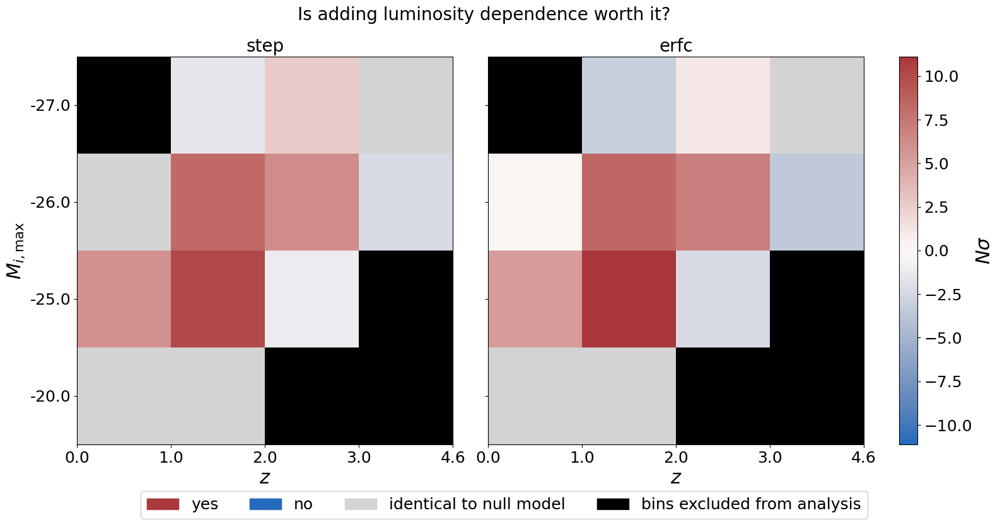

In [86]:
fig = plt.figure(figsize = (17.2, 8))
gs = gridspec.GridSpec(1, 5, wspace = 0.05, width_ratios = [1, 0.05, 1, 0.05, 0.05])
titles = ['step', 'erfc']
# ax1 = fig.add_subplot(gs[0])

eps = 1e-8  # tolerance — anything below this is "zero" for your purposes
vlim = []
n_sigma_delta={}
for k, ndim in enumerate(ndim_array):

    chi2_delta_clean = np.where(np.abs(chi2_delta[ndim]) < eps, 0.0, chi2_delta[ndim])

    p_value = stats.chi2.sf(chi2_delta_clean, df_null-df_L_z[ndim])
    n_sigma_delta[ndim] = stats.norm.isf(p_value)
    
    vlim.append(max(np.max(n_sigma_delta[ndim][np.isfinite(n_sigma_delta[ndim])]), 
                    np.min(np.abs(n_sigma_delta[ndim][np.isfinite(n_sigma_delta[ndim])]))))
    # print(vlim)

for k, ndim in enumerate(ndim_array):

    ax1 = fig.add_subplot(gs[k+k])

    image = ax1.pcolormesh(n_sigma_delta[ndim], vmin = -np.max(vlim), vmax = np.max(vlim), cmap = cmap_chi2)
    
    nan_overlay = np.where(np.isnan(n_sigma_delta[ndim]), 1.0, np.nan)
    ax1.pcolormesh(nan_overlay, cmap=plt.cm.colors.ListedColormap(['black']), vmin=0, vmax=1)
    
    # fig.colorbar(image, label = '$N\sigma$')
    ax1.set_xticks(range(len(z_bins)), labels = z_bins)
    ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
    ax1.set_xlabel('$z$')
    if k == 0:
        ax1.set_ylabel('$M_{i,\mathrm{max}}$')
    else:
        ax1.set_yticklabels([])
    ax1.set_title(titles[k])

fig.colorbar(image, label = '$N\sigma$', cax = fig.add_subplot(gs[-1]))

custom_lines = [mpatches.Patch(color=cmap_M_min[-1]), mpatches.Patch(color=cmap_M_min[0]), mpatches.Patch(color='lightgray'), 
                mpatches.Patch(color='black')]
first_legend = plt.legend(custom_lines, [r'yes', 'no', 'identical to null model', 
                                         'bins excluded from analysis'], bbox_to_anchor=(-0.5, -0.6, -0.75, 0.5), ncol =4)
fig.add_artist(first_legend)

    # plt.savefig('../figures/null_test.pdf', bbox_inches = 'tight')
# plt.suptitle('Is adding a free $M_{min}$ parameter worth it?', fontsize = 20)
plt.suptitle('Is adding luminosity dependence worth it?', fontsize = 20)

plt.savefig('../figures/null_test_step_erfc_2.pdf', bbox_inches = 'tight')
plt.show()

# Best-fit HOD model

In [ ]:
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
    
        ax1 = fig.add_subplot(gs[j])
    
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = '$M_i\leq{}$'.format(L_bins[i]), 
                         color = cmap_theta[i])
                         # label = r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', color = cmap_theta[i])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmap_theta[i]) #color = cmap_theta[i], 
                ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmap_theta[i])

                ax1.legend()

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_yscale('log')
            ax1.set_xlim(9, M_max)
            ax1.set_ylim(2e-7, 2e1)
            
            if j%2==0:
                ax1.set_ylabel(r'$\langle N(M) \rangle$')
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

    custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
    first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                             r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0), loc = 'lower right')
    fig.add_artist(first_legend)
    
    plt.show()

In [ ]:
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for i in range(len(L_bins)):

        ax1 = fig.add_subplot(gs[i])
    
        for j in range(len(z_array)):

            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-',
                         label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), color = cmap_theta[j])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmap_theta[j]) #color = cmap_theta[i], 
                ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmap_theta[j])

                ax1.legend()

            ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_yscale('log')
            ax1.set_xlim(9, M_max)
            ax1.set_ylim(2e-7, 2e1)
            
            if i%2==0:
                ax1.set_ylabel(r'$\langle N(M) \rangle$')
            else:
                ax1.set_yticks([])
            if i > 1:
                ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

    custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
    first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                             r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0), loc = 'lower right')
    fig.add_artist(first_legend)
    
    plt.show()

In [ ]:
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
    
        ax1 = fig.add_subplot(gs[j])
    
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = '$M_i\leq{}$'.format(L_bins[i]), 
                         color = cmap_theta[i])
                # ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmap_theta[i]) #color = cmap_theta[i], 
                # ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmap_theta[i])

                ax1.legend()

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_yscale('log')
            ax1.set_xlim(9, M_max)
            ax1.set_ylim(2e-7, 2e1)
            
            if j%2==0:
                ax1.set_ylabel(r'$\langle N(M) \rangle$')
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

    # custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
    #                 Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
    #                 Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
    # first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
    #                                          r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
    #                           bbox_to_anchor=(0.0, 0.0), loc = 'lower right')
    # fig.add_artist(first_legend)
    
    plt.show()

In [ ]:
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for i in range(len(L_bins)):

        ax1 = fig.add_subplot(gs[i])
    
        for j in range(len(z_array)):

            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1],
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-',
                         label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), color = cmap_theta[j])
                # ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmap_theta[i]) #color = cmap_theta[i], 
                # ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmap_theta[i])

                ax1.legend()

            ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_yscale('log')
            ax1.set_xlim(9, M_max)
            ax1.set_ylim(2e-7, 2e1)
            
            if i%2==0:
                ax1.set_ylabel(r'$\langle N(M) \rangle$')
            else:
                ax1.set_yticks([])
            if i > 1:
                ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

    # custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
    #                 Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
    #                 Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
    # first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
    #                                          r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
    #                           bbox_to_anchor=(0.0, 0.0), loc = 'lower right')
    # fig.add_artist(first_legend)
    
    plt.show()

In [ ]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            for l, ndim in enumerate(ndim_array):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim,
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = '$M_i\leq{}$'.format(L_bins[i]),
                         color = cmaps[l][i])

                # ax1.legend()

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(9, M_max)
    ax1.set_ylim(2e-7, 2e1)
    
    if j%2==0:
        ax1.set_ylabel(r'$\langle N(M) \rangle$')
    else:
        ax1.set_yticks([])
    if j > 1:
        ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

custom_lines = [Line2D([0], [0], color = sns.color_palette("Greys", n_colors = len(L_bins))[i], linestyle = '-', linewidth = 2.5)
                for i in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, ['$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])#, title = 'Shiferaw et al. 2026 (this work)',
fig.add_artist(first_legend)

custom_lines = [mpatches.Patch(color=np.mean(cmaps[l], axis = 0)) for l in range(len(ndim_array))]
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'lower right')
fig.add_artist(second_legend)
    
plt.show()

In [ ]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
# remove bottom panel and just print bq somewhere
# plot!
for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i])

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            for l, ndim in enumerate(ndim_array):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim,
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1],
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = '$M_i\leq{}$'.format(L_bins[i]),
                         color = cmaps[l][j])

    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
    ax1.set_yscale('log')
    ax1.set_xlim(9, M_max)
    ax1.set_ylim(2e-7, 2e1)
    
    if i%2==0:
        ax1.set_ylabel(r'$\langle N(M) \rangle$')
    else:
        ax1.set_yticks([])
    if i > 1:
        ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

custom_lines = [Line2D([0], [0], color = sns.color_palette("Greys", n_colors = len(L_bins))[i], linestyle = '-', linewidth = 2.5)
                for i in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]) for j in range(len(z_array))])#, title = 'Shiferaw et al. 2026 (this work)',
fig.add_artist(first_legend)

custom_lines = [mpatches.Patch(color=np.mean(cmaps[l], axis = 0)) for l in range(len(ndim_array))]
second_legend = ax1.legend(custom_lines, ['step', 'erfc'], loc = 'lower right')
fig.add_artist(second_legend)
    
plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i])

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1],
                    quantiles[ndim][L_bins[i]][j][:,1][2])

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = label+sigma, color = cmap_theta[i])
                         # label = r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', color = cmap_theta[i])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmap_theta[i])
                         # label = r'$\langle N_c(M) \rangle$') #color = cmap_theta[i], 
                ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmap_theta[i])
                         # label = r'$\langle N_s(M) \rangle$')

                if j==0 or ((j == 1) and  (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticks([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')
                
                ax1.legend()
                
    custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
    first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                             r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0), loc = 'lower right')
    fig.add_artist(first_legend)
            
    plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

    for i in range(len(L_bins)):
        
        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[i*4+j])

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1],
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = label+sigma, color = cmap_theta[j])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmap_theta[j])
                ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmap_theta[j])

                if i ==0 or ((i<3) and (j>1) and (i!=j)):
                    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if j==0:
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{M_i\leq{}}}$'.format(L_bins[i]))
                else:
                    ax1.set_yticks([])
                if i > 2 or ((i == 2) and (j == 0)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')
                
                ax1.legend()
                
    custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
    first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                             r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0), loc = 'upper right')
    fig.add_artist(first_legend)
            
    plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            for l, ndim in enumerate(ndim_array):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim,
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1],
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = label+sigma, color = cmaps[l][i])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmaps[l][i])
                ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmaps[l][i])

                if j==0 or ((j == 1) and  (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticks([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')
                
            ax1.legend()

custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                         r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(1.0, 1.0), loc = 'upper right')
fig.add_artist(first_legend)

# custom_lines = [mpatches.Patch(color=np.mean(cmaps[l], axis = 0)) for l in range(len(ndim_array))]
# second_legend = ax1.legend(custom_lines, ['step', 'erfc'])
# fig.add_artist(second_legend)

plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
        
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j])

            for l, ndim in enumerate(ndim_array):

                # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = label+sigma, color = cmaps[l][j])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmaps[l][j])
                ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmaps[l][j])

                if i ==0 or ((i<3) and (j>1) and (i!=j)):
                    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if j==0:
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{M_i\leq{}}}$'.format(L_bins[i]))
                else:
                    ax1.set_yticks([])
                if i > 2 or ((i == 2) and (j == 0)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

            ax1.legend()

custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                         r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(1.0, 1.0), loc = 'upper right')
fig.add_artist(first_legend)

# custom_lines = [mpatches.Patch(color=np.mean(cmaps[l], axis = 0)) for l in range(len(ndim_array))]
# second_legend = ax1.legend(custom_lines, ['step', 'erfc'])
# fig.add_artist(second_legend)

plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            for l, ndim in enumerate(ndim_array):

                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim,
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1],
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = label+sigma, color = cmaps[l][i])
                # ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmaps[l][i])
                # ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmaps[l][i])

                if j==0 or ((j == 1) and  (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticks([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')
                
            ax1.legend()

# custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
#                     Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
#                     Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
# first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
#                                          r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
#                               bbox_to_anchor=(1.0, 1.0), loc = 'upper right')
# fig.add_artist(first_legend)

plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
        
for i in range(len(L_bins)):
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j])

            for l, ndim in enumerate(ndim_array):

                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = label+sigma, color = cmaps[l][j])
                # ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmaps[l][j])
                # ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmaps[l][j])

                if i ==0 or ((i<3) and (j>1) and (i!=j)):
                    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if j==0:
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{M_i\leq{}}}$'.format(L_bins[i]))
                else:
                    ax1.set_yticks([])
                if i > 2 or ((i == 2) and (j == 0)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

            ax1.legend()

# custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
#                     Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
#                     Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
# first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
#                                          r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
#                               bbox_to_anchor=(1.0, 1.0), loc = 'upper right')
# fig.add_artist(first_legend)

plt.show()

### Explore weird bump

In [ ]:
l = 1
ndim = 3
j = 0
l = 0
i = 0
M0_label = ['$M_0=M_\mathrm{min}$', '$M_0<M_\mathrm{min}$', '$M_0>M_\mathrm{min}$']
color = cmap_theta[i], 'red', 'orange'

fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
# for j in range(len(z_array)):

ax1 = fig.add_subplot(gs[j])

    # for i in range(len(L_bins)):

if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

    # quantiles = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)

    for k, M0 in enumerate([10**quantiles[ndim][L_bins[i]][j][:,1][1], 0.1*10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                            10*10**quantiles[ndim][L_bins[i]][j][:,1][1]]):
        
        if ndim == 3:
            n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                            sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
        else:
            n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
        n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], M0, 
                          12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
        ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = M0_label[k], 
                 color = color[k])
                 # label = r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', color = cmap_theta[i])
        ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = color[k]) #color = cmap_theta[i], 
        ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = color[k])

    ax1.legend()

ax1.set_title('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]))
ax1.set_yscale('log')
ax1.set_xlim(9, M_max)
ax1.set_ylim(2e-7, 2e1)

if j%2==0:
    ax1.set_ylabel(r'$\langle N(M) \rangle$')
else:
    ax1.set_yticks([])
# if j > 1:
ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                         r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                          bbox_to_anchor=(0.0, 0.0), loc = 'lower left')
fig.add_artist(first_legend)

plt.show()

In [ ]:
l = 1
ndim = 3
j = 0
l = 0
i = 0
M0_label = ['$M_0=M_\mathrm{min}$', '$M_0<M_\mathrm{min}$', '$M_0>M_\mathrm{min}$']
color = cmap_theta[i], 'red', 'orange'

fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
ax1 = fig.add_subplot(gs[j])

if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

    for k, alpha in enumerate([quantiles[ndim][L_bins[i]][j][:,1][2], 2*quantiles[ndim][L_bins[i]][j][:,1][2]]):
        
        if ndim == 3:
            n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                            sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
        else:
            n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
        n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                          12*10**quantiles[ndim][L_bins[i]][j][:,1][1], alpha)
    
        ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 2.5, linestyle = '-', label = r'$\alpha={:.2f}$'.format(alpha), 
                 color = color[k])
        ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = color[k]) #color = cmap_theta[i], 
        ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = color[k])

    ax1.legend()

ax1.set_title('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]))
ax1.set_yscale('log')
ax1.set_xlim(9, M_max)
ax1.set_ylim(2e-7, 2e1)

if j%2==0:
    ax1.set_ylabel(r'$\langle N(M) \rangle$')
else:
    ax1.set_yticks([])

ax1.set_xlabel('$\log_{10} (M/M_\odot)$')

custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                         r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                          bbox_to_anchor=(0.0, 0.0), loc = 'lower left')
fig.add_artist(first_legend)

plt.show()

# Plot the fit to the model

In [ ]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

In [ ]:
# wp_2h_16, wp_2h_50, wp_2h_84 = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
# for l, ndim in enumerate(ndim_array):
    
#     # remove bottom panel and just print bq somewhere
#     # plot!
#     for j in range(len(z_array)):
    
#         # ax1 = fig.add_subplot(gs[j])
    
#         for i in range(len(L_bins)):
    
#             if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
#                 if ndim == 3:
#                     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,-1]
#                 else:
#                     sigma = np.zeros(np.shape(equal_weight_samples[ndim][L_bins[i]][j][:,-1]))
                
#                 wp_2h_samples=[]
#                 for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
#                     # n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
#                     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma[k], np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
#                                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
#                                                              theta_mask = theta_mask)
#                     wp_2h_samples.append(wp_2h_sample)
#                 w_2h_16, w_2h_50, w_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

#                 # wp_2h_50 = np.mean(wp_2h_samples)
#                 wp_2h_50[ndim][L_bins[i]].append(np.mean(wp_2h_samples, axis = 0))
#                 wp_2h_16[ndim][L_bins[i]].append(w_2h_16)
#                 wp_2h_84[ndim][L_bins[i]].append(w_2h_84)

#             else:
#                 wp_2h_50[ndim][L_bins[i]].append(np.nan)
    
#     # plt.show()

In [ ]:
# for l, ndim in enumerate(ndim_array):
    
#     # remove bottom panel and just print bq somewhere
#     # plot!
#     for j in range(len(z_array)):
        
#         for i in range(len(L_bins)):
    
#             if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
#                 if ndim == 3:
#                     label_Sigma= ''
#                 else:
#                     label_Sigma = '_Sigma0.0'

#                 file = '_zmin{}zmax{}_Lmax{}_ndim{}{}'.format(z_bins[j], z_bins[j+1], L_bins[i], ndim, label_Sigma) 

#                 np.save('../results/results_wtheta_mean{}.npy'.format(file), wp_2h_50[ndim][L_bins[i]][j])
#                 np.save('../results/results_wtheta_16{}.npy'.format(file), wp_2h_16[ndim][L_bins[i]][j])
#                 np.save('../results/results_wtheta_84{}.npy'.format(file), wp_2h_84[ndim][L_bins[i]][j])

In [ ]:
wp_2h_16, wp_2h_50, wp_2h_84 = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for l, ndim in enumerate(ndim_array):
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
                if ndim == 3:
                    sigma = equal_weight_samples[ndim][L_bins[i]][j][:,-1]
                    label_Sigma= ''
                else:
                    sigma = np.zeros(np.shape(equal_weight_samples[ndim][L_bins[i]][j][:,-1]))
                    label_Sigma = '_Sigma0.0'

                file = '_zmin{}zmax{}_Lmax{}_ndim{}{}'.format(z_bins[j], z_bins[j+1], L_bins[i], ndim, label_Sigma) 

                try:

                    w_mean = np.load('../results/results_wtheta_mean{}.npy'.format(file))
                    w_2h_16 = np.load('../results/results_wtheta_16{}.npy'.format(file))
                    w_2h_84 = np.load('../results/results_wtheta_84{}.npy'.format(file))

                except:
                
                    wp_2h_samples=[]
                    for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                        # n_m=np.ones(np.shape(bins_m))*10**equal_weight_samples[ndim][L_bins[i]][j][:,0][k]
                        wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma[k], np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                                                                                                         equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, recenter_thetabins = False)
                                                                 # theta_mask = theta_mask)
                        wp_2h_samples.append(wp_2h_sample)
                    w_2h_16, w_2h_50, w_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

                    w_mean = np.mean(wp_2h_samples, axis = 0)

                    np.save('../results/results_wtheta_mean{}.npy'.format(file), w_mean)
                    np.save('../results/results_wtheta_16{}.npy'.format(file), w_2h_16)
                    np.save('../results/results_wtheta_84{}.npy'.format(file), w_2h_84)

                wp_2h_50[ndim][L_bins[i]].append(w_mean)
                wp_2h_16[ndim][L_bins[i]].append(w_2h_16)
                wp_2h_84[ndim][L_bins[i]].append(w_2h_84)
                
            else:
                
                wp_2h_50[ndim][L_bins[i]].append(np.nan)
                wp_2h_16[ndim][L_bins[i]].append(np.nan)
                wp_2h_84[ndim][L_bins[i]].append(np.nan)

In [ ]:
xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim) 
ylim = 1e-5, 2e2
y = np.linspace(ylim[0], ylim[-1])
# wp_2h_16, wp_2h_50, wp_2h_84 = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
    
        ax1 = fig.add_subplot(gs[j])
    
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     # label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                #     # label_Sigma= ''
                # else:
                #     # label_sigma =  r')$'
                #     sigma = 0
                #     # label_Sigma = '_Sigma0.0'
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # w_2h_16, w_2h_50, w_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

                # # wp_2h_50 = np.mean(wp_2h_samples)
                # wp_2h_50[ndim][L_bins[i]].append(np.mean(wp_2h_samples, axis = 0))
                # wp_2h_16[ndim][L_bins[i]].append(w_2h_16)
                # wp_2h_84[ndim][L_bins[i]].append(w_2h_84)
  
                # ax1.plot(thetabins, wp_2h_50, linewidth = 2.5, label = '$M_i\leq{}$'.format(L_bins[i]), color = cmap_theta[i])
                # ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = '$M_i\leq{}$'.format(L_bins[i]), color = cmap_theta[i])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])

            # else:
            #     wp_2h_50[ndim][L_bins[i]].append(np.nan)

        ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
        
        if j%2==0:
            ax1.set_ylabel(r'$w(\theta)$')
        else:
            ax1.set_yticks([])
        if j > 1:
            ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

        ax1.set_xlim(xlim)
        ax1.set_ylim(ylim)

        ax1.set_xscale('log')
        ax1.set_yscale('log')
            
        ax1.legend()
    
    plt.show()

In [ ]:
# xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim) 
# ylim = 1e-5, 2e2
# y = np.linspace(ylim[0], ylim[-1])
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for i in range(len(L_bins)):
        
        ax1 = fig.add_subplot(gs[i])

        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     # label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                #     # label_Sigma= ''
                # else:
                #     # label_sigma =  r')$'
                #     sigma = 0
                #     # label_Sigma = '_Sigma0.0'
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    
                # wp_2h_50 = np.mean(wp_2h_samples)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), color = cmap_theta[j])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmap_theta[j])

        ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
        
        if j%2==0:
            ax1.set_ylabel(r'$w(\theta)$')
        else:
            ax1.set_yticks([])
        if j > 1:
            ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

        ax1.set_xlim(xlim)
        ax1.set_ylim(ylim)

        ax1.set_xscale('log')
        ax1.set_yscale('log')
            
        ax1.legend()
    
    plt.show()

In [ ]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            for l, ndim in enumerate(ndim_array):
                
                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                # else:
                #     sigma = 0
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    
                # wp_2h_50 = np.mean(wp_2h_samples)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = '$M_i\leq{}$'.format(L_bins[i]), color = cmaps[l][i])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][i])

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    
    if j%2==0:
        ax1.set_ylabel(r'$w(\theta)$')
    else:
        ax1.set_yticks([])
    if j > 1:
        ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

    ax1.set_xlim(xlim)
    ax1.set_ylim(ylim)

    ax1.set_xscale('log')
    ax1.set_yscale('log')
        
    ax1.legend()
    
plt.show()

In [ ]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for i in range(len(L_bins)):
    
    ax1 = fig.add_subplot(gs[i])

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            for l, ndim in enumerate(ndim_array):
                
                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                # else:
                #     sigma = 0
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    
                # wp_2h_50 = np.mean(wp_2h_samples)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), color = cmaps[l][j])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][j])

    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
    
    if j%2==0:
        ax1.set_ylabel(r'$w(\theta)$')
    else:
        ax1.set_yticks([])
    if j > 1:
        ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

    ax1.set_xlim(xlim)
    ax1.set_ylim(ylim)

    ax1.set_xscale('log')
    ax1.set_yscale('log')
        
    ax1.legend()
    
plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
# xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim) 
# ylim = 1e-5, 2e2
# y = np.linspace(ylim[0], ylim[-1])
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
    
    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i])

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     # n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim,
                #     #                 sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                #     label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                #     # label_Sigma= ''
                # else:
                #     # n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                #     label_sigma =  r')$'
                #     sigma = 0
                #     # label_Sigma = '_Sigma0.0'
                # n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1],
                #                   12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)

                # file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                #     G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, label_Sigma, dlogz, 
                #     nlive, sample) 
                
                # # read the results
                # with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                #     results = pickle.load(fp)

                # samples, weights = results.samples, results.importance_weights()
                # equal_weight_samples = dyfunc.resample_equal(samples, weights)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    
                # wp_2h_50 = np.mean(wp_2h_samples)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label+label_sigma, color = cmap_theta[i])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
                
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_xlim(xlim)
                ax1.set_ylim(ylim)
                # ax1.legend()
                
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            
                if j > 2 or ((j>0) and (i<2) and (i!=j)):
                    ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
    
                ax1.set_xscale('log')
                ax1.set_yscale('log')
                    
                ax1.legend()

    plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
            
    for i in range(len(L_bins)):

        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[i*4+j])

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                #     # label_Sigma= ''
                # else:
                #     label_sigma =  r')$'
                #     sigma = 0
                #     # label_Sigma = '_Sigma0.0'
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    
                # wp_2h_50 = np.mean(wp_2h_samples)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label+label_sigma, color = cmap_theta[j])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmap_theta[j])
                
                if i ==0 or ((i<3) and (j>1) and (i!=j)):
                    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
                ax1.set_xlim(xlim)
                ax1.set_ylim(ylim)
                # ax1.legend()
                
                if j==0:
                    ax1.set_ylabel(r'$w_{{M_i\leq{}}}(\theta)$'.format(L_bins[i]))
            
                if i > 2 or ((i == 2) and (j == 0)):
                    ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
    
                ax1.set_xscale('log')
                ax1.set_yscale('log')
                    
                ax1.legend()

    plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
            ax1 = fig.add_subplot(gs[j*4+i])

            for l, ndim in enumerate(ndim_array):

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                #     # label_Sigma= ''
                # else:
                #     label_sigma =  r')$'
                #     sigma = 0
                #     # label_Sigma = '_Sigma0.0'
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    
                # wp_2h_50 = np.mean(wp_2h_samples)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label+label_sigma, color = cmaps[l][i])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][i])
                
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_xlim(xlim)
                ax1.set_ylim(ylim)
                # ax1.legend()
                
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            
                if j > 2 or ((j>0) and (i<2) and (i!=j)):
                    ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
    
                ax1.set_xscale('log')
                ax1.set_yscale('log')
                    
            ax1.legend()

plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
        
for i in range(len(L_bins)):

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
            ax1 = fig.add_subplot(gs[i*4+j])

            for l, ndim in enumerate(ndim_array):

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                # if ndim == 3:
                #     label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                #     sigma = equal_weight_samples[ndim][L_bins[i]][j][:,3]
                #     # label_Sigma= ''
                # else:
                #     label_sigma =  r')$'
                #     sigma = 0
                #     # label_Sigma = '_Sigma0.0'
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
                
                # wp_2h_samples=[]
                # for k in range(len(equal_weight_samples[ndim][L_bins[i]][j])):
                #     n_m=np.ones(np.shape(bins_m))*10**quantiles[ndim][L_bins[i]][j][:,1][0]
                #     wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma, np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                #                                                                                      equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, 
                #                                              theta_mask = theta_mask)
                #     wp_2h_samples.append(wp_2h_sample)
                # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    
                # wp_2h_50 = np.mean(wp_2h_samples)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label+label_sigma, color = cmaps[l][j])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][j])
                
                if i ==0 or ((i<3) and (j>1) and (i!=j)):
                    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
                ax1.set_xlim(xlim)
                ax1.set_ylim(ylim)
                # ax1.legend()
                
                if j==0:
                    ax1.set_ylabel(r'$w_{{M_i\leq{}}}(\theta)$'.format(L_bins[i]))
            
                if i > 2 or ((i == 2) and (j == 0)):
                    ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
    
                ax1.set_xscale('log')
                ax1.set_yscale('log')
                    
            ax1.legend()

plt.show()